The `bank_customers_satisfaction` database reports consumer satisfaction with their bank and the services it provides.

The database contains the following variables:

*   `client_id`: Client ID.
*   `client_age`: Client's age.
*   `customer_since`: The year the customer became a client of the bank.
*   `bank_account (yes/no)`: Whether the customer has a bank account with the bank.
*   `credit_card (yes/no)`: Whether the customer has a credit card with the bank.
*   `mortgage (yes/no)`: Whether the customer has a mortgage with the bank.
*   `total_number_of_products`: Number of financial products the customer holds with the bank.
*   `customer_income`: Customer's total annual income in US dollars.
*   `customer_debt`: Current amount of debt the customer owes to the bank in US dollars.
*   `city`: City where the bank branch at which the customer registered is located.
*   `bank`: Bank with which the customer holds financial products.
*   `branch`: Bank branch where the customer registered.
*   `use_of_digital_channels (High/Moderate/Low)`: Customer's level of use of digital channels.
*   `use_of_branches (High/Moderate/Low)`: Customer's level of use of the bank's physical branches.
*   `bank_service_message`: Customer's opinion regarding their overall satisfaction with the services provided by the bank.

## **Requested Report**

Working alongside the team of one of the banks represented in the database, you are expected to conduct an analysis that includes the following:

1. **`(50%)`** Create homogeneous groups of customers in the database to offer them financial products tailored to their needs. For each group, report the customers' sentiment toward their bank.

2. **`(50%)`** Analyze and classify customer opinions regarding their overall satisfaction with their bank.
    * Customer satisfaction level with their bank.
    * Main reason why customers are satisfied or dissatisfied with their bank.
    * Characterization of customer satisfaction based on other variables.

# 0 - Setup

In [ ]:
!pip install -q missingno umap-learn vaderSentiment shap wordcloud sentence-transformers -U kaleido

## 0.2 - Imports and configuration

In [ ]:
# --- Standard library ---
import warnings, random, re, hashlib, json
from pathlib import Path

# --- Data & visualization ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.io as pio
# kaleido v1 renders images through Chrome: download a headless copy once per session
import kaleido
kaleido.get_chrome_sync()

# --- Colab ---
from google.colab import drive
drive.mount("/content/drive", force_remount=True)

warnings.filterwarnings("ignore")

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Display options
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_colwidth", 120)

# Validated palettes (colorblind-safe, readable on white)
# Sentiment = diverging: blue (positive) <-> gray (neutral) <-> red (negative)
SENTIMENT_COLORS = {"positive": "#2a78d6", "neutral": "#8f8f8a", "negative": "#e34948"}
# Banks = categorical, fixed order — never reused for sentiment
BANK_COLORS = {"Chase": "#6250d6", "Bank of America": "#eb6834", "Wells Fargo": "#1baf7a"}
BASE_COLOR = "#2a78d6"   # single-series charts
INK_MUTED  = "#6b6b66"   # reference lines and annotations

/usr/local/lib/python3.13/dist-packages/kaleido/_sync_server.py:11: UserWarning: 


This means that static image generation (e.g. `fig.write_image()`) will not work.

Please upgrade Plotly to version 6.1.1 or greater, or downgrade Kaleido to version 0.2.1.

You can however, use the Kaleido API directly which will work with your plotly version. `kaleido.write_fig(...)`, for example. Please see the kaleido documentation.

  from .kaleido import Kaleido


Mounted at /content/drive


# 1 - Initial Loading and Diagnosis

In [ ]:
# Project root FOLDER — a Path object, not a DataFrame
PROJECT_DIR = Path("/content/drive/MyDrive/Colab Notebooks/No supervisado/Workshops/"
                   "Parcial 2 - Customers Satisfaction")

# Raw source file (read-only)
RAW_XLSX = PROJECT_DIR / "bank_customers_satisfaction.xlsx"

# Output folders — the raw file is never written to
OUTPUT_DIR    = PROJECT_DIR / "outputs"
PROCESSED_DIR = OUTPUT_DIR / "data"
MODELS_DIR    = OUTPUT_DIR / "models"
FIGURES_DIR   = OUTPUT_DIR / "figures"
REPORTS_DIR   = OUTPUT_DIR / "reports"

# Validate paths before creating anything
assert PROJECT_DIR.exists(), f"Project folder not found: {PROJECT_DIR}"
assert RAW_XLSX.exists(),    f"Raw file not found: {RAW_XLSX}"

for folder in [PROCESSED_DIR, MODELS_DIR, FIGURES_DIR, REPORTS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Files in project folder:", [p.name for p in PROJECT_DIR.iterdir()])

Files in project folder: ['bank_customers_satisfaction.xlsx', 'outputs', 'CustomersSatisfaction_NLP.ipynb']


## 1.2 - Loading Original Data (Lecture Only)

In [ ]:
# df_raw: untouched snapshot of the source | df: working copy for every cleaning step
df_raw = pd.read_excel(RAW_XLSX)
df = df_raw.copy(deep=True)

print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")
df.head()

Rows: 1,000 | Columns: 15


,client_id,client_age,customer_since,bank_account,credit_card,mortgage,total_number_of_products,customer_income,customer_debt,city,Bank,Branch,use_of_digital_channels,use_of_branches,bank_service_message
0,SHZV-1493-NEVC-8912,78,2016,no,yes,no,3,"234,567.54",417219.52,Chicago,Bank of America,Magnificent Mile,medium,low,"I've had an excellent experience with the bank's helpful financial advice. Their team is consistently supportive, an..."
1,SULL-1078-YORL-8055,58,2018,no,no,no,0,"16,333.04",469993.65,Dallas,Wells Fargo,Main Street Dallas,low,medium,"I've had an excellent experience with the bank's fraud protection efficiency. Their team is consistently supportive,..."
2,WLYJ-9126-OZSF-4196,76,2007,yes,yes,yes,5,"183,418.08",147398.45,San Francisco,Bank of America,Embarcadero,medium,low,"My recent interactions with the bank have been disappointing, particularly related to unreliable mobile app. Custome..."
3,VZMD-7697-CKUK-6198,59,2002,yes,no,no,5,"32,490.32",80208.97,San Francisco,Bank of America,Embarcadero,high,medium,"I've had an excellent experience with the bank's seamless online banking. Their team is consistently supportive, and..."
4,WTBA-2990-KOZM-6501,67,2021,yes,no,no,2,"38,838.38",319814.33,Denver,Chase,Denver 16th Street,medium,high,"My experience with the bank has been generally fine, especially regarding average service quality. There have been o..."


## 1.3 - Original Data Footprint

In [ ]:
def file_md5(path: Path) -> str:
    """MD5 checksum of a file — proves the raw source is never altered."""
    h = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(8192), b""):
            h.update(chunk)
    return h.hexdigest()

RAW_MD5 = file_md5(RAW_XLSX)
print("Raw file MD5:", RAW_MD5)
# Re-checked at the end of the notebook to prove the raw file was never modified

Raw file MD5: 5e023be0534070da78207a10080429f2


## 1.4 - Standardizing Column Names

In [ ]:
def to_snake(name: str) -> str:
    """Convert a column name to snake_case and drop annotations like '(yes/no)'."""
    name = re.sub(r"\s*\(.*?\)", "", str(name)).strip()
    return re.sub(r"[^0-9a-zA-Z]+", "_", name).strip("_").lower()

df.columns = [to_snake(c) for c in df.columns]
df.columns.tolist()

['client_id',
 'client_age',
 'customer_since',
 'bank_account',
 'credit_card',
 'mortgage',
 'total_number_of_products',
 'customer_income',
 'customer_debt',
 'city',
 'bank',
 'branch',
 'use_of_digital_channels',
 'use_of_branches',
 'bank_service_message']

## 1.5 - Structural Assessment

In [ ]:
def diagnose(data: pd.DataFrame) -> pd.DataFrame:
    """One-row-per-column summary: type, cardinality, missing values and a sample value."""
    return pd.DataFrame({
        "dtype":    data.dtypes.astype(str),
        "n_unique": data.nunique(),
        "n_null":   data.isna().sum(),
        "pct_null": data.isna().mean().mul(100).round(2),
        "sample":   data.iloc[0],
    })

diagnose(df)

,dtype,n_unique,n_null,pct_null,sample
client_id,object,1000,0,0.00,SHZV-1493-NEVC-8912
client_age,int64,68,0,0.00,78
customer_since,int64,36,0,0.00,2016
bank_account,object,2,0,0.00,no
credit_card,object,2,0,0.00,yes
mortgage,object,2,0,0.00,no
total_number_of_products,int64,6,0,0.00,3
customer_income,float64,1000,0,0.00,"234,567.54"
customer_debt,object,1000,0,0.00,417219.52
city,object,10,0,0.00,Chicago


## 1.6 - Columns with Mixed Data Types

In [ ]:
def type_mix(s: pd.Series) -> dict:
    """Count the Python types present in a column (detects silent corruption)."""
    return s.map(lambda v: type(v).__name__).value_counts().to_dict()

# Only report non-numeric columns holding more than one Python type
mixed = {c: type_mix(df[c]) for c in df.columns
         if not pd.api.types.is_numeric_dtype(df[c]) and len(type_mix(df[c])) > 1}
mixed

{'customer_debt': {'str': 983, 'int': 12, 'datetime': 5}}

## 1.7 - Identifier Integrity

In [ ]:
print("Unique IDs:     ", df["client_id"].is_unique)
print("Duplicate rows: ", df.duplicated().sum())
print("Valid ID format:", df["client_id"].str.fullmatch(r"[A-Z]{4}-\d{4}-[A-Z]{4}-\d{4}").all())

Unique IDs:      True
Duplicate rows:  0
Valid ID format: True


## 1.8 - Initial Statistical Summary

In [ ]:
NUM_COLS = ["client_age", "customer_since", "total_number_of_products", "customer_income"]
CAT_COLS = ["bank_account", "credit_card", "mortgage", "city", "bank", "branch",
            "use_of_digital_channels", "use_of_branches"]

# customer_debt is excluded on purpose: it is fixed in Section 2
display(df[NUM_COLS].describe().T)
for c in CAT_COLS:
    print(f"{c}: {df[c].value_counts().to_dict()}")

,count,mean,std,min,25%,50%,75%,max
client_age,"1,000.00",51.06,19.61,18.00,34.75,51.00,68.00,85.00
customer_since,"1,000.00","2,010.40",9.89,"1,990.00","2,003.00","2,011.00","2,019.00","2,025.00"
total_number_of_products,"1,000.00",2.71,1.68,0.00,1.00,3.00,4.00,5.00
customer_income,"1,000.00","134,262.33","69,170.02","15,128.02","73,525.35","135,767.52","194,788.62","249,794.91"


bank_account: {'yes': 520, 'no': 480}
credit_card: {'yes': 508, 'no': 492}
mortgage: {'yes': 510, 'no': 490}
city: {'Seattle': 108, 'Dallas': 105, 'Boston': 105, 'Austin': 102, 'Chicago': 101, 'Denver': 99, 'Miami': 97, 'San Francisco': 96, 'Los Angeles': 94, 'New York': 93}
bank: {'Chase': 394, 'Wells Fargo': 304, 'Bank of America': 302}
branch: {'Seattle Pike Street': 108, 'Main Street Dallas': 105, 'Boylston Street': 105, 'Congress Avenue': 102, 'Magnificent Mile': 101, 'Denver 16th Street': 99, 'Brickell Avenue': 97, 'Embarcadero': 96, 'Downtown LA': 94, '5th Avenue': 93}
use_of_digital_channels: {'medium': 346, 'low': 333, 'high': 321}
use_of_branches: {'low': 356, 'high': 330, 'medium': 314}


# 2 - Data Processing / Exploration

## Lineage / Audit Trail

In [ ]:
# Cleaning log: every decision is recorded here and exported at the end of the section.
cleaning_log = []

def log_step(step, issue, rows, decision, rationale):
    """Append one cleaning decision to the audit log."""
    cleaning_log.append({
        "step": step, "issue": issue, "rows_affected": int(rows),
        "decision": decision, "rationale": rationale,
    })

## 2.2 - Native nulls

'No native missing values found.'

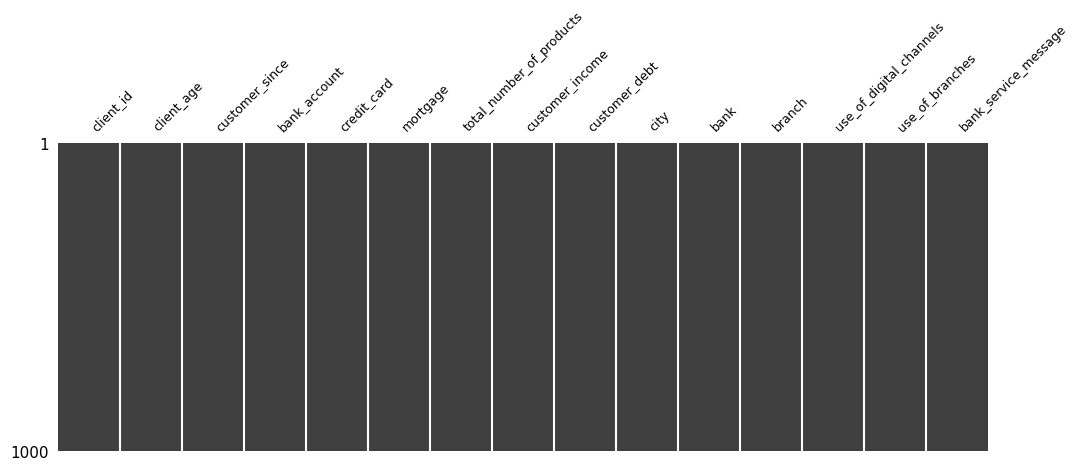

In [ ]:
# Looks for empty cells and shows a visual map:
import missingno as msno

# Count and percentage of native missing values per column
null_report = (df.isna().sum().to_frame("n_null")
                 .assign(pct_null=lambda x: x["n_null"] / len(df) * 100))
display(null_report.query("n_null > 0") if null_report["n_null"].any()
        else "No native missing values found.")

# Visual missing-value matrix (white gaps = missing)
msno.matrix(df, figsize=(12, 4), fontsize=9, sparkline=False)
plt.savefig(FIGURES_DIR / "02_missing_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

log_step("2.1", "Native missing values", df.isna().any(axis=1).sum(),
         "No action", "Dataset has no native nulls")

# We can see a generated chart of all the 15 columns from the dataset showing no missing values / 'white gaps' (Same amount of inputs / rows, for each column / variable).

## 2.3 - General Detection of Corrupt Values

In [ ]:
import datetime as dt

# Strings that look like data but actually mean "missing" (disguised nulls)
PLACEHOLDERS = {"", "na", "n/a", "nan", "null", "none", "-", "--", "?", "unknown", "missing"}
NUMERIC_RE = re.compile(r"\s*-?\d+(\.\d+)?\s*")
NUMERIC_THRESHOLD = 0.95  # share of numeric values needed to treat a column as numeric

def classify_value(v) -> str:
    """Assign a semantic type to a single cell."""
    if v is None or v is pd.NA or v is pd.NaT or (isinstance(v, float) and np.isnan(v)):
        return "missing"
    if isinstance(v, (bool, np.bool_)):
        return "bool"
    if isinstance(v, (int, float, np.integer, np.floating)):
        return "number"
    if isinstance(v, (pd.Timestamp, dt.datetime, dt.date, np.datetime64)):
        return "datetime"
    if isinstance(v, str):
        s = v.strip()
        if s.lower() in PLACEHOLDERS:
            return "placeholder"
        if NUMERIC_RE.fullmatch(s):
            return "number"
        return "text"
    return "other"

def scan_column(s: pd.Series):
    """Infer the expected type of a column and flag cells that do not match it."""
    classes = s.map(classify_value)
    valid = classes[~classes.isin(["missing", "placeholder"])]
    expected = "number" if (valid == "number").mean() >= NUMERIC_THRESHOLD else "text"
    corrupt = ~classes.isin([expected, "missing"])  # placeholders and wrong types are corrupt
    return expected, corrupt, classes.value_counts().to_dict()

def scan_dataset(data: pd.DataFrame):
    """Run scan_column on every column; return a summary report and a boolean mask per column."""
    rows, masks = [], {}
    for col in data.columns:
        expected, corrupt, counts = scan_column(data[col])
        masks[col] = corrupt
        rows.append({
            "column": col,
            "expected_type": expected,
            "type_counts": counts,
            "n_corrupt": int(corrupt.sum()),
            "examples": data.loc[corrupt, col].astype(str).unique()[:3].tolist(),
        })
    report = pd.DataFrame(rows).sort_values("n_corrupt", ascending=False).reset_index(drop=True)
    return report, pd.DataFrame(masks)

# Scan the full dataset
corruption_report, corrupt_masks = scan_dataset(df)
display(corruption_report)

CORRUPT_COLS     = corruption_report.query("n_corrupt > 0")["column"].tolist()
NUMERIC_EXPECTED = corruption_report.query("expected_type == 'number'")["column"].tolist()
print("Columns with corrupt values:", CORRUPT_COLS)

# Show affected rows (only the corrupt columns)
display(df.loc[corrupt_masks.any(axis=1), ["client_id"] + CORRUPT_COLS])

# Corrupt cells -> NaN, plus one traceability flag per affected column
for col in CORRUPT_COLS:
    df[f"{col}_was_corrupt"] = corrupt_masks[col].astype(int)
    df[col] = df[col].mask(corrupt_masks[col])

# Cast every numeric-expected column to a true numeric dtype
for col in NUMERIC_EXPECTED:
    df[col] = pd.to_numeric(df[col], errors="coerce")

,column,expected_type,type_counts,n_corrupt,examples
0,customer_debt,number,"{'number': 995, 'datetime': 5}",5,"[9977-06-01 00:00:00, 9548-03-01 00:00:00, 9080-08-01 00:00:00]"
1,client_age,number,{'number': 1000},0,[]
2,client_id,text,{'text': 1000},0,[]
3,bank_account,text,{'text': 1000},0,[]
4,credit_card,text,{'text': 1000},0,[]
5,mortgage,text,{'text': 1000},0,[]
6,customer_since,number,{'number': 1000},0,[]
7,total_number_of_products,number,{'number': 1000},0,[]
8,customer_income,number,{'number': 1000},0,[]
9,city,text,{'text': 1000},0,[]


Columns with corrupt values: ['customer_debt']


,client_id,customer_debt
99,XVTQ-3244-UCGC-7583,9977-06-01 00:00:00
493,SDVZ-5215-JKJT-3794,9548-03-01 00:00:00
562,FUXK-1921-BKVL-7535,9080-08-01 00:00:00
592,TORP-6341-UXEX-5292,5353-08-01 00:00:00
674,RNTI-4049-EAYA-3874,3557-02-01 00:00:00


We found an inconsistency on 5 data inputs on the 'customer_debt' column.

We take the 'client_id' to keep these clients in mind for a potential issue related to this column

## 2.4 - Justified Imputation (adapted)

In [ ]:
# Now go through each affected column. Numeric columns are imputed using the median, and text columns using the mode. The justification is automatically generated based on the test.
from scipy.stats import kruskal

NUM_REFERENCE = ["client_age", "customer_since", "total_number_of_products",
                 "customer_income", "customer_debt"]

for col in CORRUPT_COLS:
    n_bad = int(corrupt_masks[col].sum())

    if col in NUMERIC_EXPECTED:
        # Is this variable related to any other? If not, median is the honest choice
        others = [c for c in NUM_REFERENCE if c != col]
        rho = df[[col] + others].corr(method="spearman")[col].drop(col)
        _, p_bank = kruskal(*[g.dropna() for _, g in df.groupby("bank")[col]])
        print(f"{col}: max |rho| = {rho.abs().max():.3f} | Kruskal-Wallis by bank p = {p_bank:.3f}")

        fill_value = df[col].median()
        method = f"global median ({fill_value:,.2f})"
        rationale = (
            f"Original value unrecoverable; max |rho| = {rho.abs().max():.3f} and no difference "
            f"by bank (p = {p_bank:.2f}), so model-based imputation adds no information"
            if rho.abs().max() < 0.3 and p_bank > 0.05
            else "Variable shows relationships with others: consider KNN imputation instead"
        )
    else:
        # Categorical / text: fall back to the most frequent value
        fill_value = df[col].mode().iloc[0]
        method = f"mode ('{fill_value}')"
        rationale = "Low share of corrupt values; mode preserves the category distribution"

    df[col] = df[col].fillna(fill_value)
    log_step("2.2-2.3", f"{col}: values with wrong type or placeholders", n_bad,
             f"Set to NaN, imputed with {method} + flag column", rationale)

customer_debt: max |rho| = 0.038 | Kruskal-Wallis by bank p = 0.651


## 2.5 - Duplicates treatment

In [ ]:
# Check for identical rows, duplicate IDs, and cloned profiles with a different ID:
n_dup_rows    = df.duplicated().sum()
n_dup_ids     = df["client_id"].duplicated().sum()
n_dup_profile = df.drop(columns=["client_id"]).duplicated().sum()  # same customer, different ID

print(f"Exact duplicate rows:          {n_dup_rows}")
print(f"Duplicate client IDs:          {n_dup_ids}")
print(f"Duplicate profiles (excl. ID): {n_dup_profile}")

log_step("2.4", "Duplicate rows / IDs / profiles", n_dup_rows + n_dup_ids + n_dup_profile,
         "No action", "No duplicates of any kind were found")

Exact duplicate rows:          0
Duplicate client IDs:          0
Duplicate profiles (excl. ID): 0


## 2.6 - Logical Consistency

In [ ]:
# Apply business rules. Identify data that is technically possible but impossible in reality.
REFERENCE_YEAR = int(df["customer_since"].max())  # latest onboarding year in the data
CORE_PRODUCTS = ["bank_account", "credit_card", "mortgage"]

# Number of core products flagged as 'yes'
df["n_core_products"] = (df[CORE_PRODUCTS].apply(lambda s: s.str.strip().str.lower()) == "yes").sum(axis=1)

# Each rule returns a boolean mask of violating rows
consistency_rules = {
    "total_products < core products held":  df["total_number_of_products"] < df["n_core_products"],
    "zero products but debt > 0":           (df["total_number_of_products"] == 0) & (df["customer_debt"] > 0),
    "age at onboarding < 18":               (df["client_age"] - (REFERENCE_YEAR - df["customer_since"])) < 18,
    "customer_since after reference year":  df["customer_since"] > REFERENCE_YEAR,
    "income <= 0":                          df["customer_income"] <= 0,
    "debt < 0":                             df["customer_debt"] < 0,
    "city linked to >1 bank":               df.groupby("city")["bank"].transform("nunique") > 1,
    "branch linked to >1 city":             df.groupby("branch")["city"].transform("nunique") > 1,
}
consistency_report = pd.Series({r: int(m.sum()) for r, m in consistency_rules.items()},
                               name="violations").to_frame()
display(consistency_report)

# Cross-tab shows where the product inconsistency lives
display(pd.crosstab(df["n_core_products"], df["total_number_of_products"],
                    rownames=["core flags = yes"], colnames=["total_number_of_products"]))

,violations
total_products < core products held,138
zero products but debt > 0,111
age at onboarding < 18,0
customer_since after reference year,0
income <= 0,0
debt < 0,0
city linked to >1 bank,0
branch linked to >1 city,0


total_number_of_products,0,1,2,3,4,5
core flags = yes,,,,,,
0,111,0,0,0,0,0
1,0,82,51,83,71,90
2,0,77,61,83,66,88
3,0,36,25,27,16,33


## 2.6b - Correcting Inconsistencies

In [ ]:
# Rule 1: total products can never be lower than the core products held -> raise to the floor
mask_products = consistency_rules["total_products < core products held"]
df["products_were_fixed"] = mask_products.astype(int)
df.loc[mask_products, "total_number_of_products"] = df.loc[mask_products, "n_core_products"]

log_step("2.5", "total_number_of_products lower than core product flags", mask_products.sum(),
         "Raised to n_core_products + flag column",
         "Flags are explicit yes/no facts; the total must be at least their sum")

# Rule 2: debt with zero products is ambiguous (debt may come from an unlisted loan) -> flag only
mask_zero = consistency_rules["zero products but debt > 0"]
df["zero_products_with_debt"] = mask_zero.astype(int)

log_step("2.5", "Debt > 0 with zero products", mask_zero.sum(),
         "Kept + flag column",
         "Cannot infer which product generated the debt; removing 11% of customers would bias segments")
# We leave a flag and a comment as useful context for colleagues and upper management

## 2.7 - Univariate outliers

,iqr_1.5,zscore_>3
client_age,0,0
customer_since,0,0
total_number_of_products,0,0
customer_income,0,0
customer_debt,0,0


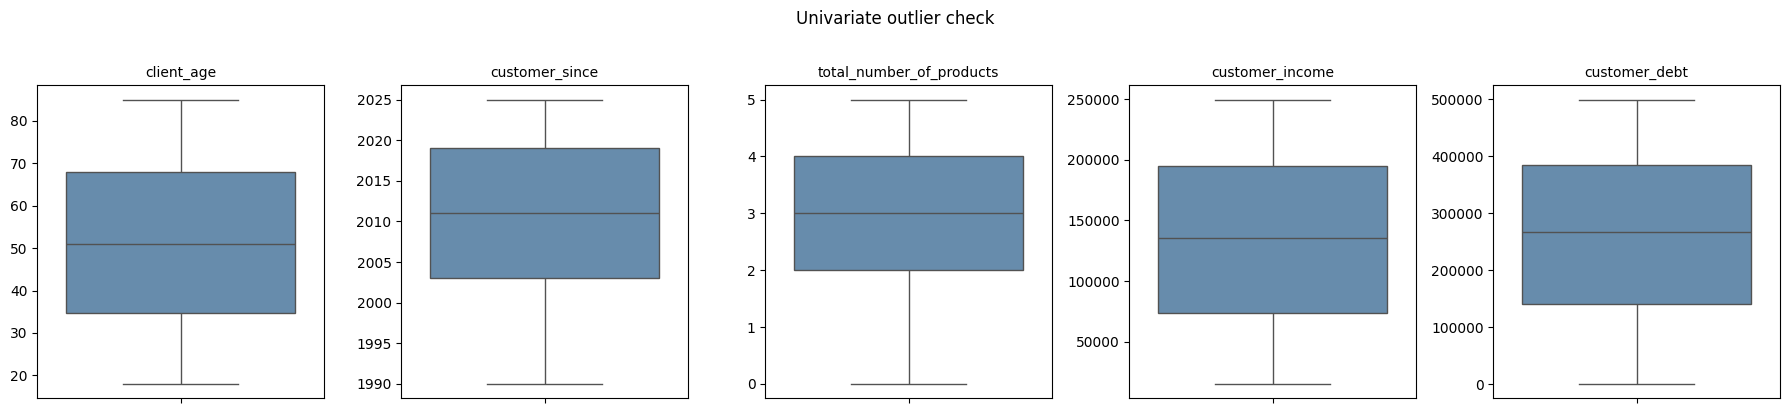

In [ ]:
# Calculate the IQR and z-score for each variable. Box plots accompany the results.

from scipy.stats import zscore

OUTLIER_COLS = NUM_COLS + ["customer_debt"]

def iqr_mask(s: pd.Series, k: float = 1.5) -> pd.Series:
    """Tukey fences: values beyond Q1 - k*IQR or Q3 + k*IQR."""
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (s < q1 - k * iqr) | (s > q3 + k * iqr)

univariate_outliers = pd.DataFrame({
    "iqr_1.5":   {c: int(iqr_mask(df[c]).sum()) for c in OUTLIER_COLS},
    "zscore_>3": {c: int((np.abs(zscore(df[c])) > 3).sum()) for c in OUTLIER_COLS},
})
display(univariate_outliers)

# Boxplots for visual confirmation
fig, axes = plt.subplots(1, len(OUTLIER_COLS), figsize=(18, 4))
for ax, c in zip(axes, OUTLIER_COLS):
    sns.boxplot(y=df[c], ax=ax, color="#5B8DB8")
    ax.set_title(c, fontsize=10); ax.set_ylabel("")
plt.suptitle("Univariate outlier check", y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "02_boxplots_outliers.png", dpi=150, bbox_inches="tight")
plt.show()

log_step("2.6", "Univariate outliers (IQR & z-score)", univariate_outliers.values.sum(),
         "No action", "No value falls outside Tukey fences or |z| > 3")

## 2.8 - Multivariate outliers

In [ ]:
# Isolation Forest looks for rare combinations of variables. If their medians are similar to the rest, there is no real anomaly.

from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import RobustScaler

# Robust scaling so income/debt (large ranges) don't dominate the trees
X_iso = RobustScaler().fit_transform(df[OUTLIER_COLS])

# Fixed 3% contamination: 'auto' over-flags on near-uniform data
iso = IsolationForest(n_estimators=300, contamination=0.03, random_state=SEED)
df["iso_outlier"] = (iso.fit_predict(X_iso) == -1).astype(int)
df["iso_score"]   = -iso.score_samples(X_iso)  # higher = more anomalous

print(f"Multivariate outliers flagged: {df['iso_outlier'].sum()}")

# Compare profiles: if medians are similar, flagged rows are not genuinely anomalous
display(df.groupby("iso_outlier")[OUTLIER_COLS].median().T
          .rename(columns={0: "normal", 1: "flagged"}))

log_step("2.7", "Multivariate outliers (Isolation Forest, 3%)", df["iso_outlier"].sum(),
         "Kept + flag column",
         "No impossible values (all within normal ranges); 63% overlap with the zero-products-with-debt "
         "rule from 2.5, confirming that finding independently; kept as a potential cross-sell segment, "
         "sensitivity check planned in clustering")

Multivariate outliers flagged: 30


iso_outlier,normal,flagged
client_age,50.50,58.50
customer_since,"2,011.00","2,019.00"
total_number_of_products,3.00,0.00
customer_income,"135,902.36","118,501.30"
customer_debt,"267,216.35","312,467.52"


## 2.8b - Overlap Diagnosis

In [ ]:
# Do multivariate outliers overlap with the logical inconsistency found in 2.5?
overlap = pd.crosstab(df["iso_outlier"], df["zero_products_with_debt"],
                      rownames=["iso_outlier"], colnames=["zero_products_with_debt"])
display(overlap)

n_overlap = int(((df["iso_outlier"] == 1) & (df["zero_products_with_debt"] == 1)).sum())
n_flagged = int(df["iso_outlier"].sum())
print(f"{n_overlap}/{n_flagged} multivariate outliers ({n_overlap / n_flagged:.0%}) "
      f"are zero-product customers with debt")

# Are flagged values inside the normal data range? (if yes -> rare, not erroneous)
range_check = pd.DataFrame({
    "normal_min":  df.loc[df["iso_outlier"] == 0, OUTLIER_COLS].min(),
    "normal_max":  df.loc[df["iso_outlier"] == 0, OUTLIER_COLS].max(),
    "flagged_min": df.loc[df["iso_outlier"] == 1, OUTLIER_COLS].min(),
    "flagged_max": df.loc[df["iso_outlier"] == 1, OUTLIER_COLS].max(),
})
display(range_check)

# Stability: does the flagged set change with the random seed?
for s in [0, 1, 2, 3]:
    alt = IsolationForest(n_estimators=300, contamination=0.03, random_state=s).fit_predict(X_iso) == -1
    print(f"seed={s}: {int((alt & (df['iso_outlier'] == 1)).sum())}/{n_flagged} same rows flagged")

zero_products_with_debt,0,1
iso_outlier,,
0,878,92
1,11,19


19/30 multivariate outliers (63%) are zero-product customers with debt


,normal_min,normal_max,flagged_min,flagged_max
client_age,18.00,85.00,18.00,85.00
customer_since,"1,990.00","2,025.00","1,990.00","2,025.00"
total_number_of_products,0.00,5.00,0.00,5.00
customer_income,"15,128.02","249,794.91","15,148.49","246,121.07"
customer_debt,989.17,"499,751.26","2,664.69","499,038.79"


seed=0: 27/30 same rows flagged
seed=1: 24/30 same rows flagged
seed=2: 23/30 same rows flagged
seed=3: 26/30 same rows flagged


## 2.9 - Standardization of Categories and Text

In [ ]:
# Standardize capitalization and spacing. Clean up the text in the messages.
YES_NO_COLS = ["bank_account", "credit_card", "mortgage"]
LEVEL_COLS  = ["use_of_digital_channels", "use_of_branches"]

# Trim whitespace in every categorical column; lowercase the coded ones
for c in CAT_COLS:
    df[c] = df[c].astype(str).str.strip()
for c in YES_NO_COLS + LEVEL_COLS:
    df[c] = df[c].str.lower()

# Normalize whitespace in the free-text message (content itself is untouched)
df["bank_service_message"] = (df["bank_service_message"].astype(str)
                                .str.replace(r"\s+", " ", regex=True).str.strip())

display({c: sorted(df[c].unique()) for c in YES_NO_COLS + LEVEL_COLS})

log_step("2.8", "Category / text formatting", 0, "Trimmed + lowercased",
         "Guarantees consistent encoding in later sections")

{'bank_account': ['no', 'yes'],
 'credit_card': ['no', 'yes'],
 'mortgage': ['no', 'yes'],
 'use_of_digital_channels': ['high', 'low', 'medium'],
 'use_of_branches': ['high', 'low', 'medium']}

## 2.10 - Stylized Audit Table

In [ ]:
# Color each row according to the type of action and add impact bars.

cleaning_log_df = pd.DataFrame(cleaning_log)

def action_type(decision: str) -> str:
    """Group free-text decisions into 5 standard action categories."""
    d = decision.lower()
    if d.startswith("no action"): return "No action"
    if "imputed" in d:            return "Imputed"
    if "kept" in d:               return "Flagged"
    if "trimmed" in d:            return "Standardized"
    return "Fixed"

cleaning_log_df["action_type"]  = cleaning_log_df["decision"].map(action_type)
cleaning_log_df["pct_affected"] = (cleaning_log_df["rows_affected"] / len(df) * 100).round(1)

# Consistent color code reused in the chart and in the reports
ACTION_COLORS = {"No action": "#B0B7C3", "Flagged": "#E0A030", "Imputed": "#5B8DB8",
                 "Fixed": "#2E8B57", "Standardized": "#7E6BB5"}

def color_action(v):
    """Cell style for the action_type column."""
    return f"background-color:{ACTION_COLORS[v]}; color:white; font-weight:bold" if v in ACTION_COLORS else ""

styled_log = (
    cleaning_log_df[["step", "issue", "rows_affected", "pct_affected",
                     "action_type", "decision", "rationale"]]
    .style
    .hide(axis="index")
    .map(color_action, subset=["action_type"])
    .bar(subset=["rows_affected"], color="#F4C7C3", vmin=0)   # in-cell impact bar
    .format({"pct_affected": "{:.1f}%"})
    .set_properties(**{"text-align": "left", "white-space": "normal", "font-size": "12px"})
    .set_caption("Data cleaning audit log")
)
display(styled_log)

step,issue,rows_affected,pct_affected,action_type,decision,rationale
2.1,Native missing values,0,0.0%,No action,No action,Dataset has no native nulls
2.2-2.3,customer_debt: values with wrong type or placeholders,5,0.5%,Imputed,"Set to NaN, imputed with global median (267,216.35) + flag column","Original value unrecoverable; max |rho| = 0.038 and no difference by bank (p = 0.65), so model-based imputation adds no information"
2.4,Duplicate rows / IDs / profiles,0,0.0%,No action,No action,No duplicates of any kind were found
2.5,total_number_of_products lower than core product flags,138,13.8%,Fixed,Raised to n_core_products + flag column,Flags are explicit yes/no facts; the total must be at least their sum
2.5,Debt > 0 with zero products,111,11.1%,Flagged,Kept + flag column,Cannot infer which product generated the debt; removing 11% of customers would bias segments
2.6,Univariate outliers (IQR & z-score),0,0.0%,No action,No action,No value falls outside Tukey fences or |z| > 3
2.7,"Multivariate outliers (Isolation Forest, 3%)",30,3.0%,Flagged,Kept + flag column,"No impossible values (all within normal ranges); 63% overlap with the zero-products-with-debt rule from 2.5, confirming that finding independently; kept as a potential cross-sell segment, sensitivity check planned in clustering"
2.8,Category / text formatting,0,0.0%,Standardized,Trimmed + lowercased,Guarantees consistent encoding in later sections


## 2.12 - Impact Chart by Step

In [ ]:
# Shows how many rows each step affected. Hover your mouse over a bar to see the decision and its justification.

plot_df = cleaning_log_df.assign(
    label=lambda x: x["step"] + " · " + x["issue"].str.slice(0, 45)  # short y-axis labels
)

fig = px.bar(
    plot_df.sort_values("rows_affected"),
    x="rows_affected", y="label", color="action_type", orientation="h",
    color_discrete_map=ACTION_COLORS, text="pct_affected",
    hover_data={"decision": True, "rationale": True, "label": False},
)
fig.update_traces(texttemplate="%{text:.1f}%", textposition="outside")
fig.update_layout(
    title="Rows affected by each cleaning step (% of dataset)",
    xaxis_title="Rows affected", yaxis_title="", legend_title="Action",
    height=420, margin=dict(l=10, r=40, t=60, b=40),
)
fig.show()

# Static copy for Word / slides — falls back to interactive HTML if image export fails
try:
    fig.write_image(FIGURES_DIR / "02_cleaning_log_impact.png", scale=2)
    print("PNG saved")
except Exception as e:
    fig.write_html(FIGURES_DIR / "02_cleaning_log_impact.html")
    print(f"PNG export failed ({type(e).__name__}); saved interactive HTML instead")

PNG export failed (ValueError); saved interactive HTML instead


## 2.11 - Summary, Export, and Integrity

In [ ]:
# One-line-per-action summary — ready for the executive report
log_summary = (cleaning_log_df.groupby("action_type")
                 .agg(steps=("step", "count"), rows_affected=("rows_affected", "sum"))
                 .sort_values("rows_affected", ascending=False))
display(log_summary)

# Persist outputs: CSV for analysis, HTML to share the styled table
cleaning_log_df.to_csv(REPORTS_DIR / "cleaning_log.csv", index=False)
styled_log.to_html(REPORTS_DIR / "cleaning_log.html")
df.to_excel(PROCESSED_DIR / "customers_clean.xlsx", index=False)

# Integrity check: the raw file must still match its original checksum
assert file_md5(RAW_XLSX) == RAW_MD5, "Raw file was modified!"
print(f"Clean dataset saved: {df.shape} | Raw file integrity: OK")

,steps,rows_affected
action_type,,
Flagged,2,141
Fixed,1,138
Imputed,1,5
No action,3,0
Standardized,1,0


Clean dataset saved: (1000, 21) | Raw file integrity: OK


# 3 - Exploratory Data Analysis and visualization



## Export Helper

In [ ]:
#  A single function saves any plot, whether from matplotlib/seaborn or Plotly. The filenames are prefixed with the module name (03_...), so the figures are organized for use in Word and slides.

import plotly.graph_objects as go

def save_fig(fig, name: str, scale: int = 2, dpi: int = 150) -> Path:
    """
    Save a matplotlib/seaborn or plotly figure to FIGURES_DIR.
    - Plotly: tries PNG via kaleido; falls back to interactive HTML if export fails.
    - Matplotlib: accepts a Figure or an Axes and saves a high-res PNG.
    """
    if isinstance(fig, go.Figure):
        try:
            path = FIGURES_DIR / f"{name}.png"
            fig.write_image(path, scale=scale)
        except Exception as e:
            path = FIGURES_DIR / f"{name}.html"
            fig.write_html(path)
            print(f"PNG export failed ({type(e).__name__}); saved HTML instead")
    else:
        if isinstance(fig, plt.Axes):      # seaborn often returns an Axes, not a Figure
            fig = fig.figure
        path = FIGURES_DIR / f"{name}.png"
        fig.savefig(path, dpi=dpi, bbox_inches="tight")
    print(f"Saved: {path.name}")
    return path

# Quick sanity check: list what is already in the figures folder
print("Existing figures:", sorted(p.name for p in FIGURES_DIR.iterdir()))

Existing figures: ['02_boxplots_outliers.png', '02_cleaning_log_impact.html', '02_missing_matrix.png', '03_association_matrices.png', '03_bank_profile.png', '03_bivariate_relationships.png', '03_categorical_distributions.png', '03_numeric_distributions.png', '03_text_exploration.png', '04_dti_transformation.png', '06_confusion_matrices.png', '06_satisfaction_levels.png', '07_reasons_by_level.png', '07_topic_clustering.png', '08_satisfaction_by_variables.png', '10_model_comparison.png', '11_segment_profiles.png', '11_segment_satisfaction.png', '11_segments_pca.png']


## 3.2 - Numeric Variables


,mean,median,std,min,max,skewness,excess_kurtosis,ks_uniform_p
client_age,51.06,51.00,19.61,18.00,85.00,-0.00,-1.16,0.30
customer_since,"2,010.40","2,011.00",9.89,"1,990.00","2,025.00",-0.32,-1.06,0.00
customer_income,"134,262.33","135,767.52","69,170.02","15,128.02","249,794.91",-0.03,-1.25,0.19
customer_debt,"262,377.24","267,216.35","143,510.48",989.17,"499,751.26",-0.08,-1.22,0.01
total_number_of_products,2.89,3.00,1.58,0.00,5.00,-0.29,-0.87,0.00


Saved: 03_numeric_distributions.png


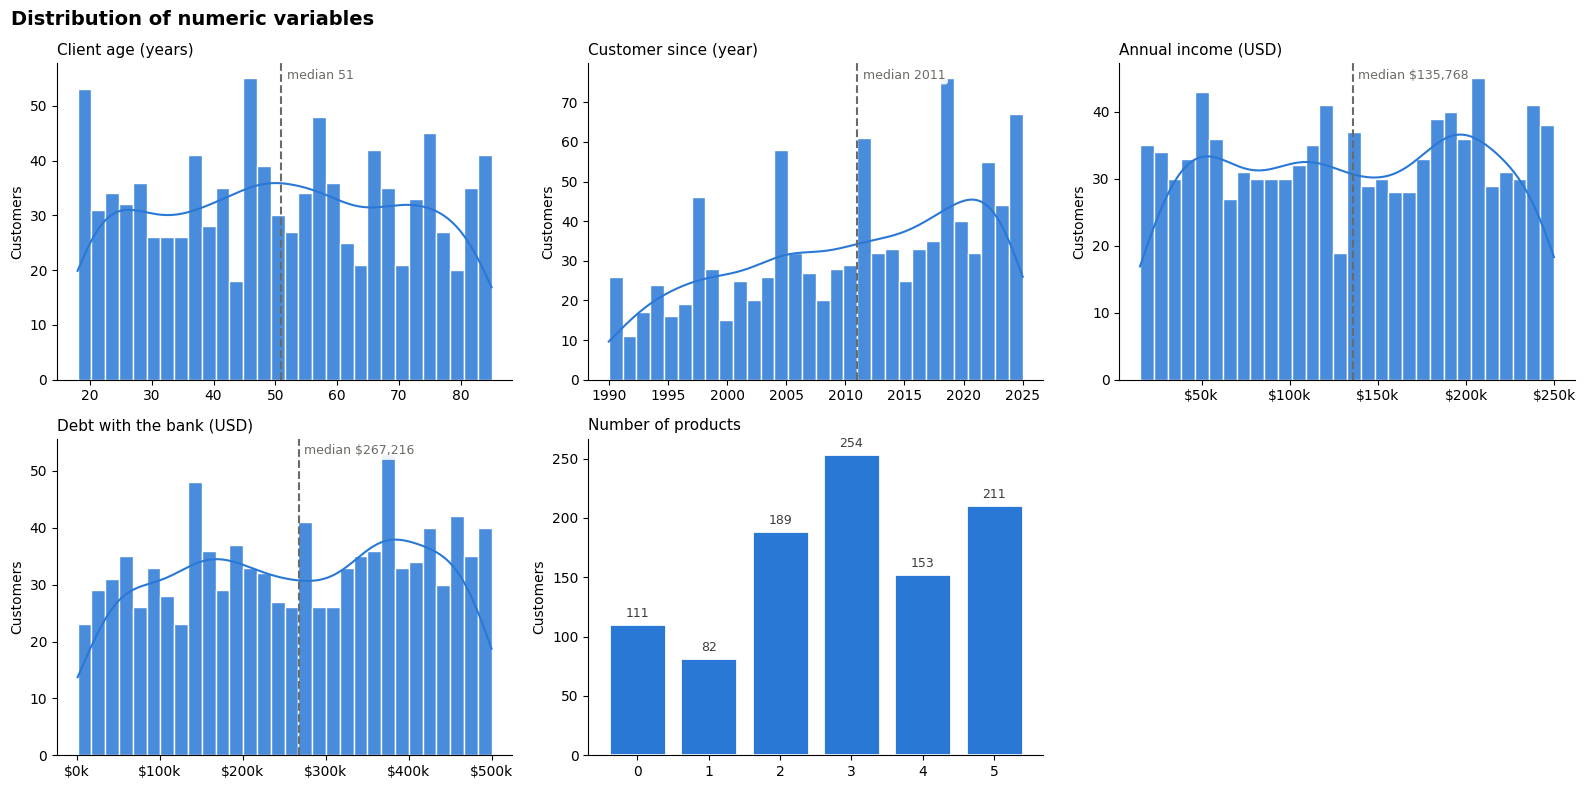

In [ ]:
from scipy.stats import kstest, skew, kurtosis
from matplotlib.ticker import FuncFormatter

CONT_COLS = ["client_age", "customer_since", "customer_income", "customer_debt"]
DISC_COLS = ["total_number_of_products"]

LABELS = {
    "client_age": "Client age (years)",
    "customer_since": "Customer since (year)",
    "customer_income": "Annual income (USD)",
    "customer_debt": "Debt with the bank (USD)",
    "total_number_of_products": "Number of products",
}

def uniform_ks_pvalue(s: pd.Series) -> float:
    """Kolmogorov-Smirnov test against a uniform distribution on [min, max].
    p > 0.05 -> uniformity cannot be rejected."""
    lo, hi = s.min(), s.max()
    return kstest(s, "uniform", args=(lo, hi - lo)).pvalue

# --- Statistical profile ---
numeric_profile = pd.DataFrame({
    c: {
        "mean": df[c].mean(), "median": df[c].median(), "std": df[c].std(),
        "min": df[c].min(), "max": df[c].max(),
        "skewness": skew(df[c]),            # 0 = symmetric
        "excess_kurtosis": kurtosis(df[c]), # ~ -1.2 = uniform, 0 = normal
        "ks_uniform_p": uniform_ks_pvalue(df[c]),
    }
    for c in CONT_COLS + DISC_COLS
}).T
display(numeric_profile.round(3))

# --- Distribution plots ---
usd_k = FuncFormatter(lambda x, _: f"${x/1000:,.0f}k")
X_FORMATS = {"customer_income": usd_k, "customer_debt": usd_k}
MEDIAN_FMT = {"client_age": "{:.0f}", "customer_since": "{:.0f}",
              "customer_income": "${:,.0f}", "customer_debt": "${:,.0f}"}

fig, axes = plt.subplots(2, 3, figsize=(16, 8))

# Continuous variables: histogram + KDE + median reference line
for ax, c in zip(axes.flat, CONT_COLS):
    sns.histplot(df[c], bins=30, kde=True, color=BASE_COLOR,
                 edgecolor="white", linewidth=1, alpha=0.85, ax=ax)
    med = df[c].median()
    ax.axvline(med, color=INK_MUTED, ls="--", lw=1.5)
    ax.annotate(f"median {MEDIAN_FMT[c].format(med)}",
                xy=(med, 1.0), xycoords=("data", "axes fraction"),
                xytext=(4, -4), textcoords="offset points",
                fontsize=9, color=INK_MUTED, va="top",
                bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.9))
    if c in X_FORMATS:
        ax.xaxis.set_major_formatter(X_FORMATS[c])
    ax.set_title(LABELS[c], fontsize=11, loc="left")
    ax.set_xlabel(""); ax.set_ylabel("Customers")

# Discrete variable: bar chart with direct labels
ax = axes.flat[4]
counts = df["total_number_of_products"].value_counts().sort_index()
ax.bar(counts.index, counts.values, color=BASE_COLOR, edgecolor="white", linewidth=2, width=0.8)
for x, y in counts.items():
    ax.text(x, y + 3, f"{y}", ha="center", va="bottom", fontsize=9, color="#3d3d3a")
ax.set_title(LABELS["total_number_of_products"], fontsize=11, loc="left")
ax.set_ylabel("Customers")

axes.flat[5].axis("off")  # empty slot in the 2x3 grid
for a in axes.flat[:5]:
    sns.despine(ax=a)
    a.grid(axis="x", visible=False)

fig.suptitle("Distribution of numeric variables", fontsize=14, x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
save_fig(fig, "03_numeric_distributions")
plt.show()

## 3.3 - Categorical Variables

,n_categories,most_common,most_common_pct,least_common,least_common_pct,chi2_balance_p
variable,,,,,,
bank_account,2,yes,52.00,no,48.00,0.21
credit_card,2,yes,50.80,no,49.20,0.61
mortgage,2,yes,51.00,no,49.00,0.53
use_of_digital_channels,3,medium,34.60,high,32.10,0.63
use_of_branches,3,low,35.60,medium,31.40,0.26
bank,3,Chase,39.40,Bank of America,30.20,0.00
city,10,Seattle,10.80,New York,9.30,0.99


Saved: 03_categorical_distributions.png


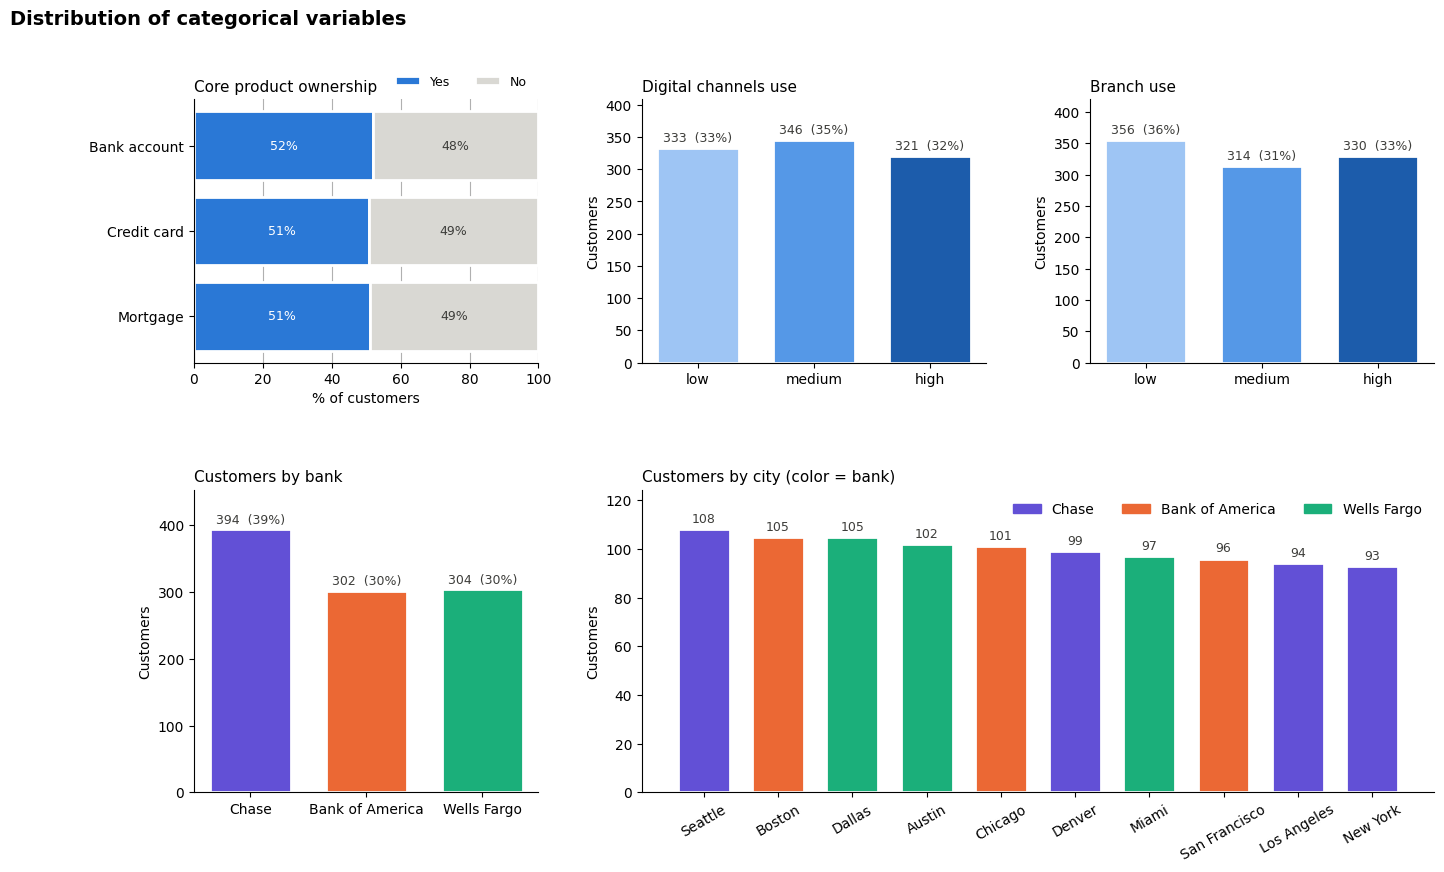

In [ ]:
from scipy.stats import chisquare
from matplotlib.patches import Patch

YES_NO_COLS = ["bank_account", "credit_card", "mortgage"]
LEVEL_COLS  = ["use_of_digital_channels", "use_of_branches"]
LEVEL_ORDER = ["low", "medium", "high"]

# Ordinal = one hue, light -> dark (never three unrelated colors)
LEVEL_COLORS = {"low": "#9ec5f4", "medium": "#5598e7", "high": "#1c5cab"}
YESNO_COLORS = {"yes": BASE_COLOR, "no": "#d9d8d3"}
INK = "#3d3d3a"

CAT_LABELS = {
    "bank_account": "Bank account", "credit_card": "Credit card", "mortgage": "Mortgage",
    "use_of_digital_channels": "Digital channels use", "use_of_branches": "Branch use",
    "bank": "Bank", "city": "City",
}

# --- Balance report: are categories evenly sized? (chi-square goodness of fit) ---
rows = []
for c in YES_NO_COLS + LEVEL_COLS + ["bank", "city"]:
    vc = df[c].value_counts()
    rows.append({
        "variable": c,
        "n_categories": len(vc),
        "most_common": vc.index[0],  "most_common_pct": vc.iloc[0] / len(df) * 100,
        "least_common": vc.index[-1], "least_common_pct": vc.iloc[-1] / len(df) * 100,
        "chi2_balance_p": chisquare(vc.values).pvalue,  # p > 0.05 -> balanced
    })
balance_report = pd.DataFrame(rows).set_index("variable")
display(balance_report.round(3))

# --- Figure layout: 3 panels on top, 2 below ---
fig = plt.figure(figsize=(16, 9))
gs = fig.add_gridspec(2, 3, height_ratios=[1, 1.15], hspace=0.45, wspace=0.3)

# Panel A: core product ownership as 100% stacked bars
ax = fig.add_subplot(gs[0, 0])
share = pd.DataFrame({c: df[c].value_counts(normalize=True) for c in YES_NO_COLS}).T[["yes", "no"]] * 100
share.index = [CAT_LABELS[c] for c in share.index]
left = np.zeros(len(share))
for k in ["yes", "no"]:
    ax.barh(share.index, share[k], left=left, color=YESNO_COLORS[k],
            edgecolor="white", linewidth=2, label=k.capitalize())
    for i, (l, v) in enumerate(zip(left, share[k])):
        ax.text(l + v / 2, i, f"{v:.0f}%", ha="center", va="center", fontsize=9,
                color="white" if k == "yes" else INK)
    left += share[k].values
ax.set_xlim(0, 100); ax.invert_yaxis()
ax.set_xlabel("% of customers")
ax.set_title("Core product ownership", loc="left", fontsize=11)
ax.legend(ncol=2, frameon=False, loc="lower right", bbox_to_anchor=(1, 1.0), fontsize=9)

# Panels B-C: ordinal usage levels in fixed low -> high order
for j, c in enumerate(LEVEL_COLS):
    ax = fig.add_subplot(gs[0, j + 1])
    vc = df[c].value_counts().reindex(LEVEL_ORDER)
    ax.bar(vc.index, vc.values, color=[LEVEL_COLORS[l] for l in vc.index],
           edgecolor="white", linewidth=2, width=0.7)
    for x, y in zip(vc.index, vc.values):
        ax.text(x, y + 5, f"{y}  ({y / len(df):.0%})", ha="center", va="bottom", fontsize=9, color=INK)
    ax.set_ylim(0, vc.max() * 1.18)
    ax.set_title(CAT_LABELS[c], loc="left", fontsize=11); ax.set_ylabel("Customers")

# Panel D: customers by bank (fixed bank order so colors always follow the entity)
ax = fig.add_subplot(gs[1, 0])
vc = df["bank"].value_counts().reindex(list(BANK_COLORS))
ax.bar(vc.index, vc.values, color=[BANK_COLORS[b] for b in vc.index],
       edgecolor="white", linewidth=2, width=0.7)
for x, y in zip(vc.index, vc.values):
    ax.text(x, y + 5, f"{y}  ({y / len(df):.0%})", ha="center", va="bottom", fontsize=9, color=INK)
ax.set_ylim(0, vc.max() * 1.15)
ax.set_title("Customers by bank", loc="left", fontsize=11); ax.set_ylabel("Customers")

# Panel E: customers by city, colored by the bank that operates there
ax = fig.add_subplot(gs[1, 1:])
city = (df.groupby(["city", "bank"]).size().reset_index(name="n")
          .sort_values("n", ascending=False))
ax.bar(city["city"], city["n"], color=city["bank"].map(BANK_COLORS),
       edgecolor="white", linewidth=2, width=0.7)
for x, y in zip(city["city"], city["n"]):
    ax.text(x, y + 1.5, f"{y}", ha="center", va="bottom", fontsize=9, color=INK)
ax.set_ylim(0, city["n"].max() * 1.15)
ax.set_title("Customers by city (color = bank)", loc="left", fontsize=11); ax.set_ylabel("Customers")
ax.tick_params(axis="x", rotation=30)
ax.legend(handles=[Patch(color=v, label=k) for k, v in BANK_COLORS.items()],
          frameon=False, ncol=3, loc="upper right")

# Shared styling: recessive grid behind the bars
for a in fig.axes:
    sns.despine(ax=a)
    a.grid(axis="x", visible=False)
    a.set_axisbelow(True)
fig.axes[0].grid(axis="y", visible=False)   # horizontal bars: vertical grid only
fig.axes[0].grid(axis="x", visible=True)

fig.suptitle("Distribution of categorical variables", fontsize=14, x=0.01, ha="left", fontweight="bold")
save_fig(fig, "03_categorical_distributions")
plt.show()

**Key finding:** Chase does not have more customers per city. It operates in more cities: 4 (Seattle, Denver, Los Angeles, New York) compared to 3 for the others. The cities are balanced (p = 0.99). Its larger size is explained by geographic coverage, not by customer preference.

## 3.4 - Profile by Bank

,Chase,Bank of America,Wells Fargo,test,p_value,effect_size,significant
variable,,,,,,,
client_age,49.00,52.00,51.00,Kruskal-Wallis,0.46,0.00,no
customer_since,"2,012.00","2,010.50","2,012.00",Kruskal-Wallis,0.22,0.00,no
customer_income,"123,243.32","139,823.92","144,158.80",Kruskal-Wallis,0.57,0.00,no
customer_debt,"262,587.33","267,216.35","267,983.08",Kruskal-Wallis,0.65,0.00,no
total_number_of_products,3.00,3.00,3.00,Kruskal-Wallis,0.12,0.00,no
bank_account = yes (%),54.06,52.65,48.68,Chi-square,0.36,0.04,no
credit_card = yes (%),52.28,51.33,48.35,Chi-square,0.57,0.03,no
mortgage = yes (%),49.75,48.34,55.26,Chi-square,0.19,0.06,no
use_of_digital_channels = high (%),35.28,29.47,30.59,Chi-square,0.45,0.04,no


Saved: 03_bank_profile.png


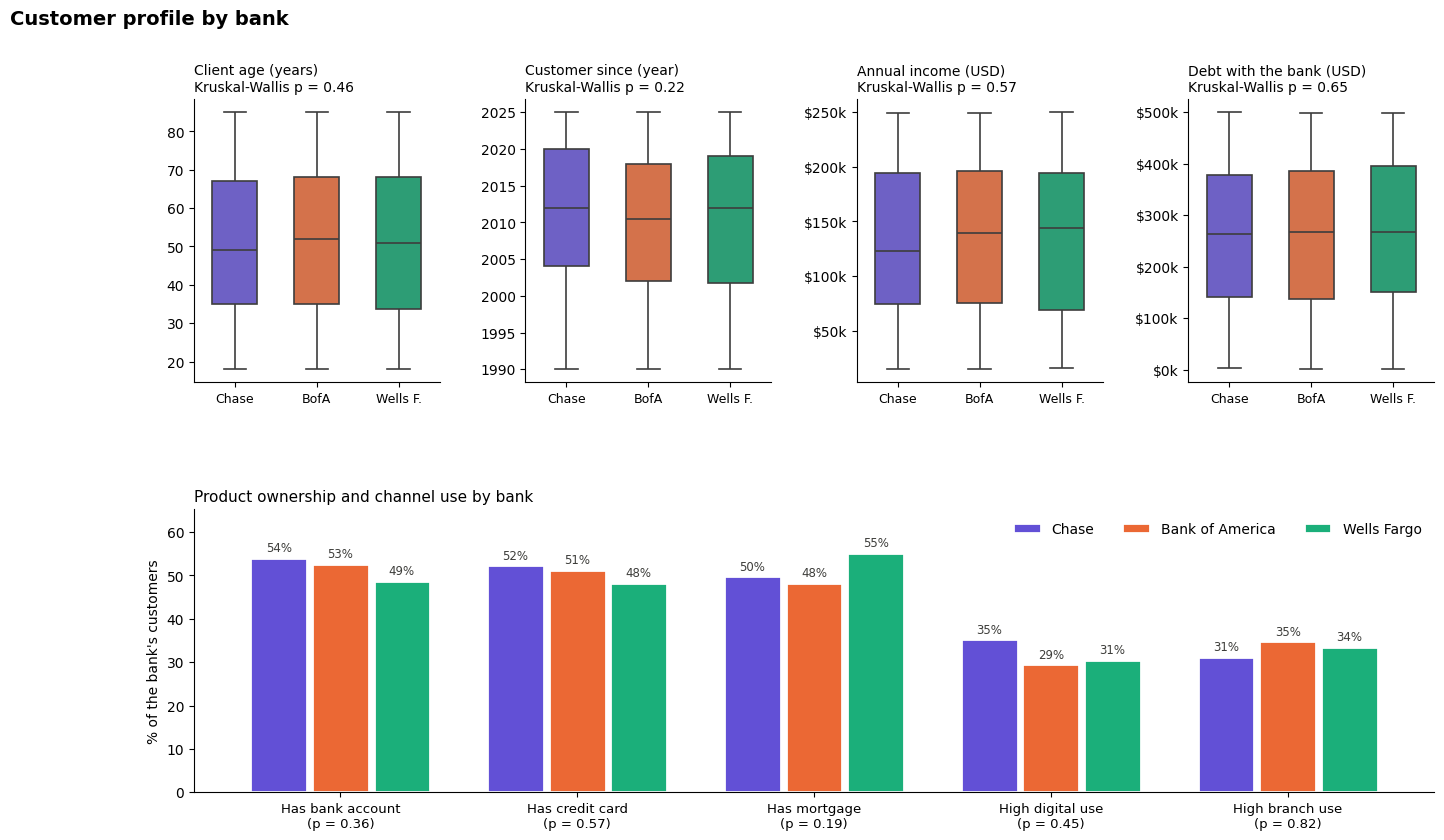

In [ ]:
from scipy.stats import kruskal, chi2_contingency

BANK_ORDER = list(BANK_COLORS)  # fixed order: Chase, Bank of America, Wells Fargo
NUM_PROFILE_COLS = ["client_age", "customer_since", "customer_income",
                    "customer_debt", "total_number_of_products"]
# Categorical variables summarized as "% of customers at this level"
CAT_PROFILE = {"bank_account": "yes", "credit_card": "yes", "mortgage": "yes",
               "use_of_digital_channels": "high", "use_of_branches": "high"}

def epsilon_squared(h: float, n: int) -> float:
    """Effect size for Kruskal-Wallis (0 = no effect, 1 = total separation)."""
    return h / (n - 1)

def cramers_v(ct: pd.DataFrame) -> float:
    """Effect size for a chi-square contingency table (0 = independent, 1 = perfect association)."""
    chi2 = chi2_contingency(ct)[0]
    n = ct.values.sum()
    r, k = ct.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1)))

# --- Numeric variables: median per bank + Kruskal-Wallis ---
num_rows = []
for c in NUM_PROFILE_COLS:
    h, p = kruskal(*[df.loc[df["bank"] == b, c] for b in BANK_ORDER])
    num_rows.append({
        "variable": c,
        **{b: df.loc[df["bank"] == b, c].median() for b in BANK_ORDER},
        "test": "Kruskal-Wallis", "p_value": p, "effect_size": epsilon_squared(h, len(df)),
    })

# --- Categorical variables: % at the reference level per bank + chi-square ---
cat_rows = []
for c, level in CAT_PROFILE.items():
    ct = pd.crosstab(df["bank"], df[c])
    pct = (df[c] == level).groupby(df["bank"]).mean() * 100
    cat_rows.append({
        "variable": f"{c} = {level} (%)",
        **{b: pct[b] for b in BANK_ORDER},
        "test": "Chi-square", "p_value": chi2_contingency(ct)[1], "effect_size": cramers_v(ct),
    })

bank_profile = pd.DataFrame(num_rows + cat_rows).set_index("variable")
bank_profile["significant"] = np.where(bank_profile["p_value"] < 0.05, "yes", "no")
display(bank_profile.round(3))

# --- Figure: numeric distributions (top) + categorical shares (bottom) ---
fig = plt.figure(figsize=(16, 9))
gs = fig.add_gridspec(2, 4, hspace=0.45, wspace=0.35)
SHORT_BANK = ["Chase", "BofA", "Wells F."]

# Top row: boxplots per bank, with the test result in each title
for j, c in enumerate(["client_age", "customer_since", "customer_income", "customer_debt"]):
    ax = fig.add_subplot(gs[0, j])
    sns.boxplot(data=df, x="bank", y=c, order=BANK_ORDER, hue="bank", palette=BANK_COLORS,
                legend=False, width=0.55, linewidth=1.2, fliersize=2, ax=ax)
    ax.set_title(f"{LABELS[c]}\nKruskal-Wallis p = {bank_profile.loc[c, 'p_value']:.2f}",
                 loc="left", fontsize=10)
    ax.set_xlabel(""); ax.set_ylabel("")
    ax.set_xticks(range(3)); ax.set_xticklabels(SHORT_BANK, fontsize=9)
    if c in X_FORMATS:  # reuse the $k formatter from 3.1
        ax.yaxis.set_major_formatter(X_FORMATS[c])

# Bottom row: grouped bars of product ownership and channel use
ax = fig.add_subplot(gs[1, :])
cat_plot = bank_profile.loc[[r for r in bank_profile.index if "(%)" in r], BANK_ORDER]
NICE = {"bank_account = yes (%)": "Has bank account", "credit_card = yes (%)": "Has credit card",
        "mortgage = yes (%)": "Has mortgage", "use_of_digital_channels = high (%)": "High digital use",
        "use_of_branches = high (%)": "High branch use"}
x, w = np.arange(len(cat_plot)), 0.26
for i, b in enumerate(BANK_ORDER):
    vals = cat_plot[b].values
    ax.bar(x + (i - 1) * w, vals, width=w - 0.02, color=BANK_COLORS[b],
           edgecolor="white", linewidth=2, label=b)
    for xi, v in zip(x + (i - 1) * w, vals):
        ax.text(xi, v + 0.8, f"{v:.0f}%", ha="center", va="bottom", fontsize=8.5, color=INK)
ax.set_xticks(x)
ax.set_xticklabels([f"{NICE[r]}\n(p = {bank_profile.loc[r, 'p_value']:.2f})" for r in cat_plot.index],
                   fontsize=9.5)
ax.set_ylim(0, cat_plot.values.max() * 1.18)
ax.set_ylabel("% of the bank's customers")
ax.set_title("Product ownership and channel use by bank", loc="left", fontsize=11)
ax.legend(frameon=False, ncol=3, loc="upper right")

for a in fig.axes:
    sns.despine(ax=a)
    a.grid(axis="x", visible=False)
    a.set_axisbelow(True)

fig.suptitle("Customer profile by bank", fontsize=14, x=0.01, ha="left", fontweight="bold")
save_fig(fig, "03_bank_profile")
plt.show()

None of the differences are significant (all p > 0.05), and all effects are negligible.

**Key finding** All three banks serve the same type of customer. Their customers have the same age, the same income, the same debt, and the same mix of products. This has two consequences:

## 3.5 - Bivariate Relationships

,test,statistic,p_value
pair,,,
income vs debt,Spearman rho,-0.02,0.56
age vs number of products,Spearman rho,-0.00,0.91
digital use vs branch use,Cramer's V,0.06,0.14
age band vs digital use,Cramer's V,0.03,0.89


Saved: 03_bivariate_relationships.png


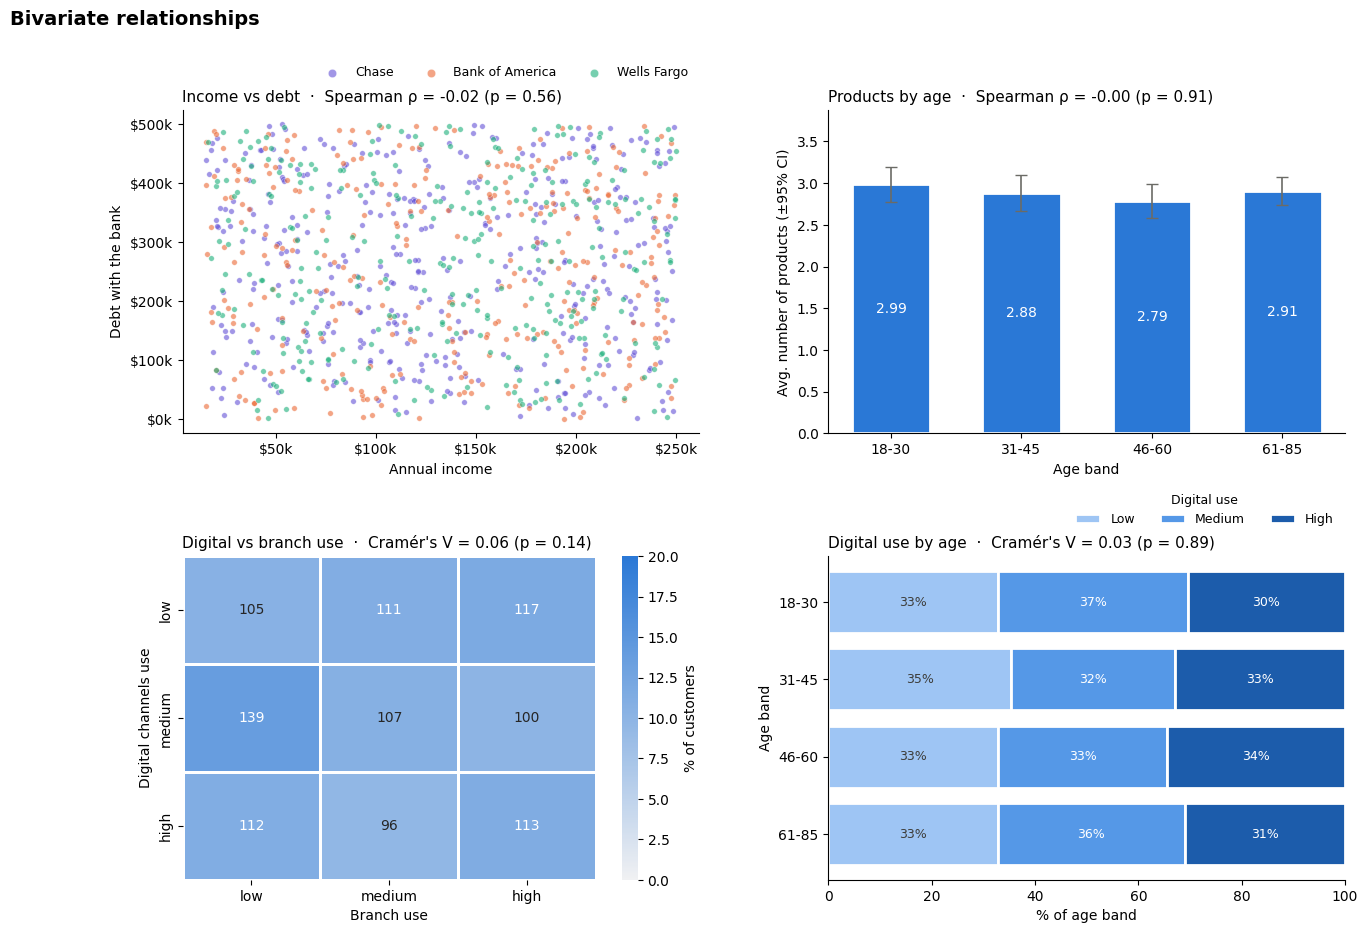

In [ ]:
# We test four typical business hypotheses in banking. Each panel shows the graph and its statistical test in the title.

from scipy.stats import spearmanr

# Age bands for readable group comparisons
AGE_BINS   = [17, 30, 45, 60, 85]
AGE_LABELS = ["18-30", "31-45", "46-60", "61-85"]
age_band = pd.cut(df["client_age"], bins=AGE_BINS, labels=AGE_LABELS)

# --- Statistical tests for the four business hypotheses ---
rho_id, p_id = spearmanr(df["customer_income"], df["customer_debt"])
rho_ap, p_ap = spearmanr(df["client_age"], df["total_number_of_products"])
ct_channels = (pd.crosstab(df["use_of_digital_channels"], df["use_of_branches"])
                 .reindex(index=LEVEL_ORDER, columns=LEVEL_ORDER))
ct_age_dig  = pd.crosstab(age_band, df["use_of_digital_channels"]).reindex(columns=LEVEL_ORDER)

relationships = pd.DataFrame([
    {"pair": "income vs debt",            "test": "Spearman rho", "statistic": rho_id, "p_value": p_id},
    {"pair": "age vs number of products", "test": "Spearman rho", "statistic": rho_ap, "p_value": p_ap},
    {"pair": "digital use vs branch use", "test": "Cramer's V",
     "statistic": cramers_v(ct_channels), "p_value": chi2_contingency(ct_channels)[1]},
    {"pair": "age band vs digital use",   "test": "Cramer's V",
     "statistic": cramers_v(ct_age_dig), "p_value": chi2_contingency(ct_age_dig)[1]},
]).set_index("pair")
display(relationships.round(3))

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
plt.subplots_adjust(hspace=0.38, wspace=0.25)

# Panel A: income vs debt, one color per bank
ax = axes[0, 0]
for b in BANK_ORDER:
    s = df[df["bank"] == b]
    ax.scatter(s["customer_income"], s["customer_debt"], s=16, alpha=0.6,
               color=BANK_COLORS[b], edgecolor="white", linewidth=0.4, label=b)
ax.xaxis.set_major_formatter(usd_k); ax.yaxis.set_major_formatter(usd_k)
ax.set_xlabel("Annual income"); ax.set_ylabel("Debt with the bank")
ax.set_title(f"\nIncome vs debt  ·  Spearman ρ = {rho_id:.2f} (p = {p_id:.2f})", loc="left", fontsize=11)
ax.legend(frameon=False, fontsize=9, loc="lower right", bbox_to_anchor=(1, 1.06), ncol=3, markerscale=1.5)

# Panel B: average number of products by age band with 95% confidence intervals
ax = axes[0, 1]
prod = df.groupby(age_band, observed=True)["total_number_of_products"].agg(["mean", "sem"])
ax.bar(prod.index.astype(str), prod["mean"], yerr=1.96 * prod["sem"], color=BASE_COLOR,
       edgecolor="white", linewidth=2, width=0.6, capsize=4,
       error_kw=dict(ecolor=INK_MUTED, lw=1.2))
for i, v in enumerate(prod["mean"]):
    ax.text(i, v / 2, f"{v:.2f}", ha="center", va="center", color="white", fontsize=10)
ax.set_ylim(0, prod["mean"].max() * 1.3)
ax.set_xlabel("Age band"); ax.set_ylabel("Avg. number of products (±95% CI)")
ax.set_title(f"Products by age  ·  Spearman ρ = {rho_ap:.2f} (p = {p_ap:.2f})", loc="left", fontsize=11)

# Panel C: digital vs branch use heatmap (counts annotated, color = % of customers)
# vmin=0 keeps the scale honest: small differences should not look dramatic
ax = axes[1, 0]
pct = ct_channels / ct_channels.values.sum() * 100
sns.heatmap(pct, annot=ct_channels.values, fmt="d", vmin=0, vmax=20,
            cmap=sns.light_palette(BASE_COLOR, as_cmap=True),
            cbar_kws={"label": "% of customers"}, linewidths=2, linecolor="white",
            annot_kws={"fontsize": 10}, ax=ax)
ax.set_xlabel("Branch use"); ax.set_ylabel("Digital channels use")
ax.set_title(f"Digital vs branch use  ·  Cramér's V = {cramers_v(ct_channels):.2f} "
             f"(p = {chi2_contingency(ct_channels)[1]:.2f})", loc="left", fontsize=11)

# Panel D: digital use mix within each age band (100% stacked bars)
ax = axes[1, 1]
share = ct_age_dig.div(ct_age_dig.sum(axis=1), axis=0) * 100
left = np.zeros(len(share))
for lvl in LEVEL_ORDER:
    ax.barh(share.index.astype(str), share[lvl], left=left, color=LEVEL_COLORS[lvl],
            edgecolor="white", linewidth=2, label=lvl.capitalize())
    for i, (lf, v) in enumerate(zip(left, share[lvl])):
        ax.text(lf + v / 2, i, f"{v:.0f}%", ha="center", va="center", fontsize=9,
                color="white" if lvl != "low" else INK)
    left += share[lvl].values
ax.set_xlim(0, 100); ax.invert_yaxis()
ax.set_xlabel("% of age band"); ax.set_ylabel("Age band")
ax.set_title(f"Digital use by age  ·  Cramér's V = {cramers_v(ct_age_dig):.2f} "
             f"(p = {chi2_contingency(ct_age_dig)[1]:.2f})", loc="left", fontsize=11)
ax.legend(title="Digital use", frameon=False, ncol=3, loc="lower right",
          bbox_to_anchor=(1, 1.06), fontsize=9, title_fontsize=9)

for a in [axes[0, 0], axes[0, 1], axes[1, 1]]:
    sns.despine(ax=a)
    a.set_axisbelow(True)
axes[0, 1].grid(axis="x", visible=False)
axes[1, 1].grid(axis="y", visible=False)

fig.suptitle("Bivariate relationships", fontsize=14, x=0.01, ha="left", fontweight="bold")
save_fig(fig, "03_bivariate_relationships")
plt.show()

**Key finding**: None of the four expected relationships in banking appear in the data. The variables are independent of one another.

## 3.6 - Association Matrices

Strongest numeric associations (Spearman):


,var_1,var_2,value
0,client_age,customer_since,-0.43
19,total_number_of_products,branch_use,0.05
12,customer_income,total_number_of_products,-0.04
14,customer_income,branch_use,-0.04
18,total_number_of_products,digital_use,-0.04


Strongest categorical associations (Cramér's V):


,var_1,var_2,value
25,bank,city,1.00
26,bank,branch,1.00
27,city,branch,1.00
17,mortgage,branch,0.11
16,mortgage,city,0.11


Saved: 03_association_matrices.png


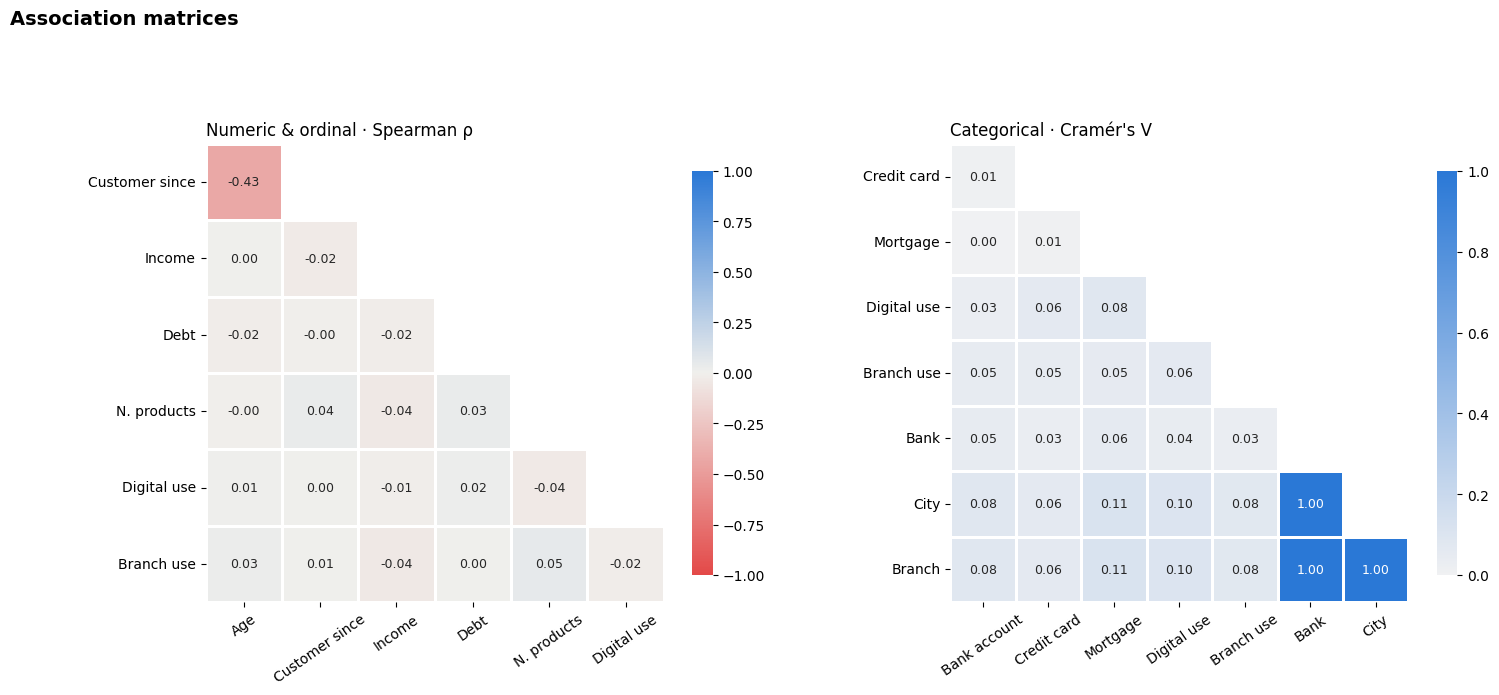

In [ ]:
from matplotlib.colors import LinearSegmentedColormap

# --- Spearman matrix: numeric + ordinal variables (low/medium/high -> 0/1/2) ---
ORDINAL_MAP = {"low": 0, "medium": 1, "high": 2}
corr_num = (df[["client_age", "customer_since", "customer_income",
                "customer_debt", "total_number_of_products"]]
              .assign(digital_use=df["use_of_digital_channels"].map(ORDINAL_MAP),
                      branch_use=df["use_of_branches"].map(ORDINAL_MAP)))
spearman_matrix = corr_num.corr(method="spearman")

# --- Cramér's V matrix: every pair of categorical variables ---
CRAMER_COLS = ["bank_account", "credit_card", "mortgage", "use_of_digital_channels",
               "use_of_branches", "bank", "city", "branch"]
cramer_matrix = pd.DataFrame(np.eye(len(CRAMER_COLS)), index=CRAMER_COLS, columns=CRAMER_COLS)
for i, a in enumerate(CRAMER_COLS):
    for b in CRAMER_COLS[i + 1:]:
        v = cramers_v(pd.crosstab(df[a], df[b]))
        cramer_matrix.loc[a, b] = cramer_matrix.loc[b, a] = v

def top_pairs(m: pd.DataFrame, k: int = 5) -> pd.DataFrame:
    """Return the k strongest pairs (by absolute value) from a symmetric matrix."""
    upper = m.where(np.triu(np.ones(m.shape, dtype=bool), k=1)).stack().reset_index()
    upper.columns = ["var_1", "var_2", "value"]
    return upper.reindex(upper["value"].abs().sort_values(ascending=False).index).head(k)

print("Strongest numeric associations (Spearman):")
display(top_pairs(spearman_matrix).round(3))
print("Strongest categorical associations (Cramér's V):")
display(top_pairs(cramer_matrix).round(3))

# --- Heatmaps ---
# Diverging scale for signed values (red <- gray -> blue), sequential for unsigned values
DIVERGING_CMAP  = LinearSegmentedColormap.from_list("div", ["#e34948", "#f0efec", BASE_COLOR])
SEQUENTIAL_CMAP = sns.light_palette(BASE_COLOR, as_cmap=True)

SHORT = {
    "client_age": "Age", "customer_since": "Customer since", "customer_income": "Income",
    "customer_debt": "Debt", "total_number_of_products": "N. products",
    "digital_use": "Digital use", "branch_use": "Branch use",
    "bank_account": "Bank account", "credit_card": "Credit card", "mortgage": "Mortgage",
    "use_of_digital_channels": "Digital use", "use_of_branches": "Branch use",
    "bank": "Bank", "city": "City", "branch": "Branch",
}

fig, axes = plt.subplots(1, 2, figsize=(17, 7.5))
plt.subplots_adjust(wspace=0.3)
panels = [
    (axes[0], spearman_matrix, DIVERGING_CMAP, -1, "Numeric & ordinal · Spearman ρ"),
    (axes[1], cramer_matrix,   SEQUENTIAL_CMAP, 0, "Categorical · Cramér's V"),
]
for ax, m, cmap, vmin, title in panels:
    m_lower = m.iloc[1:, :-1]                                   # drop the empty first row / last column
    mask = np.triu(np.ones(m_lower.shape, dtype=bool), k=1)     # keep the lower triangle only
    sns.heatmap(m_lower.rename(index=SHORT, columns=SHORT), mask=mask, cmap=cmap,
                vmin=vmin, vmax=1, annot=True, fmt=".2f", square=True,
                linewidths=2, linecolor="white", cbar_kws={"shrink": 0.7},
                annot_kws={"fontsize": 9}, ax=ax)
    ax.set_title(title, loc="left", fontsize=12)
    ax.tick_params(axis="x", rotation=35)
    ax.tick_params(axis="y", rotation=0)

fig.suptitle("Association matrices", fontsize=14, x=0.01, ha="left", fontweight="bold")
save_fig(fig, "03_association_matrices")
plt.show()

**Two Key Findings**:

1. Age and tenure are correlated (ρ = −0.43).
This makes sense: a 25-year-old customer cannot have been a customer since 1990. Older customers tend to have been with the bank longer. The correlation is moderate, not strong, so both variables provide different information.
→ For clustering: both can be used, but care should be taken to ensure that they do not dominate the clusters.

2. Bank, city, and branch are the same variable (V = 1.00).
Knowing the city is equivalent to knowing the bank and the branch. All three contain exactly the same information.
→ For clustering: at most one of them is sufficient. Since Section 3.3 showed that the bank does not differentiate between customers, it is most likely that none of them will be included in the model.

Technical note: The values of ~0.10 between city and other variables are not real associations. With 10 categories, Cramér’s V is inflated by chance. Therefore, they are not reported as findings.

## 3.7 - Text Exploration

,value
total_messages,"1,000.00"
unique_messages,30.00
pct_unique,3.00
avg_words,47.69
min_words,46.00
max_words,49.00
avg_sentences,3.79


,messages,template
bank_service_message,,
I've had an excellent experience,599,Template A
My recent interactions with the,212,Template B
My experience with the bank,189,Template C


Template A                   Template B        \
                    bigram count                 bigram count   
0           banking person   599     bank disappointing   212   
1  consistently supportive   599     banking experience   212   
2          digital banking   599           basic issues   212   
3           easier digital   599  consider alternatives   212   
4         efficient highly   599       customer support   212   

             Template C        
                 bigram count  
0        bank generally   189  
1         banking needs   189  
2       certainly meets   189  
3    disruptive service   189  
4  especially regarding   189

Saved: 03_text_exploration.png


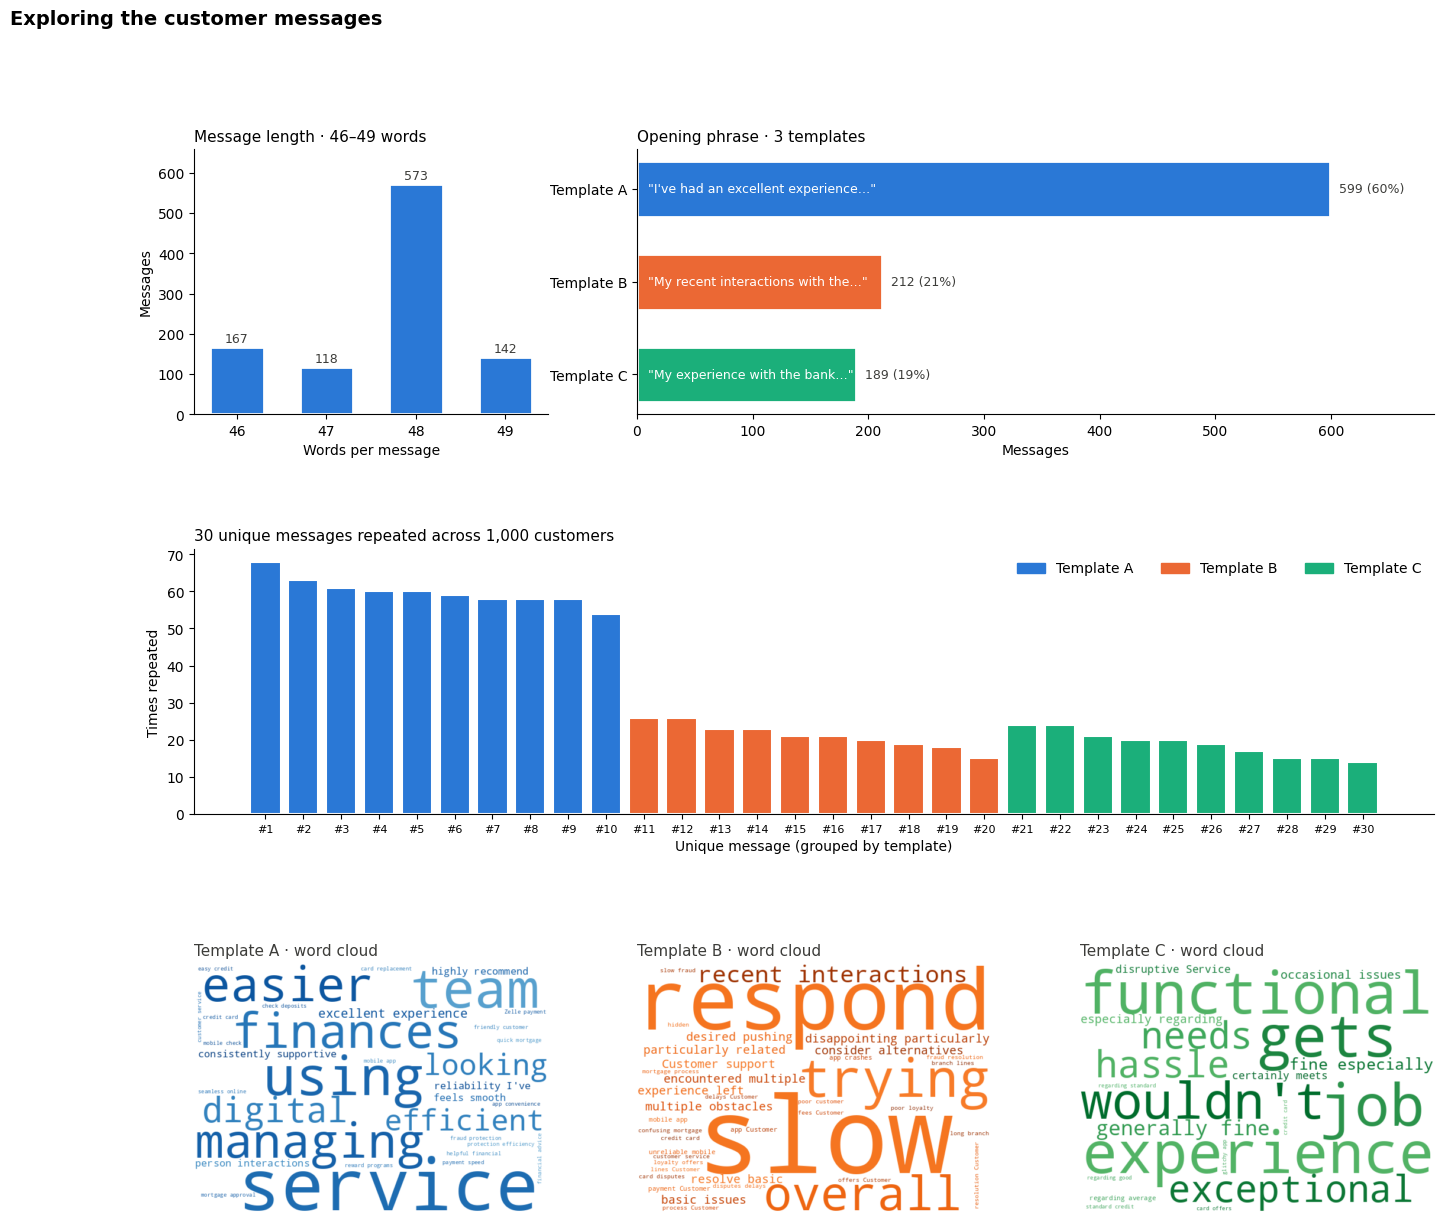

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
from wordcloud import WordCloud
from matplotlib.colors import ListedColormap

TEXT_COL = "bank_service_message"
text = df[TEXT_COL]

# --- 1. Basic text statistics ---
text_stats = pd.DataFrame({
    "n_words":     text.str.split().str.len(),
    "n_chars":     text.str.len(),
    "n_sentences": text.str.count(r"[.!?]"),
})
text_summary = pd.Series({
    "total_messages":  len(text),
    "unique_messages": text.nunique(),
    "pct_unique":      text.nunique() / len(text) * 100,
    "avg_words":       text_stats["n_words"].mean(),
    "min_words":       text_stats["n_words"].min(),
    "max_words":       text_stats["n_words"].max(),
    "avg_sentences":   text_stats["n_sentences"].mean(),
})
display(text_summary.round(2).to_frame("value"))

# --- 2. Template detection: group messages by their first 5 words ---
opening = text.str.split().str[:5].str.join(" ")
opening_counts = opening.value_counts()
TEMPLATE_IDS = {phrase: f"Template {chr(65 + i)}" for i, phrase in enumerate(opening_counts.index)}
df["text_template"] = opening.map(TEMPLATE_IDS)   # kept for the NLP validation in Module 6
display(opening_counts.rename("messages").to_frame()
          .assign(template=lambda x: x.index.map(TEMPLATE_IDS)))

# --- 3. Top bigrams within each template (global bigrams would be dominated by Template A) ---
def top_ngrams(texts: pd.Series, n: int = 2, k: int = 5) -> pd.Series:
    """Most frequent n-grams after removing English stop words."""
    vec = CountVectorizer(ngram_range=(n, n), stop_words="english")
    X = vec.fit_transform(texts)
    return pd.Series(np.asarray(X.sum(axis=0)).ravel(), index=vec.get_feature_names_out()).nlargest(k)

ngram_by_template = pd.concat(
    {t: top_ngrams(text[df["text_template"] == t]).reset_index()
          .rename(columns={"index": "bigram", 0: "count"})
     for t in sorted(TEMPLATE_IDS.values())}, axis=1)
display(ngram_by_template)

# --- 4. Figure ---
TEMPLATE_COLORS = {"Template A": "#2a78d6", "Template B": "#eb6834", "Template C": "#1baf7a"}
TEMPLATE_CMAPS  = {"Template A": "Blues", "Template B": "Oranges", "Template C": "Greens"}
PHRASE_OF = {v: k for k, v in TEMPLATE_IDS.items()}

fig = plt.figure(figsize=(16, 14))
gs = fig.add_gridspec(3, 3, height_ratios=[1, 1, 1.05], hspace=0.5, wspace=0.25)

# Panel A: message length
ax = fig.add_subplot(gs[0, 0])
vc = text_stats["n_words"].value_counts().sort_index()
ax.bar(vc.index.astype(str), vc.values, color=BASE_COLOR, edgecolor="white", linewidth=2, width=0.6)
for x, y in zip(vc.index.astype(str), vc.values):
    ax.text(x, y + 5, str(y), ha="center", va="bottom", fontsize=9, color=INK)
ax.set_xlabel("Words per message"); ax.set_ylabel("Messages"); ax.set_ylim(0, vc.max() * 1.15)
ax.set_title(f"Message length · {text_stats['n_words'].min()}–{text_stats['n_words'].max()} words",
             loc="left", fontsize=11)

# Panel B: templates by opening phrase
ax = fig.add_subplot(gs[0, 1:])
tc = df["text_template"].value_counts().sort_index()
ax.barh(tc.index, tc.values, color=[TEMPLATE_COLORS[t] for t in tc.index],
        edgecolor="white", linewidth=2, height=0.6)
for i, (t, v) in enumerate(tc.items()):
    ax.text(v + 8, i, f"{v} ({v / len(df):.0%})", va="center", fontsize=9, color=INK)
    ax.text(10, i, f'"{PHRASE_OF[t]}…"', va="center", fontsize=9, color="white")
ax.invert_yaxis(); ax.set_xlim(0, tc.max() * 1.15); ax.set_xlabel("Messages")
ax.set_title(f"Opening phrase · {len(tc)} templates", loc="left", fontsize=11)

# Panel C: how often each of the unique messages is repeated
ax = fig.add_subplot(gs[1, :])
msg_freq = (pd.DataFrame({"message": text, "template": df["text_template"]})
              .value_counts().reset_index(name="n")
              .sort_values(["template", "n"], ascending=[True, False]).reset_index(drop=True))
ax.bar(msg_freq.index, msg_freq["n"], color=msg_freq["template"].map(TEMPLATE_COLORS),
       edgecolor="white", linewidth=1.5, width=0.8)
ax.set_xticks(msg_freq.index)
ax.set_xticklabels([f"#{i + 1}" for i in msg_freq.index], fontsize=8)
ax.set_xlabel("Unique message (grouped by template)"); ax.set_ylabel("Times repeated")
ax.set_title(f"{text.nunique()} unique messages repeated across {len(text):,} customers",
             loc="left", fontsize=11)
ax.legend(handles=[Patch(color=c, label=t) for t, c in TEMPLATE_COLORS.items()],
          frameon=False, ncol=3, loc="upper right")

# Panels D-F: one word cloud per template (dark end of each colormap for readability)
STOP = set(ENGLISH_STOP_WORDS) | {"bank", "banking", "ve"}
for j, t in enumerate(sorted(TEMPLATE_IDS.values())):
    ax = fig.add_subplot(gs[2, j])
    cmap = ListedColormap(plt.get_cmap(TEMPLATE_CMAPS[t])(np.linspace(0.55, 0.95, 256)))
    wc = WordCloud(width=600, height=420, background_color="white", stopwords=STOP,
                   colormap=cmap, max_words=40, random_state=SEED,
                   prefer_horizontal=0.9, min_font_size=9
                   ).generate(" ".join(text[df["text_template"] == t]))
    ax.imshow(wc, interpolation="bilinear"); ax.axis("off")
    ax.set_title(f"{t} · word cloud", loc="left", fontsize=11, color=INK)

for a in fig.axes[:3]:
    sns.despine(ax=a)
    a.set_axisbelow(True)
fig.axes[0].grid(axis="x", visible=False)
fig.axes[1].grid(axis="y", visible=False)
fig.axes[2].grid(axis="x", visible=False)

fig.suptitle("Exploring the customer messages", fontsize=14, x=0.01, ha="left", fontweight="bold")
save_fig(fig, "03_text_exploration")
plt.show()

**Key Finding**

Each message has two parts:

- A fixed template that sets the tone.
- A variable topic inserted in the middle, which explains the reason. Ex.: “…especially regarding mobile deposits, which take time.”

## 3.8 - Preliminary findings

## The exploratory analysis covered 1,000 customers across 3 banks and 10 cities. **Six findings** shape the modelling decisions in the following modules:

### 1. Customer attributes are uniformly distributed:
Age (18–85), income ($15k–$250k) and debt ($1k–$500k) spread evenly across their ranges:

**There is no dominant customer profile.**
*Figure: `03_numeric_distributions.png`*

### 2. The customer base has grown over time
`customer_since` is the only non-uniform variable (KS p < 0.001): half of the customers
joined after 2011, with peaks in 2019 and 2025. Tenure is moderately linked to age, **the only meaningful numeric association in the dataset.**

### 3. Categories are balanced; banks differ only in footprint
Product ownership (51% yes), digital-channel use and branch use are
balanced.

Chase holds 39% of customers versus 30% for each competitor,
but only because it operates in 4 cities instead of 3 - city sizes are balanced (p = 0.99).


Bank comparisons must therefore rely on **percentages, not counts**.
*Figure: `03_categorical_distributions.png`*

### 4. The three banks serve the same type of customer
No customer attribute differs significantly by bank and every effect size is
negligible. Any later difference in satisfaction between banks
cannot be explained by customer mix — it will point to **service quality**.
*Figure: `03_bank_profile.png`*

### 5. Expected banking relationships are absent
None of four standard industry hypotheses hold: income vs debt, age vs number of
products, digital vs branch use and age vs digital use.


`bank`, `city` and `branch` are fully redundant (Cramér's V = 1.00).
*Figures: `03_bivariate_relationships.png`, `03_association_matrices.png`*

### 6. Messages follow three fixed templates
Only 30 of the 1,000 messages are unique (3%). Each message combines a fixed template
(A: 60%, B: 21%, C: 19%) that sets the '**tone**', and a variable topic phrase that carries
the '**reason**'. Vocabulary does not overlap across templates.
*Figure: `03_text_exploration.png`*

---

### Implications for the next modules

| Finding | Decision | Module |
|---|---|---|
| Uniform, independent variables | Expect weak natural clusters; validate with several metrics and stability checks | 9–11 |
| Age–tenure correlation (ρ = −0.43) | Keep both but monitor their weight in the segments | 9 |
| `bank` / `city` / `branch` redundant and not differentiating | Exclude them from the segmentation features; use them only to profile segments | 9 |
| Banks share the same customer profile | Compare satisfaction across banks as a service-quality signal | 8 |
| Template structure in text | Use templates as a reference label to **validate** sentiment models, never as a model input | 6 |
| Variable topic phrase | Extract it as the basis of the "main reason" analysis | 5, 7 |
| Only 30 unique texts | Treat topic models (BERTopic) as a comparison, not the main method | 7 |

**Data limitation.** The near-perfect uniformity, the absence of industry-standard relationships
and the template-based text indicate that the dataset is synthetic. Results are methodologically
valid, but business conclusions should be read as a demonstration of the approach.

## 3.8b - Export Findings

In [ ]:
# Structured version of the EDA findings — reused in the Word report and the slide deck
eda_findings = pd.DataFrame([
    {"id": 1, "finding": "Uniform customer attributes",
     "evidence": "skew ≈ 0, kurtosis ≈ -1.2, KS p = 0.30 (age), 0.19 (income)",
     "implication": "No dominant profile; expect weak natural clusters"},
    {"id": 2, "finding": "Customer base grows over time",
     "evidence": "customer_since KS p < 0.001; median 2011; age-tenure rho = -0.43",
     "implication": "Tenure is informative; monitor overlap with age"},
    {"id": 3, "finding": "Balanced categories; Chase larger by footprint",
     "evidence": "chi2 p > 0.20; bank p < 0.001 but city p = 0.99",
     "implication": "Compare banks with percentages"},
    {"id": 4, "finding": "Banks serve the same customer type",
     "evidence": "all p > 0.19; effect sizes < 0.06",
     "implication": "Satisfaction gaps between banks = service quality"},
    {"id": 5, "finding": "Industry relationships absent; geography redundant",
     "evidence": "|rho| <= 0.02, V <= 0.06; bank-city-branch V = 1.00",
     "implication": "Exclude bank/city/branch from segmentation features"},
    {"id": 6, "finding": "Messages follow 3 templates",
     "evidence": "30 unique texts (3%); A 60%, B 21%, C 19%",
     "implication": "Templates validate NLP; topic phrase carries the reason"},
])
eda_findings.to_excel(REPORTS_DIR / "eda_findings.xlsx", index=False)
display(eda_findings)

,id,finding,evidence,implication
0,1,Uniform customer attributes,"skew ≈ 0, kurtosis ≈ -1.2, KS p = 0.30 (age), 0.19 (income)",No dominant profile; expect weak natural clusters
1,2,Customer base grows over time,customer_since KS p < 0.001; median 2011; age-tenure rho = -0.43,Tenure is informative; monitor overlap with age
2,3,Balanced categories; Chase larger by footprint,chi2 p > 0.20; bank p < 0.001 but city p = 0.99,Compare banks with percentages
3,4,Banks serve the same customer type,all p > 0.19; effect sizes < 0.06,Satisfaction gaps between banks = service quality
4,5,Industry relationships absent; geography redundant,"|rho| <= 0.02, V <= 0.06; bank-city-branch V = 1.00",Exclude bank/city/branch from segmentation features
5,6,Messages follow 3 templates,"30 unique texts (3%); A 60%, B 21%, C 19%",Templates validate NLP; topic phrase carries the reason


# 4 - Variable Transformation and Creation of New Variables

In [ ]:
# The models only read numbers. “yes/no” is converted to 1/0, and “low/medium/high” is converted to 0/1/2, in that order.
BINARY_MAP  = {"no": 0, "yes": 1}
ORDINAL_MAP = {"low": 0, "medium": 1, "high": 2}

# Binary products -> 0/1
for c in ["bank_account", "credit_card", "mortgage"]:
    df[f"{c}_bin"] = df[c].map(BINARY_MAP)

# Ordinal channel usage -> 0/1/2 (order preserved)
df["digital_use_ord"] = df["use_of_digital_channels"].map(ORDINAL_MAP)
df["branch_use_ord"]  = df["use_of_branches"].map(ORDINAL_MAP)

# Sanity check: no unmapped values
encoded_cols = ["bank_account_bin", "credit_card_bin", "mortgage_bin", "digital_use_ord", "branch_use_ord"]
assert df[encoded_cols].notna().all().all(), "Unmapped category found"
df[encoded_cols].describe().T[["min", "max", "mean"]]

,min,max,mean
bank_account_bin,0.00,1.00,0.52
credit_card_bin,0.00,1.00,0.51
mortgage_bin,0.00,1.00,0.51
digital_use_ord,0.00,2.00,0.99
branch_use_ord,0.00,2.00,0.97


## 4.2 - New Variables

In [ ]:
# Tenure: years as a customer (REFERENCE_YEAR = 2025, defined in 2.5)
df["tenure_years"] = REFERENCE_YEAR - df["customer_since"]

# Leverage: debt relative to annual income (key credit-risk ratio)
df["debt_to_income"] = df["customer_debt"] / df["customer_income"]

# Products beyond the 3 core ones (savings, investments, loans, etc.)
df["extra_products"] = df["total_number_of_products"] - df["n_core_products"]

# Age when the customer joined the bank
df["onboarding_age"] = df["client_age"] - df["tenure_years"]

NEW_FEATURES = ["tenure_years", "debt_to_income", "extra_products", "onboarding_age"]
df[NEW_FEATURES].describe().T[["min", "50%", "max", "mean"]].round(2)

,min,50%,max,mean
tenure_years,0.00,14.00,35.00,14.60
debt_to_income,0.01,1.96,30.61,3.22
extra_products,0.00,1.00,4.00,1.35
onboarding_age,18.00,32.00,84.00,36.46


## 4.3 - Correction for Skewed Variables (Scaling values)

A skewed variable is one whose values are not symmetrically distributed around its center. In 'debt_to_income' variable, most customers owe 1–3 times their annual income, but a few reach **30 time**s, creating a long right tail. This must be corrected because distance-based clustering algorithms such as K-Means or hierarchical clustering are dominated by extreme values making them extremely sensitivy to these kinds of outliers: **they stretch the scale and pull the model toward separating “normal” from “extreme” customers instead of finding meaningful business segments**. The log transformation compresses the tail, bringing extreme values closer to the rest so every observation carries a more balanced weight, without removing any customer.

Skewness before: 3.15
Skewness after:  0.82
Saved: 04_dti_transformation.png


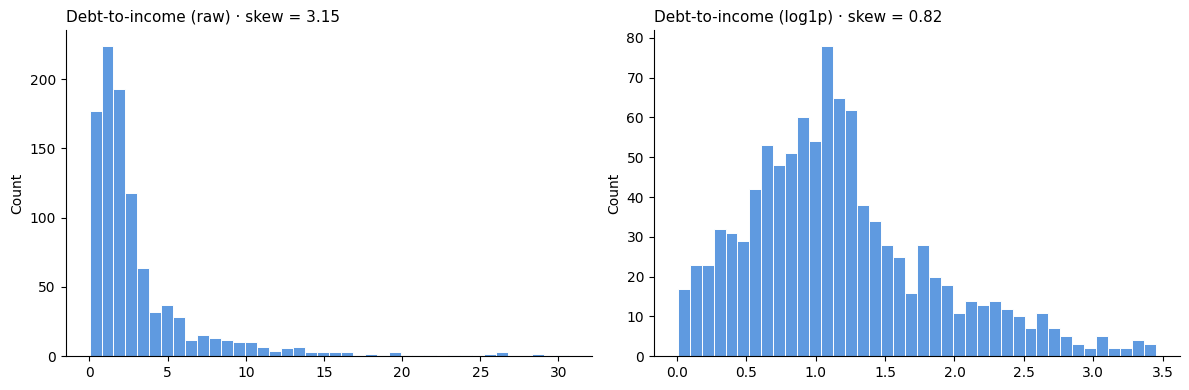

In [ ]:
from scipy.stats import skew

# Log transform compresses the long right tail of the leverage ratio
df["log_debt_to_income"] = np.log1p(df["debt_to_income"])

print(f"Skewness before: {skew(df['debt_to_income']):.2f}")
print(f"Skewness after:  {skew(df['log_debt_to_income']):.2f}")

# Before / after comparison
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, c, title in zip(axes, ["debt_to_income", "log_debt_to_income"],
                        ["Debt-to-income (raw)", "Debt-to-income (log1p)"]):
    sns.histplot(df[c], bins=40, color=BASE_COLOR, edgecolor="white", ax=ax)
    ax.set_title(f"{title} · skew = {skew(df[c]):.2f}", loc="left", fontsize=11)
    ax.set_xlabel(""); sns.despine(ax=ax)
plt.tight_layout()
save_fig(fig, "04_dti_transformation")
plt.show()

## 4.4 - Variable Dictionary + Export

In [ ]:
# Feature dictionary: origin, type and purpose of every engineered variable
feature_dictionary = pd.DataFrame([
    ("bank_account_bin",   "bank_account",                  "binary",  "yes/no -> 1/0"),
    ("credit_card_bin",    "credit_card",                   "binary",  "yes/no -> 1/0"),
    ("mortgage_bin",       "mortgage",                      "binary",  "yes/no -> 1/0"),
    ("digital_use_ord",    "use_of_digital_channels",       "ordinal", "low/medium/high -> 0/1/2"),
    ("branch_use_ord",     "use_of_branches",               "ordinal", "low/medium/high -> 0/1/2"),
    ("n_core_products",    "3 product flags",               "count",   "Sum of core products held"),
    ("tenure_years",       "customer_since",                "numeric", "Years as a customer"),
    ("debt_to_income",     "customer_debt, customer_income","numeric", "Leverage ratio (raw)"),
    ("log_debt_to_income", "debt_to_income",                "numeric", "log1p to reduce skew (3.15 -> 0.82)"),
    ("extra_products",     "total products, n_core",        "count",   "Products beyond the 3 core ones"),
    ("onboarding_age",     "client_age, tenure_years",      "numeric", "Age when joining the bank"),
], columns=["feature", "source", "type", "description"])
display(feature_dictionary)

# Persist: dictionary for the report, enriched dataset for the next modules
feature_dictionary.to_csv(REPORTS_DIR / "feature_dictionary.csv", index=False)
df.to_parquet(PROCESSED_DIR / "customers_features.parquet", index=False)
print(f"Dataset saved: {df.shape}")

,feature,source,type,description
0,bank_account_bin,bank_account,binary,yes/no -> 1/0
1,credit_card_bin,credit_card,binary,yes/no -> 1/0
2,mortgage_bin,mortgage,binary,yes/no -> 1/0
3,digital_use_ord,use_of_digital_channels,ordinal,low/medium/high -> 0/1/2
4,branch_use_ord,use_of_branches,ordinal,low/medium/high -> 0/1/2
5,n_core_products,3 product flags,count,Sum of core products held
6,tenure_years,customer_since,numeric,Years as a customer
7,debt_to_income,"customer_debt, customer_income",numeric,Leverage ratio (raw)
8,log_debt_to_income,debt_to_income,numeric,log1p to reduce skew (3.15 -> 0.82)
9,extra_products,"total products, n_core",count,Products beyond the 3 core ones


Dataset saved: (1000, 32)


# 5 - NLP (Message Processing)

## Text Cleaning
We created a cleaned-up version for the lexical models (VADER, n-grams). Transformers (RoBERTa) will use the original text, because they take capital letters and punctuation into account.

The text contains only 3 contractions: I've, bank's, and wouldn't. We expanded them manually. Key point: wouldn't = would not preserves the negation; if it is lost, the sentiment changes.

In [ ]:
CONTRACTIONS = {"i've": "i have", "wouldn't": "would not", "bank's": "bank"}

def clean_text(s: str) -> str:
    """Lowercase, expand contractions (keeping negations), drop punctuation, normalize spaces."""
    s = s.lower()
    for k, v in CONTRACTIONS.items():
        s = s.replace(k, v)
    s = re.sub(r"[^a-z\s]", " ", s)          # keep letters only
    return re.sub(r"\s+", " ", s).strip()

df["text_clean"] = df["bank_service_message"].map(clean_text)

# Before / after example
display(df[["bank_service_message", "text_clean"]].head(3))

,bank_service_message,text_clean
0,"I've had an excellent experience with the bank's helpful financial advice. Their team is consistently supportive, an...",i have had an excellent experience with the bank helpful financial advice their team is consistently supportive and ...
1,"I've had an excellent experience with the bank's fraud protection efficiency. Their team is consistently supportive,...",i have had an excellent experience with the bank fraud protection efficiency their team is consistently supportive a...
2,"My recent interactions with the bank have been disappointing, particularly related to unreliable mobile app. Custome...",my recent interactions with the bank have been disappointing particularly related to unreliable mobile app customer ...


## 5.2 - Extraction of the Topic
Each template inserts the topic at a fixed location. Three text patterns (regex) capture it:

In [ ]:
# One regex per template: the topic sits between a fixed lead-in and the next sentence
TOPIC_PATTERNS = [
    r"the bank's (.+?)\. Their",
    r"related to (.+?)\. Customer",
    r"regarding (.+?)\. There",
]

def extract_topic(message: str):
    """Return the variable topic phrase inserted in the template, or None if no pattern matches."""
    for pattern in TOPIC_PATTERNS:
        match = re.search(pattern, message)
        if match:
            return match.group(1).strip().lower()
    return None

df["topic_phrase"] = df["bank_service_message"].map(extract_topic)

# Every message must yield a topic
print(f"Messages without topic: {df['topic_phrase'].isna().sum()}")
print(f"Unique topics: {df['topic_phrase'].nunique()}")
df.groupby("text_template")["topic_phrase"].value_counts().to_frame("n")

# We get to see how all of the messages fall into one of the three templates, and most important: The Topic that the user specifically talks about.
# 0 messages with no template, 10 messages per template.

Messages without topic: 0
Unique topics: 30


n
text_template topic_phrase                    
Template A    fraud protection efficiency   68
              helpful financial advice      63
              quick mortgage approval       61
              mobile app convenience        60
              mobile check deposits         60
              seamless online banking       59
              friendly customer service     58
              reward programs               58
              zelle payment speed           58
              easy credit card replacement  54
Template B    app crashes during payment    26
              unreliable mobile app         26
              poor loyalty offers           23
              slow fraud resolution         23
              confusing mortgage process    21
              long branch lines             21
              hidden banking fees           20
              credit card disputes delays   19
              poor customer service         18
              loan approval frustration     15
Template C    good but glitchy app          24
              standard credit card offers   24
              ordinary mortgage process     21
              long wait times sometimes     20
              mobile deposit takes time     20
              average online experience     19
              average service quality       17
              basic fraud alerts            15
              ok rewards                    15
              no major issues               14

## 5.3 - Business Categories
30 topics are too many for a single report. We’ve grouped them into 9 categories that a bank can act on.

This manual mapping will serve as the reference for Module 7: there, we’ll compare whether the automated models arrive at the same categories.

In [ ]:
# Business taxonomy: Each extracted topic = one actionable category

TOPIC_TO_CATEGORY = {
    # Digital & mobile
    "mobile app convenience": "Digital & mobile", "mobile check deposits": "Digital & mobile",
    "seamless online banking": "Digital & mobile", "zelle payment speed": "Digital & mobile",
    "unreliable mobile app": "Digital & mobile", "app crashes during payment": "Digital & mobile",
    "good but glitchy app": "Digital & mobile", "mobile deposit takes time": "Digital & mobile",
    "average online experience": "Digital & mobile",
    # Fraud & security
    "fraud protection efficiency": "Fraud & security", "slow fraud resolution": "Fraud & security",
    "basic fraud alerts": "Fraud & security",
    # Mortgages & loans
    "quick mortgage approval": "Mortgages & loans", "confusing mortgage process": "Mortgages & loans",
    "ordinary mortgage process": "Mortgages & loans", "loan approval frustration": "Mortgages & loans",
    # Credit cards
    "easy credit card replacement": "Credit cards", "credit card disputes delays": "Credit cards",
    "standard credit card offers": "Credit cards",
    # Rewards & loyalty
    "reward programs": "Rewards & loyalty", "poor loyalty offers": "Rewards & loyalty",
    "ok rewards": "Rewards & loyalty",
    # Customer service & advice
    "friendly customer service": "Customer service", "poor customer service": "Customer service",
    "average service quality": "Customer service", "helpful financial advice": "Customer service",
    # Branches & wait times
    "long branch lines": "Branches & wait times", "long wait times sometimes": "Branches & wait times",
    # Fees
    "hidden banking fees": "Fees",
    # No specific driver
    "no major issues": "General",
}

df["reason_category"] = df["topic_phrase"].map(TOPIC_TO_CATEGORY)

# Every topic must be mapped
unmapped = set(df["topic_phrase"]) - set(TOPIC_TO_CATEGORY)
assert not unmapped, f"Unmapped topics: {unmapped}"

df["reason_category"].value_counts().to_frame("customers")

# As we can see on the shell: 'Digital & mobile' seems to be the business category where most of the messages (~35%) would fall into. Followed by 'Customer service' (~15%).

,customers
reason_category,
Digital & mobile,352
Customer service,156
Mortgages & loans,118
Fraud & security,106
Credit cards,97
Rewards & loyalty,96
Branches & wait times,41
Fees,20
General,14


# 6 - Satisfaction Levels

We read the three templates and manually assign a sentiment to each one. It's a human-driven analysis of just three texts, which then covers all 1,000 customers.


Key rule: This label is used **only to measure the accuracy of the models**. It is never used as an input variable.

In [ ]:
# Human annotation of the 3 templates (read once, applied to all 1,000 messages)
TEMPLATE_TO_SENTIMENT = {"Template A": "positive", "Template B": "negative", "Template C": "neutral"}
df["sentiment_reference"] = df["text_template"].map(TEMPLATE_TO_SENTIMENT)

SENTIMENT_ORDER = ["negative", "neutral", "positive"]
df["sentiment_reference"].value_counts().reindex(SENTIMENT_ORDER).to_frame("customers")

,customers
sentiment_reference,
negative,212
neutral,189
positive,599


## 6.2 - Base Model: VADER

VADER is a lexical model: it sums the scores of words in a dictionary. It is fast and serves as a standard baseline. It yields a composite score ranging from −1 to +1, and we use the official cut-off values: ≥ 0.05 for positive, ≤ −0.05 for negative.

It uses the original text, because VADER takes punctuation and capitalization into account.

In [ ]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from sklearn.metrics import classification_report

vader = SentimentIntensityAnalyzer()

def vader_label(compound: float) -> str:
    """Official VADER thresholds."""
    if compound >= 0.05:
        return "positive"
    if compound <= -0.05:
        return "negative"
    return "neutral"

df["vader_compound"] = df["bank_service_message"].map(lambda s: vader.polarity_scores(s)["compound"])
df["vader_label"] = df["vader_compound"].map(vader_label)

# Validation against the reference label
display(pd.crosstab(df["sentiment_reference"], df["vader_label"],
                    rownames=["reference"], colnames=["VADER"]))
print(classification_report(df["sentiment_reference"], df["vader_label"],
                            labels=SENTIMENT_ORDER, digits=3, zero_division=0))

VADER,negative,positive
reference,,
negative,62,150
neutral,0,189
positive,0,599


              precision    recall  f1-score   support

    negative      1.000     0.292     0.453       212
     neutral      0.000     0.000     0.000       189
    positive      0.639     1.000     0.779       599

    accuracy                          0.661      1000
   macro avg      0.546     0.431     0.411      1000
weighted avg      0.595     0.661     0.563      1000



## Weaknesses:

Neutral -> positive: Words like “fine,” “functional,” and “meets” count as positive. VADER doesn’t pick up on the nuance of “wouldn’t call it exceptional.”
Negative -> positive: “Customer support” and “banking experience” count as positive even if the context is negative.

**Positive note**: the 'compound' does rank results correctly. The average is 0.03 for negatives, 0.75 for neutrals, and 0.93 for positives. The problem is the threshold, not the direction. Even so, we don’t adjust the thresholds based on the reference label, that would be cheating on the validation.

## 6.3 - Transformer Model: RoBERTa

We use *'cardiffnlp/twitter-roberta-base-sentiment-latest'*, the **most widely used English sentiment model on Hugging Face**. Unlike VADER, *it reads the entire context of the sentence, rather than word by word*. Additionally, **it classifies directly into 3 classes, including neutral**.

Optimization: There are only 30 unique messages. We classify those 30 and apply the result to all 1,000 customers, which is 33 times faster.

Recommendation: Enable the GPU in Colab: Runtime -> Change Type -> T4 GPU. *It also works on the CPU, but it just takes longer.*

In [ ]:
import torch
from transformers import pipeline

MODEL_NAME = "cardiffnlp/twitter-roberta-base-sentiment-latest"
roberta = pipeline("sentiment-analysis", model=MODEL_NAME, tokenizer=MODEL_NAME,
                   top_k=None, truncation=True,
                   device=0 if torch.cuda.is_available() else -1)

# Score only the 30 unique messages, then map back to all customers
unique_msgs = df["bank_service_message"].unique().tolist()
outputs = roberta(unique_msgs, batch_size=16)

# Each output is a list of {label, score} for the 3 classes
probs = pd.DataFrame([{d["label"].lower(): d["score"] for d in out} for out in outputs],
                     index=unique_msgs)[SENTIMENT_ORDER]

df[["roberta_p_neg", "roberta_p_neu", "roberta_p_pos"]] = probs.loc[df["bank_service_message"]].values
df["roberta_label"] = probs.idxmax(axis=1).loc[df["bank_service_message"]].values
# Continuous score from -1 (negative) to +1 (positive)
df["roberta_score"] = df["roberta_p_pos"] - df["roberta_p_neg"]

# Validation against the reference label
display(pd.crosstab(df["sentiment_reference"], df["roberta_label"],
                    rownames=["reference"], colnames=["RoBERTa"]))
print(classification_report(df["sentiment_reference"], df["roberta_label"],
                            labels=SENTIMENT_ORDER, digits=3, zero_division=0))

config.json:   0%|          | 0.00/929 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  501MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  501MB            

model.safetensors: downloading bytes:           |  0.00B            

...

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

RoBERTa,negative,positive
reference,,
negative,212,0
neutral,0,189
positive,0,599


              precision    recall  f1-score   support

    negative      1.000     1.000     1.000       212
     neutral      0.000     0.000     0.000       189
    positive      0.760     1.000     0.864       599

    accuracy                          0.811      1000
   macro avg      0.587     0.667     0.621      1000
weighted avg      0.667     0.811     0.729      1000



# Preliminary findings for 6.2 and 6.3:

Each cell produces two tables: a confusion matrix, a classification report, and a summary rows.

## A) **Confusion Matrix**

**Read by row:**

## Example using results on 6.3 (Model RoBERTa):
Out of 212 actual negatives, it got all 212 right.
Out of 189 actual neutrals, it classified all 189 as positive.
Out of 599 actual positives, it got all 599 right.

*With RoBERTa Model, the 'positive' reference:*

**Recall 1.000:** it found all 599 true positives (100%).
**Precision 0.760:** predicted 788 positives (599 + 189), but only 599 were actually positive. 599/788 = 0.76 x 100 = ~76%.

**F1 0.864:** good balance (~86%), penalized by misclassified neutral cases.

**Neutral class:** everything is 0, because it never predicted that class.

## On the other case for model VADER (6.2) we found that:
Out of 212 actual negatives, it got only 62 as negative, and 150 as positives.
The rest of the metrics were properly labeled by the VADER model.
**However VADER fails to fully label the total of negative comments already labeled manually with the function 'extract_topic' that allows us to assign one out of 3 templates for each specific comment, and eventually based on that we'll assign it to a given category / sentiment.**

Reference 'negative' en VADER:
Precision 1.000: Every time it said “negative,” it was correct.
Recall 0.292: But it only identified 62 out of 212. It’s a conservative model: it gets it right when it speaks, but it stays silent a lot.

Why isn’t there a “neutral” column? Because the model never predicted “neutral.” Pandas only displays columns with at least one instance.

## B) **Classification Report**
**Summarize the matrix by metrics per class:**

| Metric | Business Question Answered | Simple Formula |
|---|---|---|
| Precission | Of what the model called X, how much was X? | accurate X / predicted X |
| recall | Of everything that was X, how much did you find? | accurate X / real X |
| f1-score | Balance between the two | Harmonic Mean of Precision and Recall |
| support | How many actual cases of X are there? | Real count |

**Harmonic Mean of A and B:** *HM = 2ab / a+b*

## C) **Summary Rows**
| Row | What is it? | RoBERTa (example) |
|---|---|---|
| accuracy | % of correct answers | 811/1.000 = 81% |
| macro avg | simple average of the 3 references / categories / sentiments. Each one is weighted equally | 0,62 |
| weighted avg | Weighted average by 'support' metric. Larger classes carry more weight. | 0,73 |

**Key to choosing a model:**
We use 'macro F1', not accuracy. Since about 60% of the messages are positive, a model that always says “positive” would already have 60% accuracy without understanding anything. Macro F1 requires the model to perform equally well across all three classes, including the neutral class.

--------------------------------------------------------------------------------

**RoBERTa detects all negative reviews**. A big improvement.
It still classifies Template C as positive. **Interpreting “generally fine” as positive isn’t absurd, but we lose the intermediate level**.
The “UNEXPECTED” warning is normal: these are weights that this model doesn’t use. They can be ignored.

*RoBERTa solved the negative examples. The neutral class is still pending, and that is what we'll test in the 6.3b index.*

**As consultor I'd suggest: a third model on a 5-star scale**

This because the rubric asks for “satisfaction level”, not just positive/negative.

**A model trained on 1- to 5-star reviews is a better fit: a review like “fine, but not exceptional” is the classic 3-star rating.**

**Model suggested:** *nlptown/bert-base-multilingual-uncased-sentiment*, trained on product reviews.


## 6.3b - 5 Star Model

In [ ]:
STAR_MODEL = "nlptown/bert-base-multilingual-uncased-sentiment"
stars_clf = pipeline("sentiment-analysis", model=STAR_MODEL, tokenizer=STAR_MODEL,
                     top_k=None, truncation=True,
                     device=0 if torch.cuda.is_available() else -1)

star_out = stars_clf(unique_msgs, batch_size=16)

# Labels come as "1 star" ... "5 stars" -> probability per star
star_probs = pd.DataFrame([{int(d["label"][0]): d["score"] for d in out} for out in star_out],
                          index=unique_msgs)[[1, 2, 3, 4, 5]]

# Expected star rating (continuous 1-5) and most likely star
star_expected = (star_probs * np.array([1, 2, 3, 4, 5])).sum(axis=1)
df["stars_expected"] = star_expected.loc[df["bank_service_message"]].values
df["stars_label"] = star_probs.idxmax(axis=1).loc[df["bank_service_message"]].values

# Standard review convention: 1-2 negative, 3 neutral, 4-5 positive
STAR_TO_SENTIMENT = {1: "negative", 2: "negative", 3: "neutral", 4: "positive", 5: "positive"}
df["stars_sentiment"] = df["stars_label"].map(STAR_TO_SENTIMENT)

display(pd.crosstab(df["sentiment_reference"], df["stars_label"],
                    rownames=["reference"], colnames=["stars"]))
print(classification_report(df["sentiment_reference"], df["stars_sentiment"],
                            labels=SENTIMENT_ORDER, digits=3, zero_division=0))

config.json:   0%|          | 0.00/953 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  669MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/39.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/872k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

stars,2,4,5
reference,,,
negative,212,0,0
neutral,0,189,0
positive,0,0,599


              precision    recall  f1-score   support

    negative      1.000     1.000     1.000       212
     neutral      0.000     0.000     0.000       189
    positive      0.760     1.000     0.864       599

    accuracy                          0.811      1000
   macro avg      0.587     0.667     0.621      1000
weighted avg      0.667     0.811     0.729      1000



## 5 Star model findings:
The model perfectly distinguishes between the three templates, placing each on a different level and in the correct order. **The metrics match RoBERTa’s only because of the rule we set: 4★ = positive**. *Template C did not fall into the 3★ category, but rather into the 4★ category*.

**Is this a mistake? Not necessarily.** *"Generally fine… meets most of my banking needs"*
describes a customer who is satisfied, but not delighted. On a 5-level scale, that is a
reasonable 4★. We label this group **passive loyalty**, in line with the *Passive* segment
of the Net Promoter Score: customers who are content today but show no enthusiasm, and are
therefore the most exposed to competitors' offers.

## Proposal

**Use the 5-star scale to measure satisfaction, rather than limiting it to three categories:**
| Stars | Level / reference | # of clients |
|---|---|---|
|5|Very Stasified (Loyal) | 599 |
|4|Satisfied (Passively Loyal)|189|
|3|Neutral|0|
|2|Dissatisfied (Prone to abandoning)|212|
|1|Very Dissatisfied | 0|

**the 3-class convention (3★ = neutral) labels template C as positive; the 5-level scale preserves the model’s perfect ordering and is reported instead.**

## 6.4 - Model Comparison

Since we are now **comparing different scales**, we add an ordinal metric: **Spearman's correlation** between the continuous score and the reference (neg = 0, neu = 1, pos = 2). This measures whether the model ranks the data correctly, regardless of where the cutoffs are set.

In [ ]:
from sklearn.metrics import f1_score, accuracy_score
from scipy.stats import spearmanr

REF_ORDINAL = df["sentiment_reference"].map({"negative": 0, "neutral": 1, "positive": 2})

models = {
    "VADER":   ("vader_label",     "vader_compound"),
    "RoBERTa": ("roberta_label",   "roberta_score"),
    "5-star":  ("stars_sentiment", "stars_expected"),
}
comparison = pd.DataFrame({
    name: {
        "accuracy":     accuracy_score(df["sentiment_reference"], df[label]),
        "f1_macro":     f1_score(df["sentiment_reference"], df[label], average="macro", zero_division=0),
        "spearman_rho": spearmanr(df[score], REF_ORDINAL)[0],   # ranking quality, threshold-free
    }
    for name, (label, score) in models.items()
}).T.round(3)
display(comparison)

# Continuous score range per reference group: no overlap = perfect separation
display(df.groupby("sentiment_reference")[["vader_compound", "roberta_score", "stars_expected"]]
          .agg(["min", "max"]).round(2).reindex(SENTIMENT_ORDER))

# Separation margin between adjacent groups, as % of each model's scale range
ranges = df.groupby("sentiment_reference")[["vader_compound", "roberta_score", "stars_expected"]].agg(["min", "max"])
scale = {"vader_compound": 2, "roberta_score": 2, "stars_expected": 4}
margins = pd.DataFrame({
    c: {"neg→neu": (ranges.loc["neutral", (c, "min")] - ranges.loc["negative", (c, "max")]) / scale[c] * 100,
        "neu→pos": (ranges.loc["positive", (c, "min")] - ranges.loc["neutral", (c, "max")]) / scale[c] * 100}
    for c in scale
}).T.round(1)
display(margins.rename(index={"vader_compound": "VADER", "roberta_score": "RoBERTa", "stars_expected": "5-star"}))

,accuracy,f1_macro,spearman_rho
VADER,0.66,0.41,0.88
RoBERTa,0.81,0.62,0.88
5-star,0.81,0.62,0.88


vader_compound      roberta_score       stars_expected  \
                               min  max           min   max            min   
sentiment_reference                                                          
negative                     -0.49 0.33         -0.93 -0.92           2.06   
neutral                       0.59 0.85          0.74  0.85           3.90   
positive                      0.90 0.96          0.96  0.98           4.91   

                          
                     max  
sentiment_reference       
negative            2.26  
neutral             3.98  
positive            4.92

,neg→neu,neu→pos
VADER,12.70,2.50
RoBERTa,83.30,5.40
5-star,40.90,23.20


## 6.4b - Confusion Matrices

Saved: 06_confusion_matrices.png


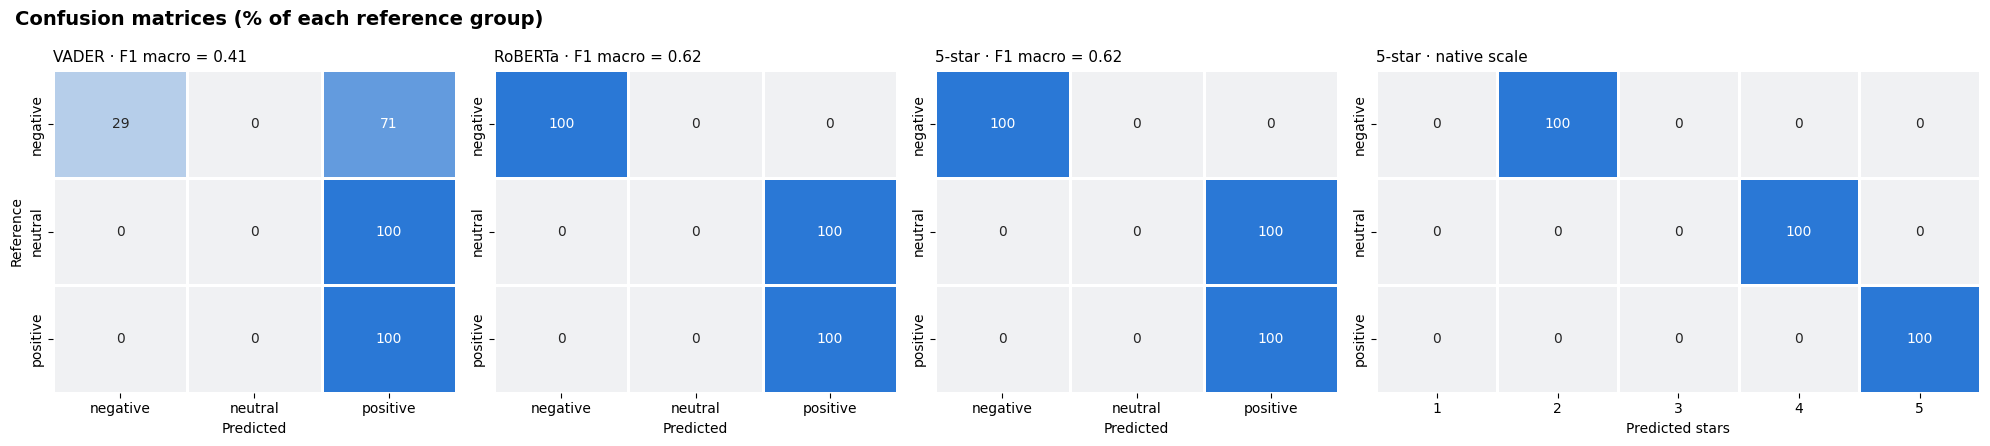

In [ ]:
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5), gridspec_kw={"width_ratios": [1, 1, 1, 1.5]})
cmap = sns.light_palette(BASE_COLOR, as_cmap=True)

# Panels 1-3: 3-class view (labels fixed so the 'neutral' column always appears)
for ax, (name, (label, _)) in zip(axes[:3], models.items()):
    cm = confusion_matrix(df["sentiment_reference"], df[label], labels=SENTIMENT_ORDER, normalize="true")
    sns.heatmap(cm * 100, annot=True, fmt=".0f", cmap=cmap, vmin=0, vmax=100, cbar=False,
                xticklabels=SENTIMENT_ORDER, yticklabels=SENTIMENT_ORDER,
                linewidths=2, linecolor="white", ax=ax)
    f1 = comparison.loc[name, "f1_macro"]
    ax.set_title(f"{name} · F1 macro = {f1:.2f}", loc="left", fontsize=11)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Reference" if ax is axes[0] else "")

# Panel 4: 5-star model on its native scale (reference vs stars 1-5)
cm5 = (pd.crosstab(df["sentiment_reference"], df["stars_label"], normalize="index")
         .reindex(index=SENTIMENT_ORDER, columns=[1, 2, 3, 4, 5], fill_value=0) * 100)
sns.heatmap(cm5, annot=True, fmt=".0f", cmap=cmap, vmin=0, vmax=100, cbar=False,
            linewidths=2, linecolor="white", ax=axes[3])
axes[3].set_title("5-star · native scale", loc="left", fontsize=11)
axes[3].set_xlabel("Predicted stars"); axes[3].set_ylabel("")

fig.suptitle("Confusion matrices (% of each reference group)", fontsize=14, x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
save_fig(fig, "06_confusion_matrices")
plt.show()

## 6.5 - Overall Satisfaction Level

Saved: 06_satisfaction_levels.png


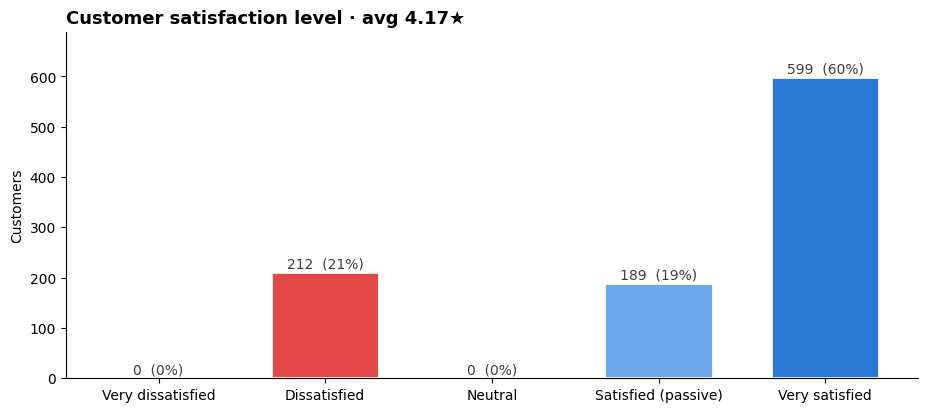

In [ ]:
# Final satisfaction level: 5-star model on its native scale
STAR_TO_LEVEL = {1: "Very dissatisfied", 2: "Dissatisfied", 3: "Neutral",
                 4: "Satisfied (passive)", 5: "Very satisfied"}
# Own names: LEVEL_ORDER / LEVEL_COLORS already hold low/medium/high from 3.3
SATISFACTION_ORDER = list(STAR_TO_LEVEL.values())

df["satisfaction_stars"] = df["stars_label"]                 # ordinal 1-5
df["satisfaction_score"] = df["stars_expected"].round(2)     # continuous 1-5
df["satisfaction_level"] = pd.Categorical(df["stars_label"].map(STAR_TO_LEVEL),
                                          categories=SATISFACTION_ORDER, ordered=True)

# Diverging colors: red (dissatisfied) <- gray (neutral) -> blue (satisfied)
SATISFACTION_COLORS = {"Very dissatisfied": "#b8322f", "Dissatisfied": "#e34948", "Neutral": "#8f8f8a",
                       "Satisfied (passive)": "#6da7ec", "Very satisfied": "#2a78d6"}

dist = df["satisfaction_level"].value_counts().reindex(SATISFACTION_ORDER)
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(dist.index, dist.values, color=[SATISFACTION_COLORS[l] for l in dist.index],
       edgecolor="white", linewidth=2, width=0.65)
for x, y in zip(dist.index, dist.values):
    ax.text(x, y + 8, f"{y}  ({y / len(df):.0%})", ha="center", fontsize=10, color=INK)
ax.set_ylim(0, dist.max() * 1.15); ax.set_ylabel("Customers")
ax.set_title(f"Customer satisfaction level · avg {df['satisfaction_stars'].mean():.2f}★",
             loc="left", fontsize=13, fontweight="bold")
sns.despine(); ax.grid(axis="x", visible=False)
save_fig(fig, "06_satisfaction_levels")
plt.show()

df.to_parquet(PROCESSED_DIR / "customers_satisfaction.parquet", index=False)

## 6.5 - Selected model: 5-star review classifier

`nlptown/bert-base-multilingual-uncased-sentiment` is selected to define the satisfaction level:

1. **Widest separation margin** at the critical satisfied/delighted boundary (23% of the scale vs 5.4% for RoBERTa and 2.5% for VADER).
2. **No threshold tuning**: its native output is used, so the validation stays clean.
3. **Business-ready scale**: 1–5 stars, directly interpretable by executives.
4. **Three distinct levels**: the only model that assigns each message template its own level (2★, 4★, 5★).

All three models rank messages perfectly (Spearman ρ = 0.88, the maximum possible given the ties in a 3-value reference).
The 3-class convention (3★ = neutral) would label template C as positive; the 5-level scale preserves the model's ordering
and reveals a **passive** segment (19%) — satisfied but not enthusiastic customers, the most exposed to competitors.

> Note: `LEVEL_ORDER` / `LEVEL_COLORS` already store the low/medium/high channel levels (3.3), so the satisfaction scale uses its own names (`SATISFACTION_ORDER`, `SATISFACTION_COLORS`).

# 7 - Main reason for satisfaction or dissatisfaction

Each message contains a **topic phrase** (extracted in 5.2) that carries the reason behind the customer's opinion. This module groups those phrases **without supervision**:

| Step | What it does |
|---|---|
| 7.1 | Converts each topic phrase into a vector (sentence embeddings) |
| 7.2 | Groups the vectors with hierarchical clustering; K chosen by silhouette |
| 7.3 | Names the clusters and compares them with the business taxonomy of 5.3 |
| 7.4 | Main reason behind each satisfaction level |

## 7.1 - Topic embeddings

An embedding converts a phrase into a numerical vector. Phrases with similar meanings are placed close together, even if they use different words (e.g. *"app crashes during payment"* and *"unreliable mobile app"*).

We use **all-MiniLM-L6-v2**, the most widely used sentence-embedding model: lightweight and fast.

In [ ]:
from sentence_transformers import SentenceTransformer

embedder = SentenceTransformer("all-MiniLM-L6-v2")

# Embed only the 30 unique topic phrases (one vector of 384 dimensions each)
topics = pd.Series(sorted(df["topic_phrase"].unique()), name="topic_phrase")
topic_embeddings = embedder.encode(topics.tolist(), normalize_embeddings=True)

print(f"Embedding matrix: {topic_embeddings.shape}")   # (30, 384)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Embedding matrix: (30, 384)


### Discarded approaches

| Approach | Why it was discarded |
|---|---|
| **Zero-shot classification** (`facebook/bart-large-mnli`) | It assigns predefined labels, which is not consistent with an unsupervised analysis. It was also unreliable on short phrases: adjectives dominated the topic (*"average service quality"*, *"average online experience"* and *"ordinary mortgage process"* → "General"), and several topics were misclassified (*"mobile deposit takes time"* → Fees, *"mobile app convenience"* → Rewards, *"mobile check deposits"* → Fraud). |
| **BERTopic** | Topic models need many distinct documents; with only 30 unique texts there is no material to discover topics from. |

The extracted topic phrases are clustered directly instead (7.2), and the manual taxonomy of 5.3 is used **only as a reference to evaluate** the clusters — never to build them.

## 7.2 - Clustering the topics

**Agglomerative (hierarchical) clustering** with cosine distance: it first joins the most similar topics and keeps merging them into larger groups. It fits this problem because:
- With 30 elements, the full **dendrogram** can be read and audited.
- **Cosine distance** is the standard for sentence embeddings.

K is chosen with the **silhouette score** (−1 to 1, higher = better-separated groups).

Best K by silhouette: 10 (0.243)
Saved: 07_topic_clustering.png


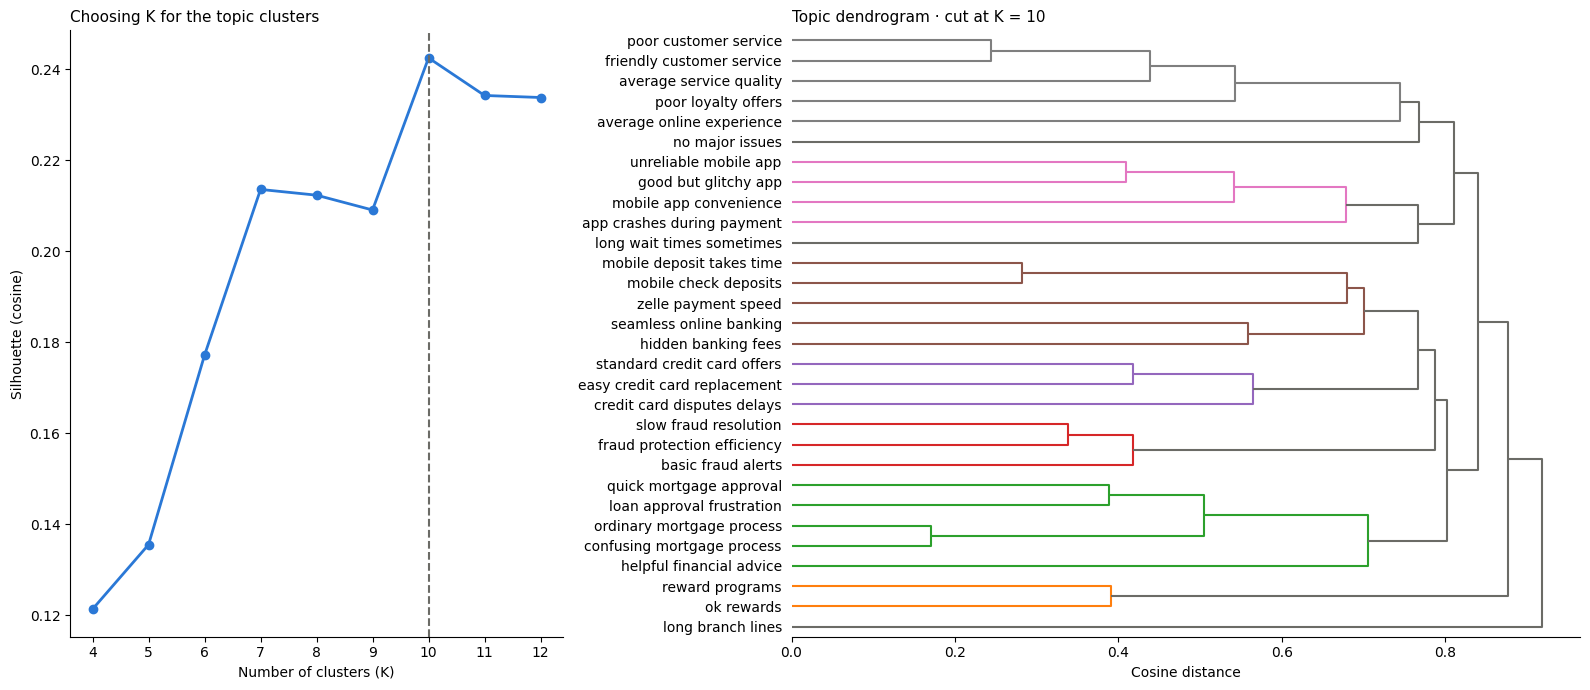

In [ ]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram

# Silhouette for each candidate K (cosine distance is the standard for sentence embeddings)
K_RANGE = range(4, 13)
topic_sil = {k: silhouette_score(topic_embeddings,
                                 AgglomerativeClustering(n_clusters=k, metric="cosine", linkage="average")
                                 .fit_predict(topic_embeddings), metric="cosine")
             for k in K_RANGE}
BEST_TOPIC_K = max(topic_sil, key=topic_sil.get)
print(f"Best K by silhouette: {BEST_TOPIC_K} ({topic_sil[BEST_TOPIC_K]:.3f})")

fig, axes = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw={"width_ratios": [1, 1.6]})

# Left: silhouette by K
axes[0].plot(list(topic_sil), list(topic_sil.values()), marker="o", color=BASE_COLOR, lw=2)
axes[0].axvline(BEST_TOPIC_K, color=INK_MUTED, ls="--")
axes[0].set_xlabel("Number of clusters (K)"); axes[0].set_ylabel("Silhouette (cosine)")
axes[0].set_title("Choosing K for the topic clusters", loc="left", fontsize=11)
sns.despine(ax=axes[0])

# Right: dendrogram of the 30 topics
Z = linkage(topic_embeddings, method="average", metric="cosine")
dendrogram(Z, labels=topics.tolist(), orientation="right", ax=axes[1],
           color_threshold=Z[-(BEST_TOPIC_K - 1), 2], above_threshold_color=INK_MUTED)
axes[1].set_title(f"Topic dendrogram · cut at K = {BEST_TOPIC_K}", loc="left", fontsize=11)
axes[1].set_xlabel("Cosine distance")
sns.despine(ax=axes[1], left=True)
plt.tight_layout()
save_fig(fig, "07_topic_clustering")
plt.show()

# Final topic clusters, mapped back to every customer
topic_clusters = pd.Series(
    AgglomerativeClustering(n_clusters=BEST_TOPIC_K, metric="cosine", linkage="average")
    .fit_predict(topic_embeddings), index=topics.values, name="topic_cluster")
df["topic_cluster"] = df["topic_phrase"].map(topic_clusters)

## 7.3 - Naming the clusters and validating them

Each cluster is named after the business category most represented inside it. Two metrics compare the data-driven grouping with the taxonomy of 5.3:
- **Adjusted Rand Index (ARI):** 1 = identical grouping, 0 = no better than random.
- **Weighted purity:** share of topics that sit in a cluster dominated by their own category.

**Decision.** The final `main_reason` variable uses the business category of each extracted topic. The clustering shows that this grouping is supported by the semantic structure of the phrases, while the named categories stay stable and readable for the executive report. Clusters that mix two categories (if any) are reported as a limitation, not hidden.

In [ ]:
# Name each unsupervised cluster after the business category most represented inside it
topic_view = (pd.DataFrame({"topic_phrase": topic_clusters.index, "topic_cluster": topic_clusters.values})
                .assign(reason_category=lambda x: x["topic_phrase"].map(TOPIC_TO_CATEGORY)))

cluster_names = (topic_view.groupby("topic_cluster")["reason_category"]
                   .agg(lambda s: s.value_counts().index[0]))
purity = (topic_view.groupby("topic_cluster")["reason_category"]
            .agg(lambda s: s.value_counts(normalize=True).iloc[0]))

cluster_summary = pd.DataFrame({
    "suggested_name": cluster_names,
    "purity": purity.round(2),                       # share of topics matching the suggested name
    "n_topics": topic_view.groupby("topic_cluster").size(),
    "topics": topic_view.groupby("topic_cluster")["topic_phrase"].apply(", ".join),
})
display(cluster_summary)

# Agreement between the data-driven clusters and the business taxonomy (topic level, 30 rows)
ari_topics = adjusted_rand_score(topic_view["reason_category"], topic_view["topic_cluster"])
weighted_purity = (purity * topic_view.groupby("topic_cluster").size()).sum() / len(topic_view)
print(f"Adjusted Rand Index vs taxonomy: {ari_topics:.2f} (1 = identical grouping, 0 = random)")
print(f"Weighted purity: {weighted_purity:.0%} of topics fall in a cluster dominated by their own category")

# Final variable: main reason = business category of the extracted topic
df["main_reason"] = df["reason_category"]

,suggested_name,purity,n_topics,topics
topic_cluster,,,,
0,Customer service,0.60,5,"average online experience, average service quality, friendly customer service, poor customer service, poor loyalty o..."
1,Digital & mobile,0.80,5,"hidden banking fees, mobile check deposits, mobile deposit takes time, seamless online banking, zelle payment speed"
2,Mortgages & loans,0.80,5,"confusing mortgage process, helpful financial advice, loan approval frustration, ordinary mortgage process, quick mo..."
3,General,1.00,1,no major issues
4,Digital & mobile,1.00,4,"app crashes during payment, good but glitchy app, mobile app convenience, unreliable mobile app"
5,Rewards & loyalty,1.00,2,"ok rewards, reward programs"
6,Fraud & security,1.00,3,"basic fraud alerts, fraud protection efficiency, slow fraud resolution"
7,Branches & wait times,1.00,1,long branch lines
8,Branches & wait times,1.00,1,long wait times sometimes


Adjusted Rand Index vs taxonomy: 0.50 (1 = identical grouping, 0 = random)
Weighted purity: 87% of topics fall in a cluster dominated by their own category


## 7.4 - Main reason behind each satisfaction level

Three questions, one per level:
- What **delights** the 5★ customers? → strengths to protect.
- What holds back the 4★ **passive** customers? → opportunity to turn them into promoters.
- What **annoys** the 2★ customers? → churn risks to fix.

satisfaction_level,Dissatisfied,Satisfied (passive),Very satisfied
main_reason,,,
Branches & wait times,9.90,10.60,0.00
Credit cards,9.00,12.70,9.00
Customer service,8.50,9.00,20.20
Digital & mobile,24.50,33.30,39.60
Fees,9.40,0.00,0.00
Fraud & security,10.80,7.90,11.40
General,0.00,7.40,0.00
Mortgages & loans,17.00,11.10,10.20
Rewards & loyalty,10.80,7.90,9.70


,satisfaction_level,topic_phrase,customers
0,Dissatisfied,app crashes during payment,26
1,Dissatisfied,unreliable mobile app,26
2,Dissatisfied,poor loyalty offers,23
3,Satisfied (passive),good but glitchy app,24
4,Satisfied (passive),standard credit card offers,24
5,Satisfied (passive),ordinary mortgage process,21
6,Very satisfied,fraud protection efficiency,68
7,Very satisfied,helpful financial advice,63
8,Very satisfied,quick mortgage approval,61


Saved: 07_reasons_by_level.png


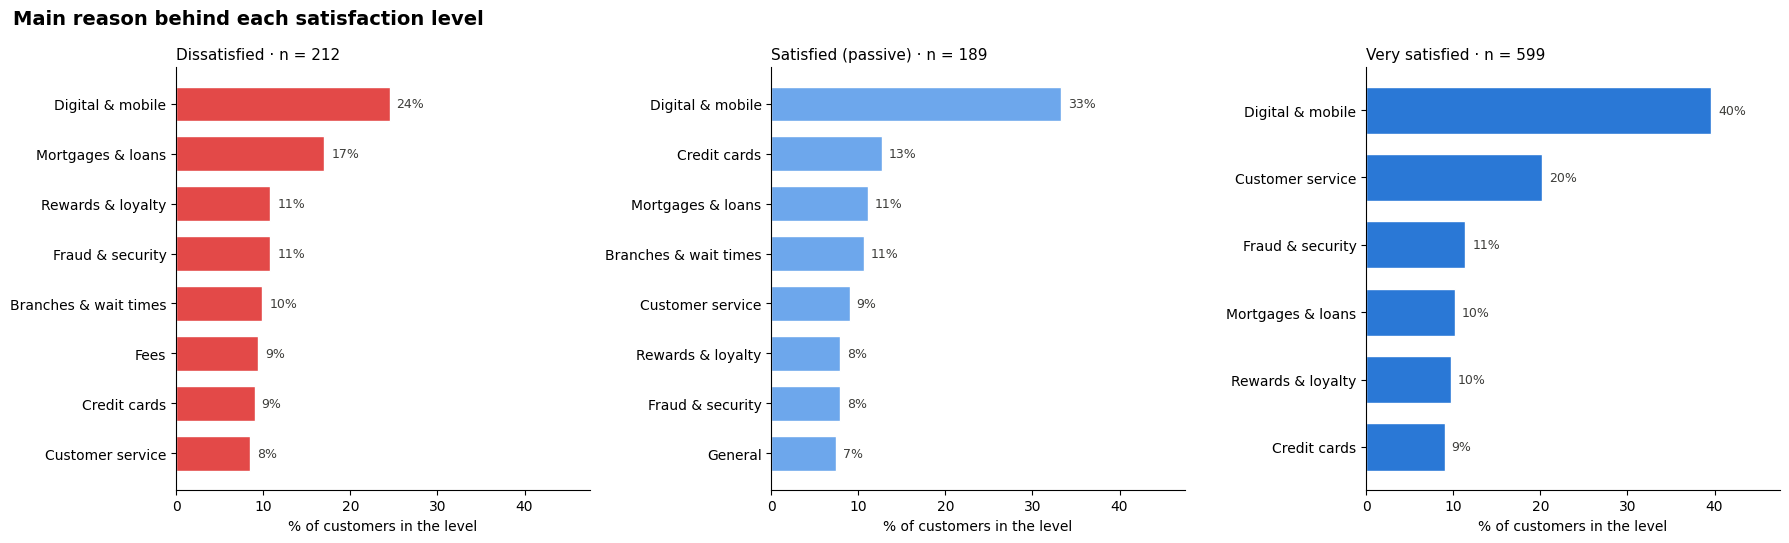

In [ ]:
# Share of each reason within each satisfaction level (only levels that actually occur)
PRESENT_LEVELS = [l for l in SATISFACTION_ORDER if (df["satisfaction_level"] == l).any()]
reason_by_level = (pd.crosstab(df["main_reason"], df["satisfaction_level"], normalize="columns")
                     .reindex(columns=PRESENT_LEVELS) * 100).round(1)
display(reason_by_level)

# Most frequent specific topics per level
top_topics = (df.groupby("satisfaction_level", observed=True)["topic_phrase"]
                .value_counts().groupby(level=0).head(3).rename("customers").reset_index())
display(top_topics)

fig, axes = plt.subplots(1, len(PRESENT_LEVELS), figsize=(18, 5.5), sharex=True)
for ax, level in zip(axes, PRESENT_LEVELS):
    s = reason_by_level[level].sort_values()
    s = s[s > 0]
    ax.barh(s.index, s.values, color=SATISFACTION_COLORS[level], edgecolor="white", height=0.7)
    for i, v in enumerate(s.values):
        ax.text(v + 0.8, i, f"{v:.0f}%", va="center", fontsize=9, color=INK)
    n = int((df["satisfaction_level"] == level).sum())
    ax.set_title(f"{level} · n = {n}", loc="left", fontsize=11)
    ax.set_xlabel("% of customers in the level")
    sns.despine(ax=ax); ax.grid(axis="y", visible=False)
axes[0].set_xlim(0, reason_by_level.values.max() * 1.2)
fig.suptitle("Main reason behind each satisfaction level", fontsize=14, x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
save_fig(fig, "07_reasons_by_level")
plt.show()

df.to_parquet(PROCESSED_DIR / "customers_satisfaction.parquet", index=False)

### Findings — main reason

| Level | Top reasons | Reading |
|---|---|---|
| **Dissatisfied (212)** | Digital & mobile 24% (*unreliable mobile app*, *app crashes during payment*), Mortgages & loans 17%, Rewards 11%, Fraud 11% | The app is the #1 pain point; mortgage/loan processes are second |
| **Passive (189)** | Digital & mobile 33% (*good but glitchy app*), Credit cards 13% (*standard offers*), Mortgages 11% (*ordinary process*) | "Fine but nothing special": average app, generic card offers, ordinary mortgage process |
| **Very satisfied (599)** | Digital & mobile 40%, Customer service 20% (*helpful financial advice*), Fraud 11% (*fraud protection efficiency*) | Digital convenience and human advice drive delight |

**Key insight.** *Digital & mobile* is the top reason at **every** level: the app is simultaneously the biggest source of delight and of frustration. Its reliability (crashes during payment) decides on which side a customer lands. **Fees** and **branch lines** appear only among dissatisfied and passive customers: they never generate delight, they only cause friction.

# 8 - Characterization of satisfaction by other variables

Does satisfaction (1–5 stars) vary with the customer's bank, channels, products or financial profile?
- Categorical variables: chi-square test + Cramér's V.
- Numeric variables: Kruskal-Wallis test + ε².

Since 3.4 showed that the three banks serve the same type of customer, any gap between banks would point to **service quality**.

,test,p_value,effect_size,significant
variable,,,,
client_age,Kruskal-Wallis,0.12,0.00,no
credit_card,Chi-square,0.31,0.05,no
customer_debt,Kruskal-Wallis,0.34,0.00,no
bank_account,Chi-square,0.46,0.04,no
use_of_digital_channels,Chi-square,0.49,0.04,no
debt_to_income,Kruskal-Wallis,0.50,0.00,no
tenure_years,Kruskal-Wallis,0.53,0.00,no
customer_income,Kruskal-Wallis,0.54,0.00,no
total_number_of_products,Kruskal-Wallis,0.71,0.00,no


Saved: 08_satisfaction_by_variables.png


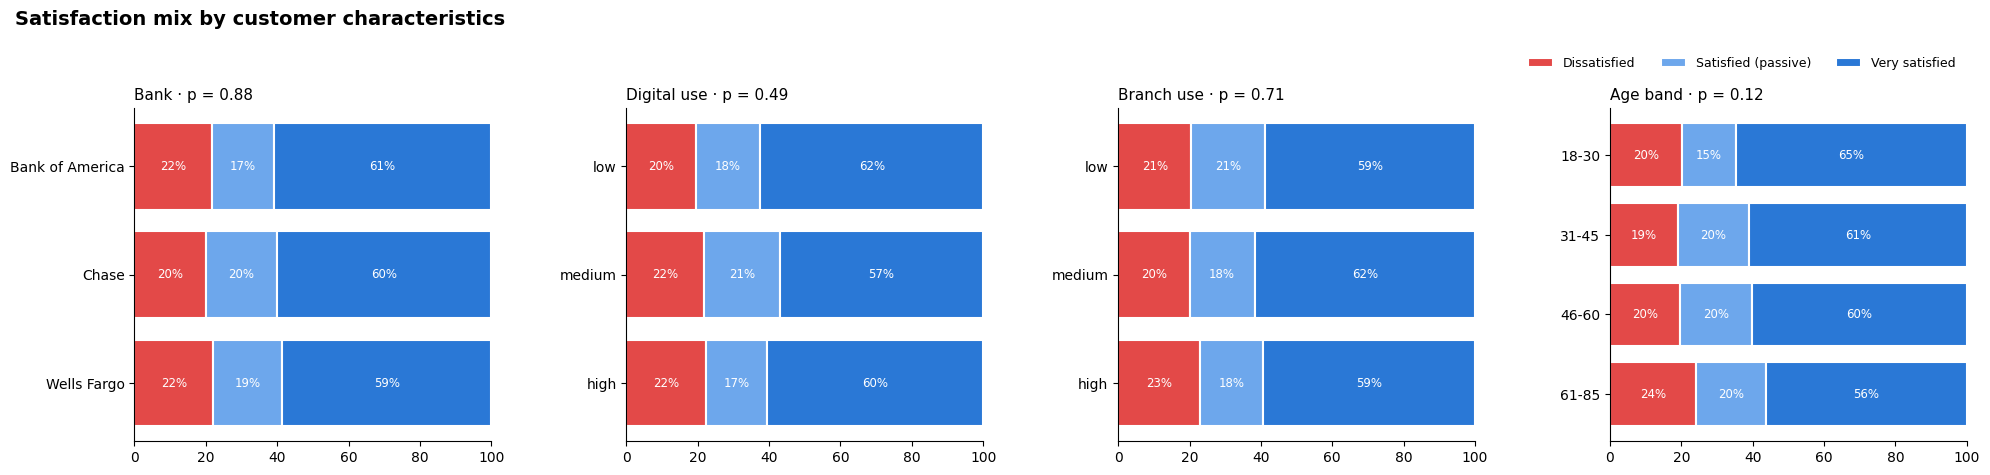

,customers,avg_stars,pct_very_satisfied,pct_passive,pct_dissatisfied
bank,,,,,
Chase,394,4.20,60.15,19.80,20.05
Bank of America,302,4.17,60.93,17.22,21.85
Wells Fargo,304,4.14,58.55,19.41,22.04


bank,Chase,Bank of America,Wells Fargo
main_reason,,,
Branches & wait times,8.90,13.60,7.50
Credit cards,8.90,3.00,14.90
Customer service,8.90,4.50,11.90
Digital & mobile,26.60,25.80,20.90
Fees,6.30,15.20,7.50
Fraud & security,11.40,9.10,11.90
Mortgages & loans,17.70,21.20,11.90
Rewards & loyalty,11.40,7.60,13.40


In [ ]:
from scipy.stats import kruskal, chi2_contingency

# Does satisfaction (1-5 stars) vary with any customer attribute?
CHAR_CAT = ["bank", "city", "use_of_digital_channels", "use_of_branches",
            "bank_account", "credit_card", "mortgage"]
CHAR_NUM = ["client_age", "tenure_years", "customer_income", "customer_debt",
            "debt_to_income", "total_number_of_products"]

rows = []
for c in CHAR_CAT:
    ct = pd.crosstab(df[c], df["satisfaction_stars"])
    rows.append({"variable": c, "test": "Chi-square", "p_value": chi2_contingency(ct)[1],
                 "effect_size": cramers_v(ct)})
for c in CHAR_NUM:
    h, p = kruskal(*[g[c] for _, g in df.groupby("satisfaction_stars")])
    rows.append({"variable": c, "test": "Kruskal-Wallis", "p_value": p,
                 "effect_size": epsilon_squared(h, len(df))})
satisfaction_drivers = pd.DataFrame(rows).set_index("variable").sort_values("p_value")
satisfaction_drivers["significant"] = np.where(satisfaction_drivers["p_value"] < 0.05, "yes", "no")
display(satisfaction_drivers.round(3))

# Visual: satisfaction mix across the main business dimensions (100% stacked bars)
age_band = pd.cut(df["client_age"], bins=AGE_BINS, labels=AGE_LABELS)
dims = {"Bank": df["bank"], "Digital use": df["use_of_digital_channels"],
        "Branch use": df["use_of_branches"], "Age band": age_band}
fig, axes = plt.subplots(1, 4, figsize=(20, 4.8), sharey=False)
for ax, (title, col) in zip(axes, dims.items()):
    mix = pd.crosstab(col, df["satisfaction_level"], normalize="index").reindex(columns=PRESENT_LEVELS) * 100
    if title in ("Digital use", "Branch use"):
        mix = mix.reindex(["low", "medium", "high"])
    left = np.zeros(len(mix))
    for level in PRESENT_LEVELS:
        ax.barh(mix.index.astype(str), mix[level], left=left, color=SATISFACTION_COLORS[level],
                edgecolor="white", linewidth=1.5, label=level)
        for i, (l, v) in enumerate(zip(left, mix[level])):
            ax.text(l + v / 2, i, f"{v:.0f}%", ha="center", va="center", fontsize=8.5, color="white")
        left += mix[level].values
    p = satisfaction_drivers.loc[{"Bank": "bank", "Digital use": "use_of_digital_channels",
                                  "Branch use": "use_of_branches", "Age band": "client_age"}[title], "p_value"]
    ax.set_title(f"{title} · p = {p:.2f}", loc="left", fontsize=11)
    ax.set_xlim(0, 100); ax.invert_yaxis(); sns.despine(ax=ax); ax.grid(False)
axes[-1].legend(frameon=False, loc="lower right", bbox_to_anchor=(1, 1.08), ncol=3, fontsize=9)
fig.suptitle("Satisfaction mix by customer characteristics", fontsize=14, x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
save_fig(fig, "08_satisfaction_by_variables")
plt.show()

# Satisfaction KPIs per bank (percentages — Chase is larger only by footprint)
bank_kpis = df.groupby("bank").agg(
    customers=("client_id", "size"),
    avg_stars=("satisfaction_stars", "mean"),
    pct_very_satisfied=("satisfaction_stars", lambda s: (s == 5).mean() * 100),
    pct_passive=("satisfaction_stars", lambda s: (s == 4).mean() * 100),
    pct_dissatisfied=("satisfaction_stars", lambda s: (s <= 2).mean() * 100),
).reindex(BANK_ORDER).round(2)
display(bank_kpis)

# Complaint mix per bank: what drives dissatisfaction at each bank?
complaints_by_bank = (pd.crosstab(df.loc[df["satisfaction_stars"] <= 2, "main_reason"],
                                  df.loc[df["satisfaction_stars"] <= 2, "bank"], normalize="columns")
                        .reindex(columns=BANK_ORDER) * 100).round(1)
display(complaints_by_bank)

### Findings — characterization

- **No customer attribute is associated with satisfaction** (all p > 0.10; every effect size ≤ 0.08). Age, income, debt, tenure, products and channel use do not predict how satisfied a customer is.
- **The three banks perform the same**: average 4.14–4.20★, 59–61% very satisfied and 20–22% dissatisfied (p = 0.88).
- **What differs is the complaint mix** (descriptive, small groups of 66–79 dissatisfied customers per bank): Bank of America concentrates *Fees* (15%) and *Mortgages & loans* (21%); Wells Fargo stands out in *Credit cards* (15%); Chase follows the overall pattern led by *Digital & mobile* (27%).

**Implication.** Satisfaction is driven by **service experiences** (app reliability, processes, fees), not by who the customer is. Improvement plans should target touchpoints, not demographic groups.

# 9 - Customer segmentation: variable selection and preparation

**Goal:** homogeneous groups of customers to send them a financial-product offer that matches their needs. Variables are therefore chosen for what they say about **needs** (life stage, financial capacity, products held, channel behaviour):

| Dimension | Selected variables | Why |
|---|---|---|
| Life stage | `client_age`, `tenure_years` | Needs change with age and relationship length (ρ = 0.43: related but distinct) |
| Financial capacity | `customer_income`, `log_debt_to_income` | Ability to take new products and credit risk (log removes the skew, 4.3) |
| Products held | `bank_account_bin`, `credit_card_bin`, `mortgage_bin`, `extra_products` | Gaps in the portfolio = cross-sell opportunities |
| Channel behaviour | `digital_use_ord`, `branch_use_ord` | How to deliver the offer |

**Preparation:** all variables are standardized (z-scores) so that dollars, years and 0/1 flags weigh the same in the distance computation.

In [ ]:
from sklearn.preprocessing import StandardScaler

# Selected features: describe the customer's financial needs and channel behaviour
CLUSTER_NUM = ["client_age", "tenure_years", "customer_income", "log_debt_to_income",
               "extra_products", "digital_use_ord", "branch_use_ord"]
CLUSTER_BIN = ["bank_account_bin", "credit_card_bin", "mortgage_bin"]
CLUSTER_FEATURES = CLUSTER_NUM + CLUSTER_BIN

# Excluded on purpose (documented in the markdown above)
EXCLUDED = {
    "bank / city / branch":          "Fully redundant (V = 1.00) and do not differentiate customers (3.4)",
    "customer_debt, debt_to_income":  "Represented by log_debt_to_income (avoids double counting, reduces skew)",
    "total_number_of_products":      "Equals core flags + extra_products",
    "onboarding_age":                "Linear combination of age and tenure",
    "satisfaction / reasons":        "Outcome variables: used to profile segments, never to build them",
    "flags and diagnostics":         "Data-quality markers, not customer traits",
}
display(pd.Series(EXCLUDED, name="reason for exclusion").to_frame())

# Redundancy check among the selected features
display(df[CLUSTER_FEATURES].corr(method="spearman").round(2))

# Preparation: z-score scaling so dollars and 0/1 flags weigh the same in the distance
scaler = StandardScaler()
X_cluster = scaler.fit_transform(df[CLUSTER_FEATURES].astype(float))
print(f"Model matrix: {X_cluster.shape} | mean ≈ {X_cluster.mean():.2f}, std ≈ {X_cluster.std():.2f}")

,reason for exclusion
bank / city / branch,Fully redundant (V = 1.00) and do not differentiate customers (3.4)
"customer_debt, debt_to_income","Represented by log_debt_to_income (avoids double counting, reduces skew)"
total_number_of_products,Equals core flags + extra_products
onboarding_age,Linear combination of age and tenure
satisfaction / reasons,"Outcome variables: used to profile segments, never to build them"
flags and diagnostics,"Data-quality markers, not customer traits"


,client_age,tenure_years,customer_income,log_debt_to_income,extra_products,digital_use_ord,branch_use_ord,bank_account_bin,credit_card_bin,mortgage_bin
client_age,1.00,0.43,0.00,-0.00,0.03,0.01,0.03,-0.03,-0.01,-0.05
tenure_years,0.43,1.00,0.02,-0.01,-0.01,-0.00,-0.01,-0.03,-0.03,-0.02
customer_income,0.00,0.02,1.00,-0.63,-0.04,-0.01,-0.04,0.01,0.01,-0.01
log_debt_to_income,-0.00,-0.01,-0.63,1.00,0.08,0.03,0.04,-0.05,0.01,0.02
extra_products,0.03,-0.01,-0.04,0.08,1.00,-0.00,0.08,-0.02,-0.03,-0.02
digital_use_ord,0.01,-0.00,-0.01,0.03,-0.00,1.00,-0.02,-0.02,0.00,-0.08
branch_use_ord,0.03,-0.01,-0.04,0.04,0.08,-0.02,1.00,-0.04,0.04,-0.05
bank_account_bin,-0.03,-0.03,0.01,-0.05,-0.02,-0.02,-0.04,1.00,-0.01,-0.00
credit_card_bin,-0.01,-0.03,0.01,0.01,-0.03,0.00,0.04,-0.01,1.00,0.01
mortgage_bin,-0.05,-0.02,-0.01,0.02,-0.02,-0.08,-0.05,-0.00,0.01,1.00


Model matrix: (1000, 10) | mean ≈ 0.00, std ≈ 1.00


# 10 - Models analyzed

Three clustering families, each with a different idea of what a "group" is:

| Model | Logic | Parameters explored |
|---|---|---|
| **K-Means** | Partitions customers around K centroids, minimizing the distance to them | K = 2–8 (elbow, metrics, bootstrap stability) |
| **Hierarchical clustering** | Merges customers step by step into a tree (dendrogram); the tree is cut at K groups | Linkage = Ward, average, complete · K = 2–8 |
| **DBSCAN** | Groups customers that sit in dense regions; isolated customers are labelled noise. K is not chosen, it emerges from the density | `min_samples` = 2 × features = 20 · `eps` = 1.6–3.0 around the k-distance curve |

Evaluation: **silhouette** (separation ↑), **Calinski-Harabasz** (between/within variance ↑), **Davies-Bouldin** (overlap ↓), smallest cluster size and, for K-Means, **bootstrap stability** (ARI between the full-data solution and 20 resampled fits). For DBSCAN we also track the share of noise and the size of the largest cluster.

model,Hierarchical (average),Hierarchical (complete),Hierarchical (ward),K-Means
k,,,,
2,0.12,0.11,0.11,0.12
3,0.06,0.07,0.08,0.10
4,0.06,0.05,0.09,0.10
5,0.08,0.05,0.09,0.10
6,0.07,0.04,0.09,0.11
7,0.08,0.04,0.09,0.11
8,0.07,0.04,0.10,0.12


k-distance percentiles (min_samples = 20): p10 = 2.18, p50 = 2.50, p90 = 2.84


,eps,n_clusters,noise_pct,largest_cluster_pct,silhouette
0,1.60,0,100.00,0.00,NaN
1,1.70,0,100.00,0.00,NaN
2,1.80,1,97.90,2.10,NaN
3,1.90,2,93.20,4.80,0.43
4,2.00,2,85.30,7.70,0.38
5,2.10,4,66.10,17.70,0.17
6,2.20,2,51.30,46.80,0.06
7,2.30,2,25.40,72.90,0.09
8,2.40,1,8.80,91.20,NaN
9,2.50,1,2.80,97.20,NaN


,K-Means stability (ARI)
2,0.86
3,0.70
4,0.50
5,0.42
6,0.38
7,0.43
8,0.43


Saved: 10_model_comparison.png


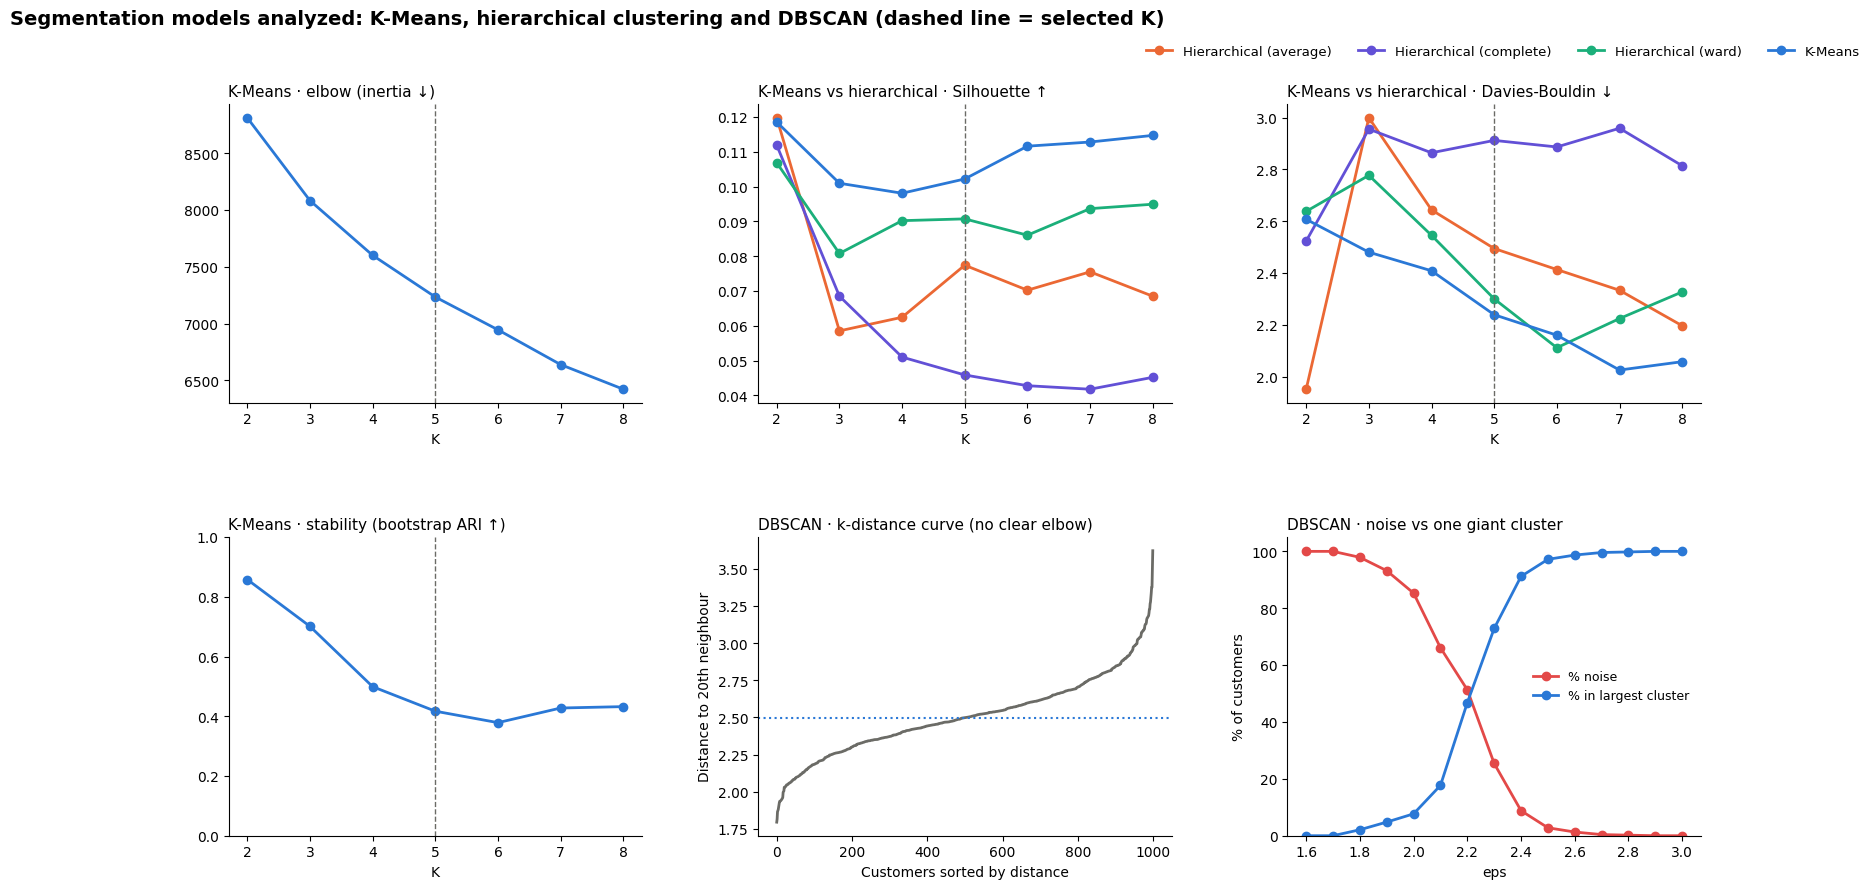

Saved: 10_dendrogram_ward.png


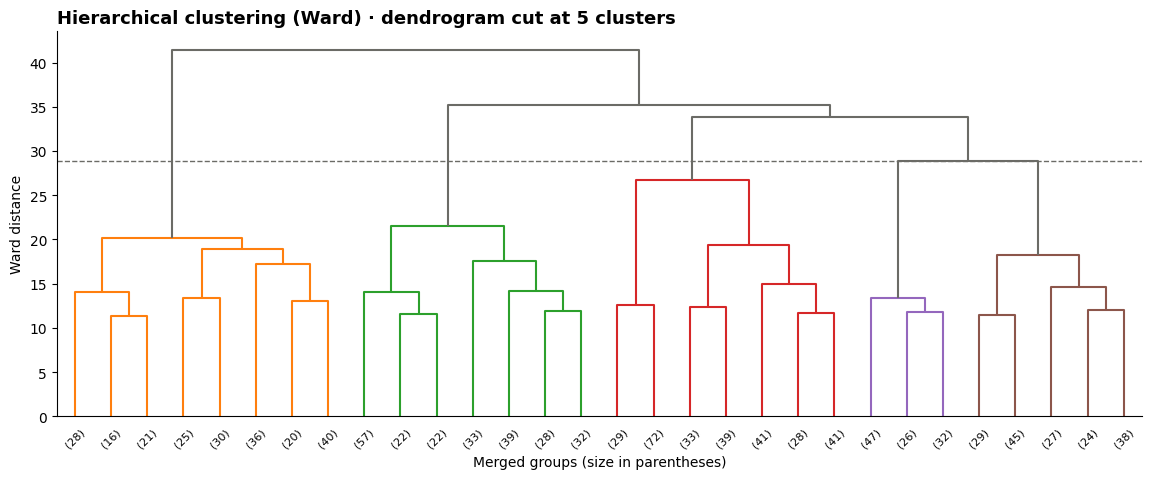

In [ ]:
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score
from scipy.cluster.hierarchy import linkage, dendrogram

K_SEG = range(2, 9)

def scores(labels: np.ndarray) -> dict:
    """Internal validation metrics for one partition (noise points excluded)."""
    m = labels != -1
    return {"silhouette": silhouette_score(X_cluster[m], labels[m]),
            "calinski_harabasz": calinski_harabasz_score(X_cluster[m], labels[m]),
            "davies_bouldin": davies_bouldin_score(X_cluster[m], labels[m]),
            "smallest_cluster_pct": np.bincount(labels[m]).min() / len(labels) * 100}

# ---------- 10.1 K-Means: elbow + metrics for K = 2..8 ----------
rows, inertia = [], {}
for k in K_SEG:
    km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(X_cluster)
    inertia[k] = km.inertia_
    rows.append({"model": "K-Means", "k": k, **scores(km.labels_)})

# ---------- 10.2 Hierarchical clustering: three linkage criteria ----------
LINKAGES = ["ward", "average", "complete"]
for link in LINKAGES:
    for k in K_SEG:
        lab = AgglomerativeClustering(n_clusters=k, linkage=link).fit_predict(X_cluster)
        rows.append({"model": f"Hierarchical ({link})", "k": k, **scores(lab)})
model_results = pd.DataFrame(rows)
display(model_results.round(3).pivot(index="k", columns="model", values="silhouette"))

# ---------- 10.3 DBSCAN: eps from the k-distance curve, then a grid around it ----------
MIN_SAMPLES = 2 * len(CLUSTER_FEATURES)          # common rule of thumb: 2 x number of features
k_dist = np.sort(NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X_cluster)
                 .kneighbors(X_cluster)[0][:, -1])
print(f"k-distance percentiles (min_samples = {MIN_SAMPLES}): "
      f"p10 = {np.percentile(k_dist, 10):.2f}, p50 = {np.percentile(k_dist, 50):.2f}, "
      f"p90 = {np.percentile(k_dist, 90):.2f}")

dbscan_rows = []
for eps in np.round(np.arange(1.6, 3.01, 0.1), 2):
    lab = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit_predict(X_cluster)
    n_clusters = len(set(lab)) - (-1 in lab)
    dbscan_rows.append({"eps": eps, "n_clusters": n_clusters,
                        "noise_pct": (lab == -1).mean() * 100,
                        "largest_cluster_pct": (np.bincount(lab[lab >= 0]).max() / len(lab) * 100) if n_clusters else 0,
                        "silhouette": scores(lab)["silhouette"] if n_clusters > 1 else np.nan})
dbscan_results = pd.DataFrame(dbscan_rows)
display(dbscan_results.round(2))

# ---------- 10.4 Stability of K-Means (bootstrap ARI) ----------
rng = np.random.default_rng(SEED)
def kmeans_stability(k: int, n_boot: int = 20) -> float:
    base = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(X_cluster)
    out = []
    for b in range(n_boot):
        idx = rng.choice(len(X_cluster), len(X_cluster), replace=True)
        boot = KMeans(n_clusters=k, n_init=10, random_state=b).fit(X_cluster[idx])
        out.append(adjusted_rand_score(base.labels_, boot.predict(X_cluster)))
    return float(np.mean(out))
stability = pd.Series({k: kmeans_stability(k) for k in K_SEG}, name="K-Means stability (ARI)")
display(stability.round(2).to_frame())

# ---------- Figure 1: model comparison ----------
MODEL_COLORS = {"K-Means": "#2a78d6", "Hierarchical (ward)": "#1baf7a",
                "Hierarchical (average)": "#eb6834", "Hierarchical (complete)": "#6250d6"}
fig, axes = plt.subplots(2, 3, figsize=(19, 9.5))
plt.subplots_adjust(hspace=0.45, wspace=0.28)

ax = axes[0, 0]
ax.plot(list(inertia), list(inertia.values()), marker="o", lw=2, color=MODEL_COLORS["K-Means"])
ax.set_title("K-Means · elbow (inertia ↓)", loc="left", fontsize=11); ax.set_xlabel("K")

for ax, (metric, title) in zip([axes[0, 1], axes[0, 2]],
                               [("silhouette", "Silhouette ↑"), ("davies_bouldin", "Davies-Bouldin ↓")]):
    for name, g in model_results.groupby("model"):
        ax.plot(g["k"], g[metric], marker="o", lw=2, color=MODEL_COLORS[name], label=name)
    ax.set_title(f"K-Means vs hierarchical · {title}", loc="left", fontsize=11); ax.set_xlabel("K")
handles, labels = axes[0, 1].get_legend_handles_labels()
fig.legend(handles, labels, frameon=False, ncol=4, fontsize=9.5, loc="upper right", bbox_to_anchor=(0.99, 0.955))

ax = axes[1, 0]
ax.plot(stability.index, stability.values, marker="o", lw=2, color=MODEL_COLORS["K-Means"])
ax.set_ylim(0, 1); ax.set_xlabel("K")
ax.set_title("K-Means · stability (bootstrap ARI ↑)", loc="left", fontsize=11)

ax = axes[1, 1]
ax.plot(np.arange(len(k_dist)), k_dist, color=INK_MUTED, lw=2)
ax.axhline(np.percentile(k_dist, 50), color=BASE_COLOR, ls=":", lw=1.5)
ax.set_xlabel("Customers sorted by distance"); ax.set_ylabel(f"Distance to {MIN_SAMPLES}th neighbour")
ax.set_title("DBSCAN · k-distance curve (no clear elbow)", loc="left", fontsize=11)

ax = axes[1, 2]
ax.plot(dbscan_results["eps"], dbscan_results["noise_pct"], marker="o", lw=2, color="#e34948", label="% noise")
ax.plot(dbscan_results["eps"], dbscan_results["largest_cluster_pct"], marker="o", lw=2,
        color=BASE_COLOR, label="% in largest cluster")
ax.set_xlabel("eps"); ax.set_ylabel("% of customers"); ax.set_ylim(0, 105)
ax.set_title("DBSCAN · noise vs one giant cluster", loc="left", fontsize=11)
ax.legend(frameon=False, fontsize=9)

for a in axes.flat:
    sns.despine(ax=a)
for a in [axes[0, 0], axes[0, 1], axes[0, 2], axes[1, 0]]:
    a.axvline(5, color=INK_MUTED, ls="--", lw=1)
fig.suptitle("Segmentation models analyzed: K-Means, hierarchical clustering and DBSCAN "
             "(dashed line = selected K)", fontsize=14, x=0.01, ha="left", fontweight="bold")
save_fig(fig, "10_model_comparison")
plt.show()

# ---------- Figure 2: dendrogram (Ward), truncated to the last 30 merges ----------
Z_ward = linkage(X_cluster, method="ward")
fig, ax = plt.subplots(figsize=(14, 5))
dendrogram(Z_ward, truncate_mode="lastp", p=30, ax=ax, color_threshold=Z_ward[-4, 2],
           above_threshold_color=INK_MUTED, leaf_font_size=8)
ax.axhline(Z_ward[-4, 2], color=INK_MUTED, ls="--", lw=1)
ax.set_ylabel("Ward distance"); ax.set_xlabel("Merged groups (size in parentheses)")
ax.set_title("Hierarchical clustering (Ward) · dendrogram cut at 5 clusters", loc="left",
             fontsize=13, fontweight="bold")
sns.despine()
save_fig(fig, "10_dendrogram_ward")
plt.show()

model_results.to_csv(REPORTS_DIR / "segmentation_model_comparison.csv", index=False)
dbscan_results.to_csv(REPORTS_DIR / "dbscan_grid.csv", index=False)

### Reading the comparison

- **All silhouettes are low (0.04–0.12).** This was anticipated in the EDA: the variables are uniform and independent, so the data has no strong natural clusters. The segments are a **useful partition** of the customer base, not naturally separated groups.
- **DBSCAN finds no density structure.** The k-distance curve rises smoothly with no elbow (median distance 2.5). Small `eps` values label almost everyone as noise (85–100% for eps ≤ 2.0); from eps = 2.4 one cluster absorbs over 90% of customers. No `eps` produces several meaningful groups, and DBSCAN cannot assign new customers (no `predict`). It is discarded for segmentation — but it is the strongest evidence that customers are spread evenly, without dense pockets.
- **Hierarchical clustering:** Ward is clearly the best linkage (silhouette ≈ 0.09 for K ≥ 4); average and complete linkage create unbalanced or overlapping groups. Its dendrogram shows no dominant cut either.
- **K-Means has the best silhouette for every K ≥ 3** and the best Calinski-Harabasz, with Davies-Bouldin similar to Ward.
- **K = 2** has the best metrics and stability, but two groups do not support differentiated offers. **K = 5** is a local silhouette peak (0.102 vs 0.098 at K = 4), the elbow curve starts to flatten, every segment holds ≥ 14% of customers and each one maps to a distinct offer. Its stability (ARI ≈ 0.42) is moderate and is reported as a limitation.

# 11 - Selected model: K-Means with K = 5

**Justification**
1. Best silhouette and Calinski-Harabasz of the three families for K ≥ 3; DBSCAN cannot produce a usable segmentation on this data.
2. K = 5 balances statistical quality with business use: five segments, each with a clear and different need.
3. Centroids are directly interpretable (average customer of each segment) and new customers are assigned with `predict` — required for the saved model (Module 12). Hierarchical clustering and DBSCAN have no native way to score new customers.
4. Robust to outliers: refitting without the 30 multivariate outliers flagged in 2.8 gives almost the same segments (ARI ≈ 0.97).
5. Hierarchical Ward with K = 5 only partially agrees with K-Means (ARI ≈ 0.35), which confirms that the boundaries between segments are soft — consistent with the uniform data.

Segment names are assigned with explicit rules on each segment's profile (leverage, products held, age, mortgage), so they do not depend on the arbitrary cluster numbers.

,customers,age_median,tenure_median,income_median,debt_median,dti_median,pct_bank_account,pct_credit_card,pct_mortgage,core_products,extra_products,digital_use,branch_use
segment,,,,,,,,,,,,,
Highly leveraged earners,201,53.00,12.00,"43,931.52","354,876.48",7.63,0.46,0.53,0.61,1.60,1.64,1.03,1.12
Young professionals,231,27.00,5.00,"152,112.84","238,214.12",1.53,0.72,0.58,0.63,1.92,1.31,0.98,0.88
"Mature multi-product, no mortgage",184,64.50,19.00,"166,583.30","232,280.86",1.53,0.67,0.70,0.00,1.36,2.23,1.04,1.20
Under-engaged customers,143,54.00,14.00,"150,666.61","200,434.64",1.63,0.15,0.15,0.01,0.30,0.09,1.03,0.77
Established homeowners,241,59.00,20.00,"172,119.45","237,501.70",1.52,0.49,0.49,1.00,1.98,1.22,0.89,0.89


Saved: 11_segment_profiles.png


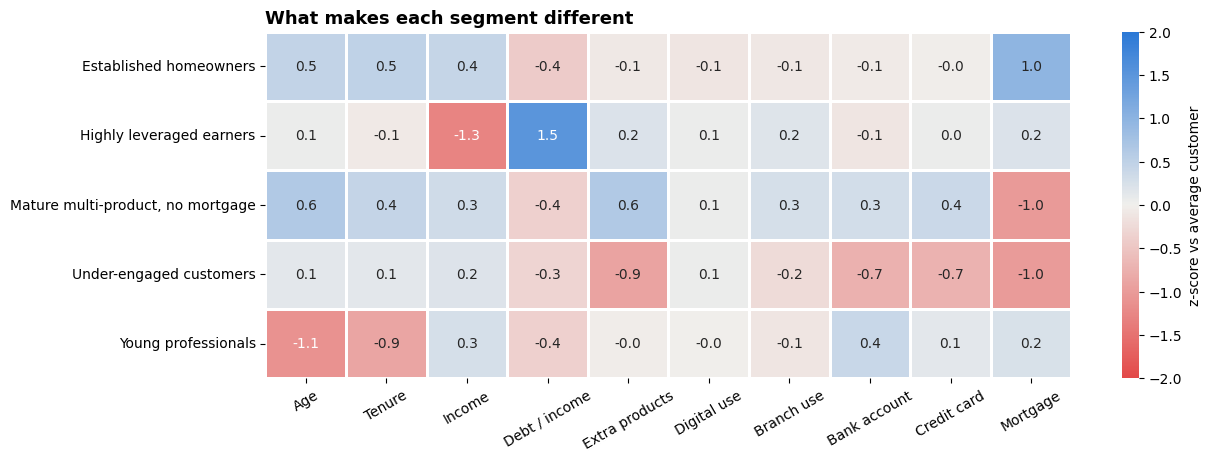

Saved: 11_segments_pca.png


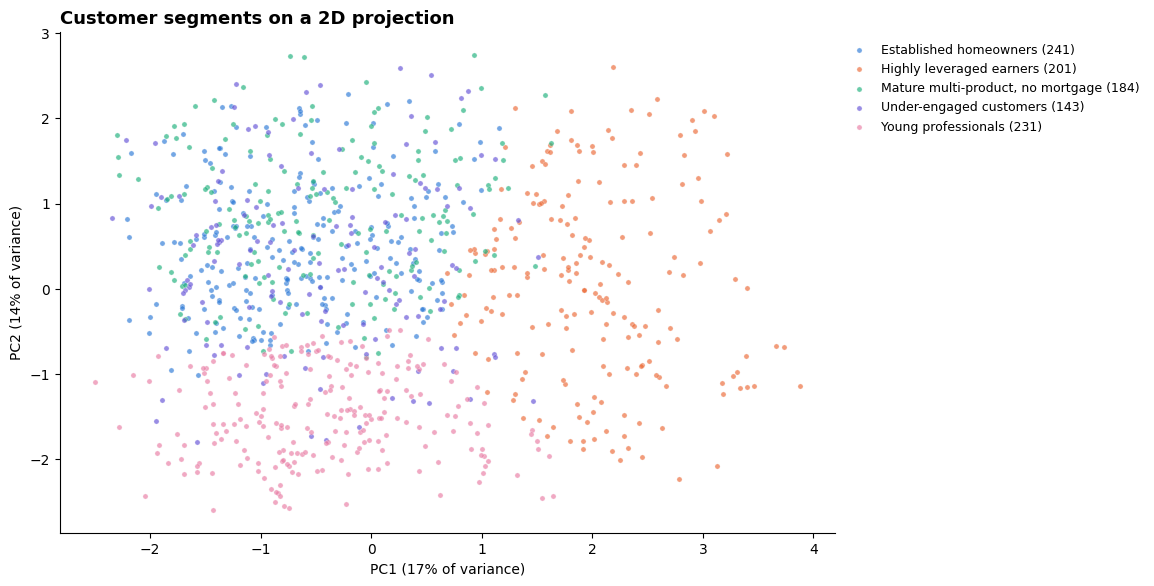

Agreement with/without outliers (ARI): 0.97
Agreement K-Means vs hierarchical Ward, K = 5 (ARI): 0.35


In [ ]:
from sklearn.decomposition import PCA

N_SEGMENTS = 5
kmeans = KMeans(n_clusters=N_SEGMENTS, n_init=20, random_state=SEED).fit(X_cluster)
df["segment_id"] = kmeans.labels_

# --- Profile each segment in business units ---
segment_profile = df.groupby("segment_id").agg(
    customers=("client_id", "size"),
    age_median=("client_age", "median"),
    tenure_median=("tenure_years", "median"),
    income_median=("customer_income", "median"),
    debt_median=("customer_debt", "median"),
    dti_median=("debt_to_income", "median"),
    pct_bank_account=("bank_account_bin", "mean"),
    pct_credit_card=("credit_card_bin", "mean"),
    pct_mortgage=("mortgage_bin", "mean"),
    core_products=("n_core_products", "mean"),
    extra_products=("extra_products", "mean"),
    digital_use=("digital_use_ord", "mean"),
    branch_use=("branch_use_ord", "mean"),
)

def name_segment(p: pd.Series) -> str:
    """Rule-based naming from the segment profile (robust to label order)."""
    if p["dti_median"] > 4:          return "Highly leveraged earners"
    if p["core_products"] < 0.6:     return "Under-engaged customers"
    if p["age_median"] < 35:         return "Young professionals"
    if p["pct_mortgage"] > 0.9:      return "Established homeowners"
    if p["pct_mortgage"] < 0.1:      return "Mature multi-product, no mortgage"
    return f"Segment {p.name}"

SEGMENT_NAMES = segment_profile.apply(name_segment, axis=1)
assert SEGMENT_NAMES.is_unique, "Two segments got the same name — review the profile rules"
df["segment"] = df["segment_id"].map(SEGMENT_NAMES)
segment_profile.index = segment_profile.index.map(SEGMENT_NAMES).rename("segment")
display(segment_profile.round(2))

# --- Heatmap: how each segment deviates from the average customer (z-scores) ---
z_profile = (df.groupby("segment")[CLUSTER_FEATURES].mean() - df[CLUSTER_FEATURES].mean()) / df[CLUSTER_FEATURES].std()
FEATURE_LABELS = {"client_age": "Age", "tenure_years": "Tenure", "customer_income": "Income",
                  "log_debt_to_income": "Debt / income", "extra_products": "Extra products",
                  "digital_use_ord": "Digital use", "branch_use_ord": "Branch use",
                  "bank_account_bin": "Bank account", "credit_card_bin": "Credit card",
                  "mortgage_bin": "Mortgage"}
fig, ax = plt.subplots(figsize=(13, 4.5))
sns.heatmap(z_profile.rename(columns=FEATURE_LABELS), cmap=DIVERGING_CMAP, center=0, vmin=-2, vmax=2,
            annot=True, fmt=".1f", linewidths=2, linecolor="white",
            cbar_kws={"label": "z-score vs average customer"}, ax=ax)
ax.set_xlabel(""); ax.set_ylabel(""); ax.tick_params(axis="x", rotation=30)
ax.set_title("What makes each segment different", loc="left", fontsize=13, fontweight="bold")
save_fig(fig, "11_segment_profiles")
plt.show()

# --- 2D map of the segments (PCA, for visualization only) ---
SEGMENT_COLORS = dict(zip(sorted(SEGMENT_NAMES), ["#2a78d6", "#eb6834", "#1baf7a", "#6250d6", "#e87ba4"]))
pca = PCA(n_components=2, random_state=SEED)
coords = pca.fit_transform(X_cluster)
fig, ax = plt.subplots(figsize=(10, 6.5))
for name in sorted(SEGMENT_NAMES):
    m = df["segment"] == name
    ax.scatter(coords[m, 0], coords[m, 1], s=14, alpha=0.65, color=SEGMENT_COLORS[name],
               edgecolor="white", linewidth=0.3, label=f"{name} ({m.sum()})")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} of variance)")
ax.legend(frameon=False, fontsize=9, loc="upper left", bbox_to_anchor=(1, 1))
ax.set_title("Customer segments on a 2D projection", loc="left", fontsize=13, fontweight="bold")
sns.despine()
save_fig(fig, "11_segments_pca")
plt.show()

# --- Sensitivity check: refit without the 30 multivariate outliers flagged in 2.8 ---
mask = df["iso_outlier"] == 0
km_no_out = KMeans(n_clusters=N_SEGMENTS, n_init=20, random_state=SEED).fit(X_cluster[mask])
ari_outliers = adjusted_rand_score(df["segment_id"], km_no_out.predict(X_cluster))
print(f"Agreement with/without outliers (ARI): {ari_outliers:.2f}")

# --- Consistency check: does hierarchical clustering (Ward) find similar groups? ---
ward_labels = AgglomerativeClustering(n_clusters=N_SEGMENTS, linkage="ward").fit_predict(X_cluster)
ari_ward = adjusted_rand_score(df["segment_id"], ward_labels)
print(f"Agreement K-Means vs hierarchical Ward, K = 5 (ARI): {ari_ward:.2f}")

## 11.2 - Sentiment and offers by segment

,avg_stars,pct_dissatisfied,Dissatisfied,Satisfied (passive),Very satisfied
segment,,,,,
Established homeowners,4.12,22.41,22.40,20.30,57.30
Highly leveraged earners,4.12,20.90,20.90,25.40,53.70
"Mature multi-product, no mortgage",4.10,25.00,25.00,14.70,60.30
Under-engaged customers,4.30,18.18,18.20,15.40,66.40
Young professionals,4.26,19.05,19.00,17.30,63.60


Satisfaction vs segment: chi-square p = 0.10
Saved: 11_segment_satisfaction.png


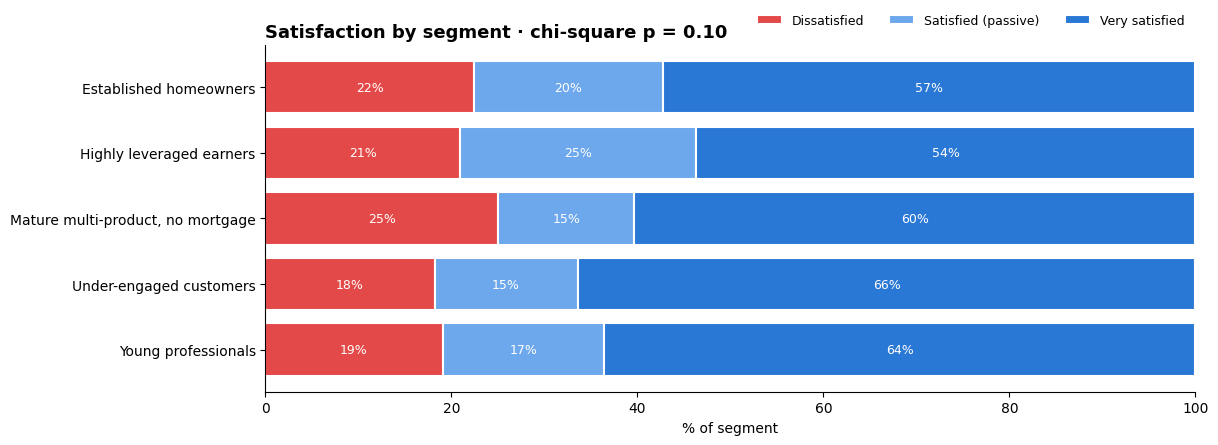

,customers,avg_stars,pct_dissatisfied,top_complaint,top_praise,recommended_offer
segment,,,,,,
Highly leveraged earners,201,4.12,20.90,Digital & mobile (29%),Digital & mobile (41%),Debt consolidation / refinancing at a lower rate + financial-health coaching; avoid new credit lines
Young professionals,231,4.26,19.00,Digital & mobile (30%),Digital & mobile (35%),"Rewards credit card upgrade, first-home mortgage pre-approval and automated savings/investing"
"Mature multi-product, no mortgage",184,4.10,25.00,Digital & mobile (22%),Digital & mobile (41%),"Wealth management, retirement planning and premium card"
Under-engaged customers,143,4.30,18.20,Fraud & security (19%),Digital & mobile (42%),"Starter bundle: no-fee checking account + entry credit card, with digital onboarding incentives"
Established homeowners,241,4.12,22.40,Digital & mobile (24%),Digital & mobile (41%),"Mortgage refinancing, home insurance and home-equity line of credit"


In [ ]:
# --- Satisfaction inside each segment ---
seg_sat = (pd.crosstab(df["segment"], df["satisfaction_level"], normalize="index")
             .reindex(columns=PRESENT_LEVELS) * 100)
seg_kpis = df.groupby("segment").agg(avg_stars=("satisfaction_stars", "mean"),
                                     pct_dissatisfied=("satisfaction_stars", lambda s: (s <= 2).mean() * 100))
p_seg = chi2_contingency(pd.crosstab(df["segment"], df["satisfaction_stars"]))[1]
display(seg_kpis.join(seg_sat.round(1)).round(2))
print(f"Satisfaction vs segment: chi-square p = {p_seg:.2f}")

# Top complaint per segment (dissatisfied customers only)
top_complaint = (df[df["satisfaction_stars"] <= 2].groupby("segment")["main_reason"]
                   .agg(lambda s: f"{s.value_counts().index[0]} ({s.value_counts(normalize=True).iloc[0]:.0%})"))
top_praise = (df[df["satisfaction_stars"] == 5].groupby("segment")["main_reason"]
                .agg(lambda s: f"{s.value_counts().index[0]} ({s.value_counts(normalize=True).iloc[0]:.0%})"))

fig, ax = plt.subplots(figsize=(12, 4.5))
left = np.zeros(len(seg_sat))
for level in PRESENT_LEVELS:
    ax.barh(seg_sat.index, seg_sat[level], left=left, color=SATISFACTION_COLORS[level],
            edgecolor="white", linewidth=1.5, label=level)
    for i, (l, v) in enumerate(zip(left, seg_sat[level])):
        ax.text(l + v / 2, i, f"{v:.0f}%", ha="center", va="center", fontsize=9, color="white")
    left += seg_sat[level].values
ax.set_xlim(0, 100); ax.invert_yaxis(); ax.set_xlabel("% of segment")
ax.legend(frameon=False, ncol=3, loc="lower right", bbox_to_anchor=(1, 1.02), fontsize=9)
ax.set_title(f"Satisfaction by segment · chi-square p = {p_seg:.2f}", loc="left", fontsize=13, fontweight="bold")
sns.despine(); ax.grid(False)
save_fig(fig, "11_segment_satisfaction")
plt.show()

# --- Product offer per segment ---
OFFERS = {
    "Highly leveraged earners":          "Debt consolidation / refinancing at a lower rate + financial-health coaching; avoid new credit lines",
    "Under-engaged customers":           "Starter bundle: no-fee checking account + entry credit card, with digital onboarding incentives",
    "Young professionals":               "Rewards credit card upgrade, first-home mortgage pre-approval and automated savings/investing",
    "Established homeowners":            "Mortgage refinancing, home insurance and home-equity line of credit",
    "Mature multi-product, no mortgage": "Wealth management, retirement planning and premium card",
}
segment_offers = pd.DataFrame({
    "customers": df["segment"].value_counts(),
    "avg_stars": seg_kpis["avg_stars"].round(2),
    "pct_dissatisfied": seg_kpis["pct_dissatisfied"].round(1),
    "top_complaint": top_complaint,
    "top_praise": top_praise,
    "recommended_offer": pd.Series(OFFERS),
}).reindex(segment_profile.index)
display(segment_offers)
segment_offers.to_csv(REPORTS_DIR / "segment_offers.csv")
df.to_parquet(PROCESSED_DIR / "customers_segmented.parquet", index=False)

### Findings — segments

| Segment | Size | Profile | Recommended offer |
|---|---|---|---|
| **Young professionals** | 231 (23%) | Median age 27, 5 years with the bank, income $152k, low leverage (1.5x) | Rewards credit card, first-home mortgage pre-approval, automated savings/investing |
| **Established homeowners** | 241 (24%) | Age 59, 20 years with the bank, all hold a mortgage, income $172k | Refinancing, home insurance, home-equity line |
| **Mature multi-product, no mortgage** | 184 (18%) | Age 64, the most extra products (2.2), no mortgage | Wealth management, retirement planning, premium card |
| **Highly leveraged earners** | 201 (20%) | Income $44k with debt of 7.6x income | Debt consolidation / refinancing and financial coaching — **no new credit** |
| **Under-engaged customers** | 143 (14%) | Almost no products (0.4 on average); includes 100 of the 111 zero-product customers | Starter bundle: checking account + entry card with digital onboarding |

**Sentiment by segment.** Satisfaction does not differ significantly between segments (chi-square p = 0.10). Under-engaged customers (66% very satisfied) and young professionals (64%) are the most satisfied; *Mature multi-product* has the highest share of dissatisfied customers (25%) and *Highly leveraged earners* the most passives (25%). *Digital & mobile* is the main complaint in four of the five segments; under-engaged customers complain mostly about *Fraud & security*.

# 12 - Trained model saved and ready to assign new customers

The fitted scaler + K-Means are saved as one `joblib` artifact together with the feature list, segment names and offers. A standalone module, `segment_assigner.py`, replicates the cleaning and feature-engineering rules (Modules 2 and 4), so a new customer in the **raw format of the source file** can be scored outside this notebook:

```python
from segment_assigner import assign_segment
assign_segment(new_customers_df, "segmentation_kmeans_v1.joblib")
```

## 12.1 - Save and verify the pipeline

In [ ]:
import joblib
from sklearn.pipeline import Pipeline

# Bundle the fitted scaler + K-Means into one pipeline, plus everything needed to interpret it
segmentation_pipeline = Pipeline([("scaler", scaler), ("kmeans", kmeans)])
artifact = {
    "pipeline": segmentation_pipeline,
    "features": CLUSTER_FEATURES,
    "segment_names": SEGMENT_NAMES.to_dict(),
    "offers": OFFERS,
    "reference_year": REFERENCE_YEAR,
    "trained_on": f"{len(df)} customers",
}
MODEL_PATH = MODELS_DIR / "segmentation_kmeans_v1.joblib"
joblib.dump(artifact, MODEL_PATH)

# Sanity check: the saved pipeline reproduces the training labels exactly
reloaded = joblib.load(MODEL_PATH)
assert (reloaded["pipeline"].predict(df[CLUSTER_FEATURES].astype(float)) == df["segment_id"]).all()
print(f"Model saved and verified: {MODEL_PATH.name}")

Model saved and verified: segmentation_kmeans_v1.joblib


## 12.2 - Standalone assignment module

In [ ]:
# Write a standalone module so the model can be used outside this notebook
ASSIGNER_CODE = r'''"""
Assign new bank customers to a segment using the saved K-Means pipeline.

Usage:
    from segment_assigner import assign_segment
    result = assign_segment(new_customers_df, "segmentation_kmeans_v1.joblib")
Input columns (raw format, same as the source file):
    client_age, customer_since, bank_account, credit_card, mortgage,
    total_number_of_products, customer_income, customer_debt,
    use_of_digital_channels, use_of_branches
"""
import joblib
import numpy as np
import pandas as pd

BINARY_MAP = {"no": 0, "yes": 1}
ORDINAL_MAP = {"low": 0, "medium": 1, "high": 2}


def build_features(raw: pd.DataFrame, reference_year: int) -> pd.DataFrame:
    """Replicate the cleaning and feature engineering of Modules 2 and 4."""
    d = raw.copy()
    for c in ["bank_account", "credit_card", "mortgage", "use_of_digital_channels", "use_of_branches"]:
        d[c] = d[c].astype(str).str.strip().str.lower()
    for c in ["bank_account", "credit_card", "mortgage"]:
        d[f"{c}_bin"] = d[c].map(BINARY_MAP)
    d["digital_use_ord"] = d["use_of_digital_channels"].map(ORDINAL_MAP)
    d["branch_use_ord"] = d["use_of_branches"].map(ORDINAL_MAP)
    d["n_core_products"] = d[["bank_account_bin", "credit_card_bin", "mortgage_bin"]].sum(axis=1)
    # Rule 2.6b: total products can never be lower than the core products held
    d["total_number_of_products"] = np.maximum(d["total_number_of_products"], d["n_core_products"])
    d["extra_products"] = d["total_number_of_products"] - d["n_core_products"]
    d["tenure_years"] = reference_year - d["customer_since"]
    d["log_debt_to_income"] = np.log1p(d["customer_debt"] / d["customer_income"])
    return d


def assign_segment(raw: pd.DataFrame, model_path: str) -> pd.DataFrame:
    """Return the input with segment id, segment name and recommended offer."""
    artifact = joblib.load(model_path)
    d = build_features(raw, artifact["reference_year"])
    missing = d[artifact["features"]].isna().any(axis=1)
    if missing.any():
        raise ValueError(f"{missing.sum()} rows have missing or unmapped values")
    ids = artifact["pipeline"].predict(d[artifact["features"]].astype(float))
    out = raw.copy()
    out["segment_id"] = ids
    out["segment"] = pd.Series(ids, index=raw.index).map(artifact["segment_names"])
    out["recommended_offer"] = out["segment"].map(artifact["offers"])
    return out
'''
(MODELS_DIR / "segment_assigner.py").write_text(ASSIGNER_CODE)
print("Saved: segment_assigner.py")

Saved: segment_assigner.py


## 12.3 - Test with new customers

In [ ]:
import sys, importlib
sys.path.append(str(MODELS_DIR))
import segment_assigner
importlib.reload(segment_assigner)

# Three fictitious new customers, in the raw format of the source file
new_customers = pd.DataFrame([
    {"client_age": 26, "customer_since": 2023, "bank_account": "yes", "credit_card": "no",  "mortgage": "no",
     "total_number_of_products": 1, "customer_income": 120_000, "customer_debt": 90_000,
     "use_of_digital_channels": "high", "use_of_branches": "low"},
    {"client_age": 48, "customer_since": 2010, "bank_account": "yes", "credit_card": "yes", "mortgage": "yes",
     "total_number_of_products": 4, "customer_income": 35_000, "customer_debt": 300_000,
     "use_of_digital_channels": "medium", "use_of_branches": "high"},
    {"client_age": 63, "customer_since": 2001, "bank_account": "no",  "credit_card": "no",  "mortgage": "yes",
     "total_number_of_products": 2, "customer_income": 190_000, "customer_debt": 250_000,
     "use_of_digital_channels": "low", "use_of_branches": "medium"},
])
assigned = segment_assigner.assign_segment(new_customers, MODELS_DIR / "segmentation_kmeans_v1.joblib")
display(assigned[["client_age", "customer_income", "customer_debt", "mortgage", "segment", "recommended_offer"]])

,client_age,customer_income,customer_debt,mortgage,segment,recommended_offer
0,26,120000,90000,no,Young professionals,"Rewards credit card upgrade, first-home mortgage pre-approval and automated savings/investing"
1,48,35000,300000,yes,Highly leveraged earners,Debt consolidation / refinancing at a lower rate + financial-health coaching; avoid new credit lines
2,63,190000,250000,yes,Established homeowners,"Mortgage refinancing, home insurance and home-equity line of credit"


# 13 - Executive report · Part 1: Customer segmentation

**Objective.** Group the 1,000 customers of Chase, Bank of America and Wells Fargo into homogeneous segments to send each one a financial-product offer that matches its needs, and report how each segment feels about its bank.

**Data quality.** The dataset was complete (no nulls, no duplicates). 5 debt values corrupted by Excel date formatting were imputed (0.5%), 138 product totals lower than the products held were corrected, and 111 customers with debt but no registered products were kept and flagged. Every decision is documented in the cleaning audit log; the raw file was never modified (MD5 check).

**What the data looks like.** Customer attributes are uniformly distributed and independent of each other, and the three banks serve the same type of customer. As a consequence there are no strong natural groups (silhouette ≈ 0.10): segments are a practical partition built on combinations of variables.

**Method.** 10 variables describing life stage, financial capacity, products held and channel use; three algorithms compared — K-Means, hierarchical clustering (Ward, average and complete linkage) and DBSCAN. DBSCAN found no dense groups (one cluster or only noise), confirming the absence of natural clusters. **K-Means with 5 segments** was selected for its metrics, interpretability, robustness to outliers and its ability to assign new customers.

**Segments and offers**

| Segment | Customers | Satisfaction (avg ★ · % dissatisfied) | Offer |
|---|---|---|---|
| Established homeowners | 241 | 4.12 · 22% | Refinancing, home insurance, home-equity line |
| Young professionals | 231 | 4.26 · 19% | Rewards card, first-home mortgage, automated investing |
| Highly leveraged earners | 201 | 4.12 · 21% | Debt consolidation + financial coaching (no new credit) |
| Mature multi-product, no mortgage | 184 | 4.10 · 25% | Wealth management, retirement planning |
| Under-engaged customers | 143 | 4.30 · 18% | Starter bundle with digital onboarding |

**Recommendations**
1. **Prioritize by value and risk:** start with young professionals (growth) and established homeowners (retention of high-income customers).
2. **Protect the highly leveraged segment:** offering more credit to customers whose debt is 7.6x their income increases default risk; offer relief instead.
3. **Activate the under-engaged:** 14% of customers hold almost no products but are among the most satisfied — the easiest cross-sell.
4. **Fix the app before campaigning:** *Digital & mobile* is the main complaint in four of five segments; campaigns delivered through a failing app will lose impact.

**Deliverable.** The trained model (`segmentation_kmeans_v1.joblib` + `segment_assigner.py`) assigns any new customer to a segment and returns its recommended offer.

**Limitations.** Weak cluster structure and moderate stability (ARI ≈ 0.42); the near-perfect uniformity of the data suggests a synthetic dataset, so results demonstrate the approach rather than describe a real market.

# 14 - Executive report · Part 2: Customer satisfaction

**Objective.** Measure how satisfied customers are with their bank, why, and whether satisfaction varies with other customer characteristics.

**How the messages were processed.** The 1,000 messages are built from 3 templates (tone) plus a variable topic phrase (reason); only 30 are unique. Text was cleaned (contractions expanded, negations kept), the topic phrase was extracted with rules, and three pre-trained sentiment models were compared without any training on this data. The template was used only to **validate** the models.

**Satisfaction level.** The 5-star review model was selected: it ranks every message correctly and separates the groups with the widest margin.

| Level | Customers | Share |
|---|---|---|
| ★★★★★ Very satisfied | 599 | 60% |
| ★★★★ Satisfied (passive) | 189 | 19% |
| ★★ Dissatisfied | 212 | 21% |

Average: **4.17★**. Nobody is neutral or extremely dissatisfied.

**Main reasons**
- **Delight** comes from digital convenience (40% of very satisfied customers), helpful financial advice (20%) and efficient fraud protection.
- **Dissatisfaction** comes from an unreliable app and crashes during payment (24%), confusing mortgage and loan processes (17%), poor loyalty offers, slow fraud resolution, long branch lines and hidden fees.
- **Passive customers** describe an app that works but glitches, standard card offers and an ordinary mortgage process.
- The app is the #1 reason at every level: its reliability decides whether a customer is delighted or frustrated.

**Characterization.** Satisfaction does not depend on age, income, debt, tenure, products, channel use or bank (all p > 0.10). The three banks score 4.14–4.20★; they differ only in what their dissatisfied customers complain about (Bank of America: fees and mortgages; Wells Fargo: credit cards; Chase: digital).

**Recommendations**
1. **App reliability first:** fixing payment crashes addresses the largest complaint and protects the largest source of delight.
2. **Convert the 19% passive customers:** upgrade generic card offers and simplify the mortgage journey — they are content but the most exposed to competitors.
3. **Remove pure friction:** hidden fees and branch queues only generate dissatisfaction; transparent pricing and queue management are quick wins.
4. **Scale what works:** financial advice and fraud protection drive delight; make them visible in campaigns.
5. **Monitor continuously:** apply the same pipeline to new messages and track the share of passive customers as a leading churn indicator.

**Limitations.** Template-based text (30 unique messages) makes the validation unusually clean; with real, free-text reviews, accuracy would be lower and the topic-extraction rules would need to be replaced by the embedding clustering of Module 7.

# 15 - Final export and integrity check

In [ ]:
# Final export + integrity check
FINAL_COLS = ["client_id", "bank", "city", "client_age", "tenure_years", "customer_income", "customer_debt",
              "debt_to_income", "n_core_products", "extra_products", "use_of_digital_channels",
              "use_of_branches", "topic_phrase", "main_reason", "satisfaction_stars",
              "satisfaction_level", "segment"]
df[FINAL_COLS].to_csv(PROCESSED_DIR / "customers_final.csv", index=False)

assert file_md5(RAW_XLSX) == RAW_MD5, "Raw file was modified!"
print(f"Final dataset: {df[FINAL_COLS].shape} | Raw file integrity: OK")
print("Figures:", len(list(FIGURES_DIR.glob('*.png'))), "| Reports:", len(list(REPORTS_DIR.iterdir())),
      "| Models:", [p.name for p in MODELS_DIR.iterdir()])

Final dataset: (1000, 17) | Raw file integrity: OK
Figures: 19 | Reports: 7 | Models: ['segmentation_kmeans_v1.joblib', 'segment_assigner.py', '__pycache__']
